In [1]:
# ========================
# CORE LIBRARIES
# ========================
import numpy as np
import pandas as pd

# ========================
# VISUALIZATION
# ========================
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.dates import DateFormatter

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# ========================
# PREPROCESSING
# ========================
from sklearn.preprocessing import MinMaxScaler

# ========================
# VMD
# ========================
!pip install vmdpy
from vmdpy import VMD
from scipy.stats import pearsonr

# ========================
# OPTIMIZATION
# ========================
!pip install optuna
import optuna

# ========================
# DEEP LEARNING
# ========================
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# ========================
# EVALUATION
# ========================
from sklearn.metrics import mean_absolute_error, mean_squared_error

#ADD
import json
import os
import joblib
import gc
import warnings
import warnings
warnings.filterwarnings('ignore')

In [2]:
import glob
import os
import pandas as pd

# Cari file .xlsx secara otomatis di direktori Kaggle maupun direktori lokal
file_paths = glob.glob('/kaggle/input/**/*.xlsx', recursive=True) or glob.glob(
    '*.xlsx'
)

if file_paths:
  # Mengambil file Excel pertama yang ditemukan
  file_path = file_paths[0]
  print(f"File ditemukan di: {file_path}")

  try:
    df = pd.read_excel(file_path)
    print(" Data berhasil dimuat!")
    print(f"Shape data: {df.shape}")
    print("\nInfo data:")
    print(df.info())
  except Exception as e:
    print(f"Error loading data: {e}")
else:
  print(" File Excel (.xlsx) tidak ditemukan!")

File ditemukan di: /kaggle/input/datasets/alvyanmaulana/sunancendaana/makam sunan cendana.xlsx
 Data berhasil dimuat!
Shape data: (108, 4)

Info data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Makam Sunan Cendana  0 non-null      float64
 1   Bulan                108 non-null    object 
 2   Tahun                108 non-null    int64  
 3   Pengunjung           108 non-null    int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 3.5+ KB
None


In [3]:
#Tampilkan Prevuew Data
print("Preview data (5 baris pertama):")
display(df.head())

print("\n Preview data (5 baris terakhir):")
display(df.tail())

print("\n Nama kolom:")
print(df.columns.tolist())

Preview data (5 baris pertama):


,Makam Sunan Cendana,Bulan,Tahun,Pengunjung
0,NaN,Januari,2017,0
1,NaN,Februari,2017,115
2,NaN,Maret,2017,97
3,NaN,April,2017,115
4,NaN,Mei,2017,125



 Preview data (5 baris terakhir):


,Makam Sunan Cendana,Bulan,Tahun,Pengunjung
103,NaN,Agustus,2025,495
104,NaN,September,2025,505
105,NaN,Oktober,2025,485
106,NaN,November,2025,828
107,NaN,Desember,2025,1281



 Nama kolom:
['Makam Sunan Cendana', 'Bulan', 'Tahun', 'Pengunjung']


In [4]:
# ------------------------------------------------------------------
# Dataset asli (sayaicona_cholil_dataset.xlsx) punya kolom:
#   - 'Destinasi'  : hanya terisi di baris pertama (nama objek wisata)
#   - 'Bulan'      : nama bulan dalam Bahasa Indonesia (Januari, Februari, ...)
#   - 'Tahun'      : hanya terisi di baris Januari tiap tahun (baris lain NaN)
#   - 'Pengunjung' : jumlah pengunjung (kolom target)
# Jadi kita perlu (1) isi kolom Tahun yang kosong, dan
# (2) gabungkan Bulan + Tahun menjadi satu kolom tanggal (datetime).
# ------------------------------------------------------------------

visitor_col = 'Pengunjung'

# 1) Isi tahun yang kosong (forward fill), karena hanya baris Januari
#    tiap tahun yang punya nilai Tahun
df['Tahun'] = df['Tahun'].ffill().astype(int)

# 2) Mapping nama bulan Indonesia -> nomor bulan
bulan_map = {
    'Januari': 1, 'Februari': 2, 'Maret': 3, 'April': 4,
    'Mei': 5, 'Juni': 6, 'Juli': 7, 'Agustus': 8,
    'September': 9, 'Oktober': 10, 'November': 11, 'Desember': 12
}
df['Bulan_Num'] = df['Bulan'].astype(str).str.strip().map(bulan_map)

# Cek kalau ada nama bulan yang gagal termapping (safety check)
if df['Bulan_Num'].isna().any():
    print(" Bulan tidak dikenali:", df.loc[df['Bulan_Num'].isna(), 'Bulan'].unique())

# 3) Buat kolom tanggal (datetime) langsung dari Tahun + Bulan_Num
#    (lebih aman daripada parsing string '%B %Y', karena nama bulan
#    di dataset berbahasa Indonesia, bukan Inggris)
df['date'] = pd.to_datetime(
    dict(year=df['Tahun'], month=df['Bulan_Num'], day=1)
)

date_col = 'date'
print(f" Kolom periode: {date_col} (dibentuk dari Bulan + Tahun)")
print(f" Kolom pengunjung: {visitor_col}")

# Buat copy data untuk analisis
data = df[[date_col, visitor_col]].copy()
data.columns = ['date', 'visitors']
data = data.sort_values('date').reset_index(drop=True)

print("\n Data setelah rename:")
display(data.head())

print(f"\n Didapatkan data dengan jumlah titik {len(data)} observasi")


 Kolom periode: date (dibentuk dari Bulan + Tahun)
 Kolom pengunjung: Pengunjung

 Data setelah rename:


,date,visitors
0,2017-01-01,0
1,2017-02-01,115
2,2017-03-01,97
3,2017-04-01,115
4,2017-05-01,125



 Didapatkan data dengan jumlah titik 108 observasi


In [5]:
#Mendeteksi nilai 0 pada kolom visitors 
zero_count = (data['visitors'] == 0).sum()
print(f"\n NILAI 0 TERDETEKSI:")
print(f" Total nilai 0: {zero_count}")
if zero_count > 0:
    zero_months = data[data['visitors'] == 0]['date'].dt.strftime('%B %Y').tolist()
    print(f" Bulan dengan 0 pengunjung: {', '.join(zero_months)}")


 NILAI 0 TERDETEKSI:
 Total nilai 0: 13
 Bulan dengan 0 pengunjung: January 2017, June 2018, April 2020, May 2020, June 2020, July 2020, June 2021, July 2021, August 2021, September 2021, October 2021, November 2021, December 2021


In [6]:
#Logika Penanganan Nilai 0 
data_clean = data.copy()

# 'date' sudah dalam format datetime sejak cell sebelumnya, tidak perlu re-parse
data_clean = data_clean.sort_values('date').reset_index(drop=True)

#ganti 0 -> Nan
zero_count = (data_clean['visitors'] == 0).sum()
zero_percentage = zero_count / len(data_clean) * 100

print(f"\n STRATEGI PENANGANAN NILAI 0 - INTERPOLASI LINEAR:")
print(f" Nilai 0: {zero_count} ({zero_percentage:.1f}%)")

if zero_count > 0:
    print("Menggunakan interpolasi linear untuk menangani nilai 0...")

    # Tandai nilai 0 → NaN
    data_clean.loc[data_clean['visitors'] == 0, 'visitors'] = pd.NA

    # Interpolasi linear berdasarkan urutan waktu
    data_clean['visitors'] = data_clean['visitors'].interpolate(
        method='linear', 
        limit_direction='both'
    )

    imputed_df = data.loc[data['visitors'] == 0].copy()
    imputed_df['new_value'] = data_clean.loc[imputed_df.index, 'visitors']

    print(f"\n {len(imputed_df)} data telah diimputasi (0 → interpolasi linear):")
    print(imputed_df.head(10))  # tampilkan maksimal 10
    if len(imputed_df) > 10:
        print(f"... dan {len(imputed_df) - 10} data lainnya.")
else:
    print(" Tidak ada nilai 0 yang perlu ditangani.")

# Statistik setelah imputasi
print(f"\n Statistik data setelah cleaning:")
print(f" Missing values: {data_clean['visitors'].isnull().sum()}")
print(f" Nilai 0: {(data_clean['visitors'] == 0).sum()}")
print(f" Range: {data_clean['visitors'].min():.0f} - {data_clean['visitors'].max():.0f}")
print(f" Mean: {data_clean['visitors'].mean():.1f}")
print(f" Median: {data_clean['visitors'].median():.1f}")



 STRATEGI PENANGANAN NILAI 0 - INTERPOLASI LINEAR:
 Nilai 0: 13 (12.0%)
Menggunakan interpolasi linear untuk menangani nilai 0...

 13 data telah diimputasi (0 → interpolasi linear):
         date  visitors  new_value
0  2017-01-01         0    115.000
17 2018-06-01         0    145.000
39 2020-04-01         0    278.600
40 2020-05-01         0    320.200
41 2020-06-01         0    361.800
42 2020-07-01         0    403.400
53 2021-06-01         0    230.375
54 2021-07-01         0    199.750
55 2021-08-01         0    169.125
56 2021-09-01         0    138.500
... dan 3 data lainnya.

 Statistik data setelah cleaning:
 Missing values: 0
 Nilai 0: 0
 Range: 12 - 1500
 Mean: 285.4
 Median: 177.0


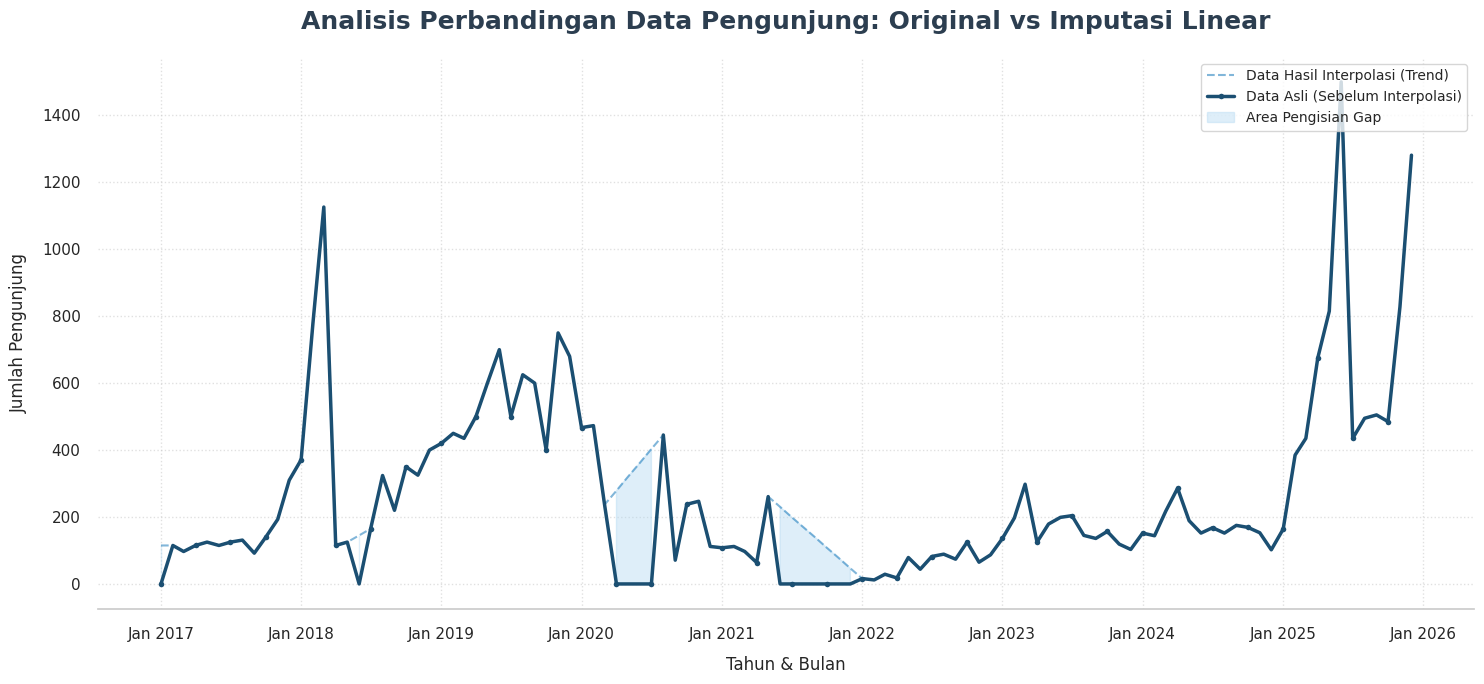

In [7]:
# Kedua kolom 'date' sudah berupa datetime, tidak perlu di-parse ulang

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'sans-serif'

fig, ax = plt.subplots(figsize=(15, 7), dpi=100)

ax.plot(
    data_clean['date'], 
    data_clean['visitors'], 
    label='Data Hasil Interpolasi (Trend)', 
    color='#2E86C1',
    linestyle='--', 
    linewidth=1.5,
    alpha=0.6
)

ax.plot(
    data['date'], 
    data['visitors'], 
    label='Data Asli (Sebelum Interpolasi)', 
    color='#1B4F72',
    linewidth=2.5,
    marker='o',
    markersize=4,
    markevery=3
)

ax.fill_between(
    data_clean['date'], 
    data['visitors'], 
    data_clean['visitors'], 
    where=(data['visitors'] == 0),
    color='#AED6F1', 
    alpha=0.4, 
    label='Area Pengisian Gap'
)

zero_indices = data.index[data['visitors'] == 0]


ax.set_title('Analisis Perbandingan Data Pengunjung: Original vs Imputasi Linear', 
             fontsize=18, fontweight='bold', pad=20, color='#2C3E50')
ax.set_xlabel('Tahun & Bulan', fontsize=12, labelpad=10)
ax.set_ylabel('Jumlah Pengunjung', fontsize=12, labelpad=10)

date_form = DateFormatter("%b %Y")
ax.xaxis.set_major_formatter(date_form)

sns.despine(left=True, bottom=False)

ax.legend(loc='upper right', frameon=True, facecolor='white', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [8]:
# ==================================================
# 1. SIMPAN DATA HASIL IMPUTASI (SKALA ASLI)
# ==================================================

output_folder_raw = "hasil-interpolasi"
os.makedirs(output_folder_raw, exist_ok=True)  # bikin folder kalau belum ada

output_file_raw = os.path.join(
    output_folder_raw,
    "data_cleaned_after_imputation.xlsx"
)

with pd.ExcelWriter(output_file_raw, engine="openpyxl") as writer:
    
    # simpan data utama setelah imputasi
    data_clean.to_excel(
        writer,
        sheet_name="cleaned_data",
        index=False
    )

    # simpan log imputasi (kalau ada nilai yang diganti)
    if zero_count > 0 and 'imputed_df' in locals() and len(imputed_df) > 0:
        imputed_df.to_excel(
            writer,
            sheet_name="imputation_log",
            index=False
        )

print(f"\nData interpolasi tersimpan di: {output_file_raw}")


# ==================================================
# 2. NORMALISASI MIN-MAX [0,1] & SIMPAN
# ==================================================

output_folder_norm = "normalisasi-hasil-interpolasi"
os.makedirs(output_folder_norm, exist_ok=True)  # folder hasil normalisasi

output_file_norm = os.path.join(
    output_folder_norm,
    "data_cleaned_after_imputation_minmax_0_1.xlsx"
)

# copy data biar data asli gak keubah
data_norm = data_clean.copy()

target_col = "visitors"  # kolom yang dinormalisasi

scaler = MinMaxScaler(feature_range=(0, 1))

# fit + transform ke range 0-1
data_norm[target_col] = scaler.fit_transform(
    data_norm[[target_col]]
)

with pd.ExcelWriter(output_file_norm, engine="openpyxl") as writer:
    
    # simpan data hasil normalisasi
    data_norm.to_excel(
        writer,
        sheet_name="normalized_data",
        index=False
    )

    # simpan info scaler (buat inverse nanti)
    scaler_info = pd.DataFrame({
        "feature": [target_col],
        "min_value": scaler.data_min_,  
        "max_value": scaler.data_max_
    })
    scaler_info.to_excel(
        writer,
        sheet_name="scaler_info",
        index=False
    )

print(f"Data normalisasi tersimpan di: {output_file_norm}")


Data interpolasi tersimpan di: hasil-interpolasi/data_cleaned_after_imputation.xlsx
Data normalisasi tersimpan di: normalisasi-hasil-interpolasi/data_cleaned_after_imputation_minmax_0_1.xlsx


## Tahap Dekomposisi VMD

🚀 PROSES FINE-TUNING VMD (PERKECIL RANGE K <= 12 & ALPHA <= 2000)

--- Memulai Fine-tuning VMD untuk Visitors ---
Candidate K=2 | Alpha=2000 | Corr=0.01028 | ELC=0.17836 | BW=0.00056
Candidate K=3 | Alpha=2000 | Corr=0.02519 | ELC=0.10725 | BW=0.00095
Candidate K=4 | Alpha=2000 | Corr=0.03000 | ELC=0.09186 | BW=0.00080
Candidate K=5 | Alpha=100 | Corr=0.11565 | ELC=0.00164 | BW=0.00132
Candidate K=6 | Alpha=2000 | Corr=0.13895 | ELC=0.05250 | BW=0.00098
Candidate K=7 | Alpha=2000 | Corr=0.12937 | ELC=0.03718 | BW=0.00109
Candidate K=8 | Alpha=2000 | Corr=0.11704 | ELC=0.02181 | BW=0.00107
Candidate K=9 | Alpha=2000 | Corr=0.11604 | ELC=0.01780 | BW=0.00094
Candidate K=10 | Alpha=2000 | Corr=0.11375 | ELC=0.01429 | BW=0.00101
Candidate K=11 | Alpha=100 | Corr=0.11713 | ELC=0.00012 | BW=0.00086
Candidate K=12 | Alpha=100 | Corr=0.11687 | ELC=0.00012 | BW=0.00083

HASIL OPTIMAL VMD UNTUK Visitors:
K       : 12
Alpha   : 100
Corr    : 0.11687
ELC     : 0.00012
BW      : 0.00083


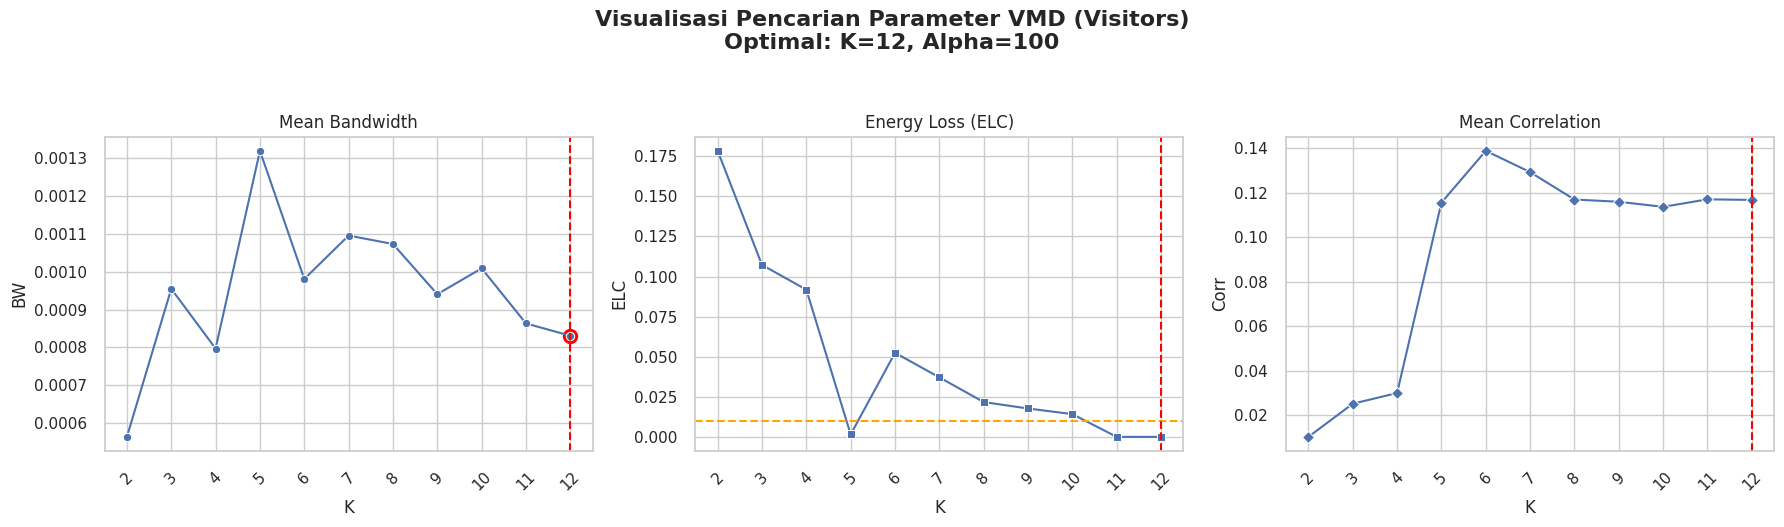

Plot hasil dekomposisi VMD untuk Visitors (K=12)


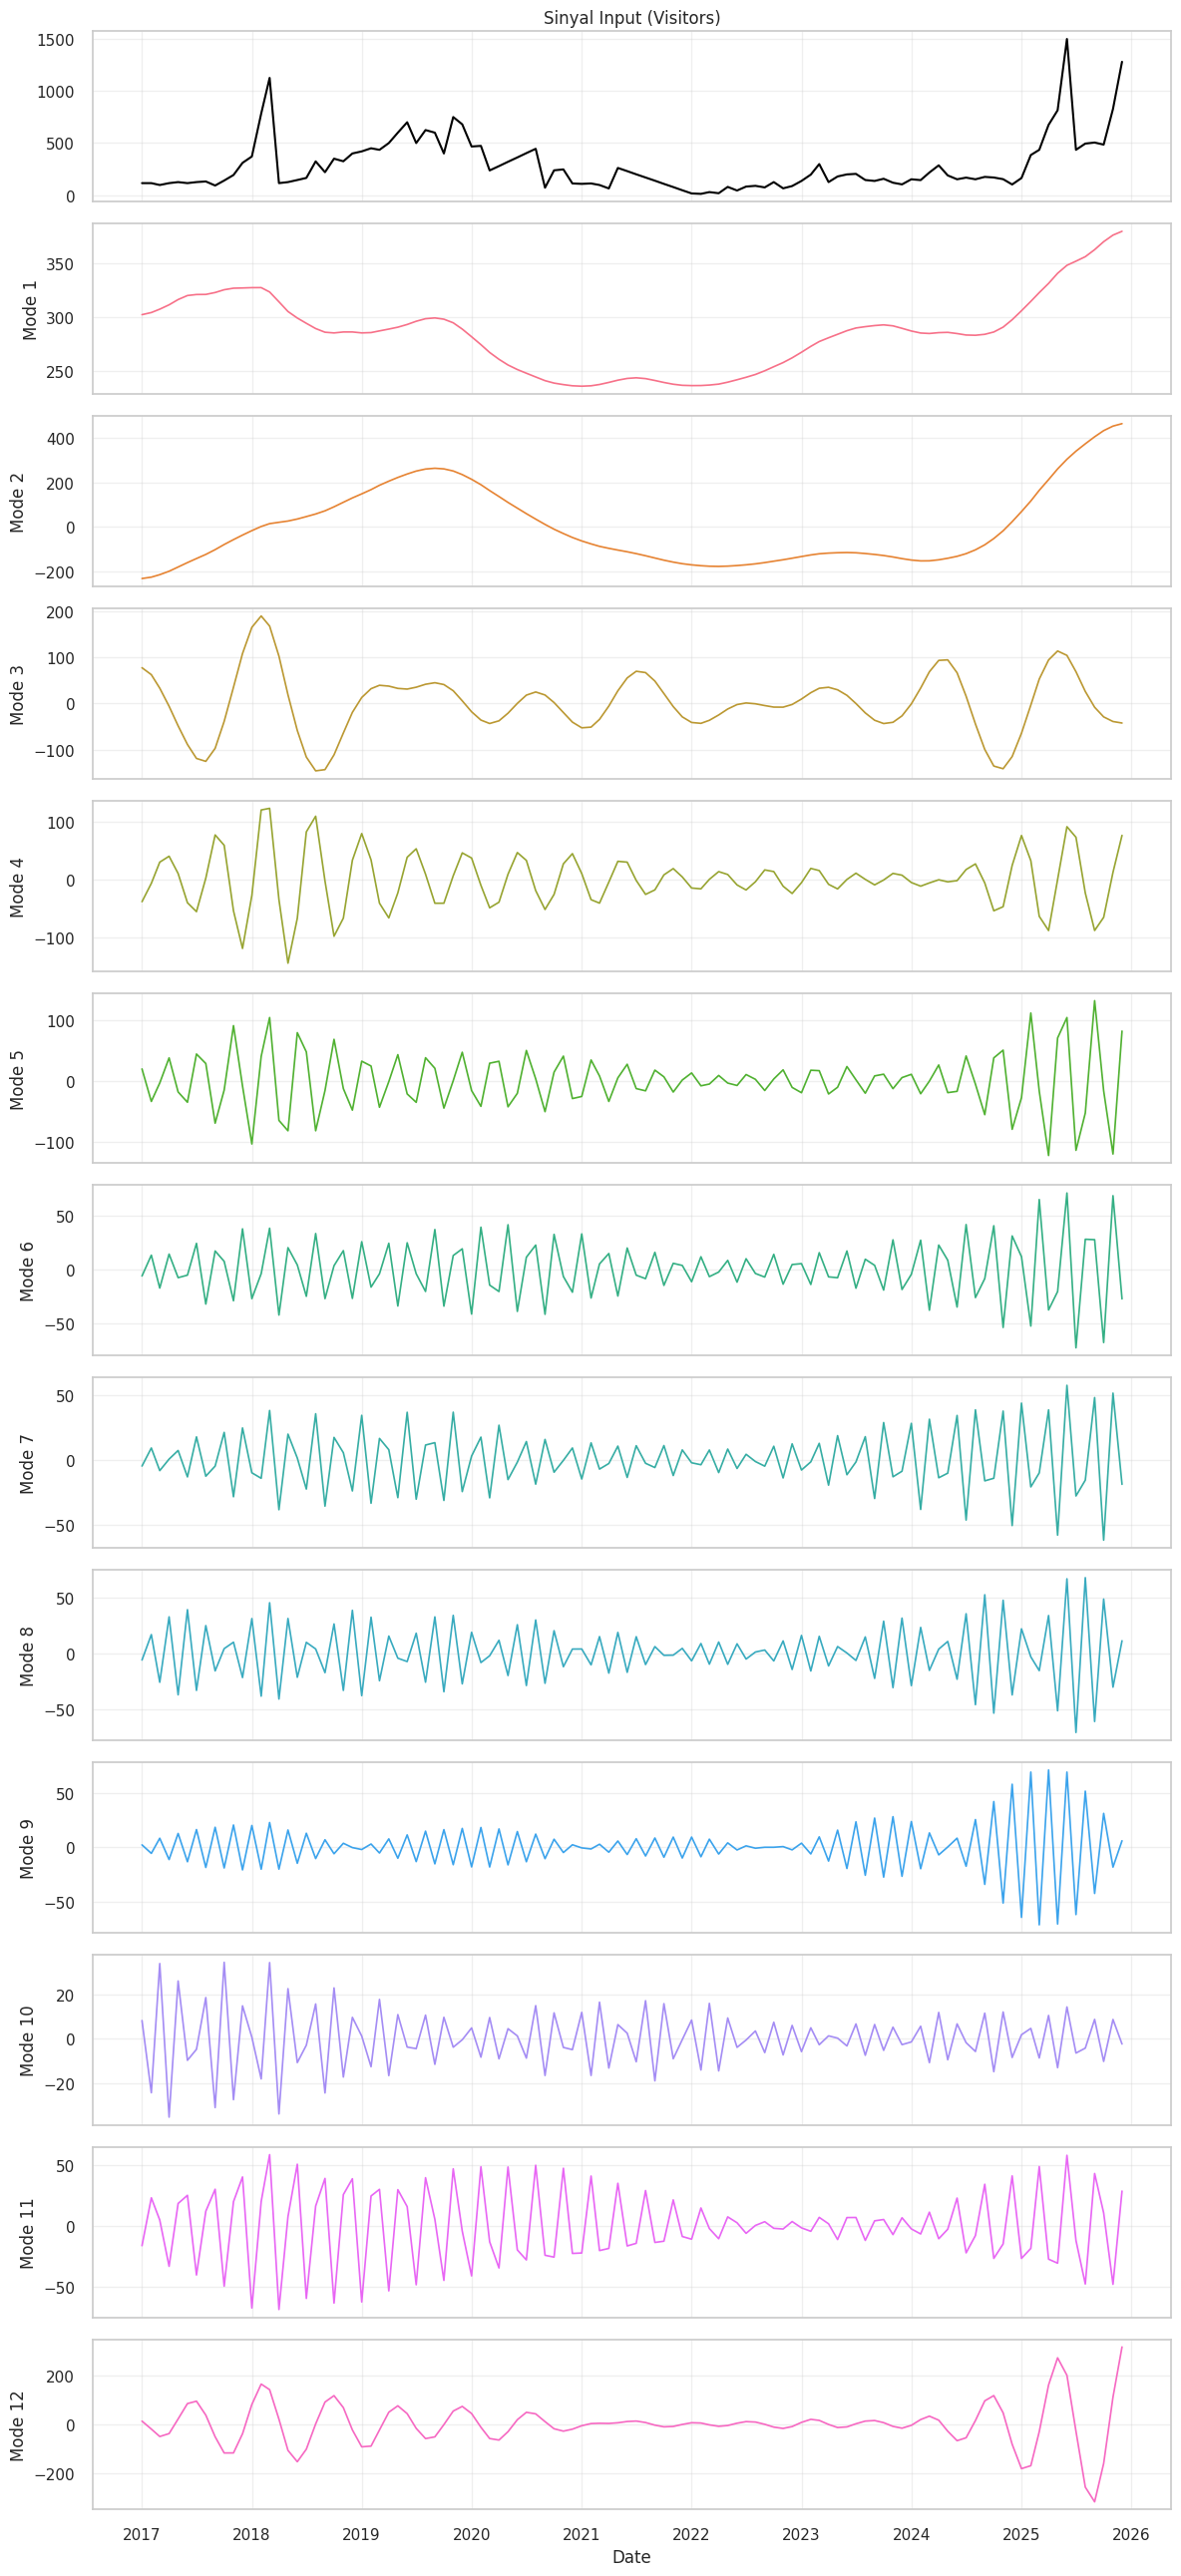


✅ PROSES DEKOMPOSISI VMD SELESAI (K <= 12)
Daftar Seluruh Komponen yang Dihasilkan:
['VMD_1', 'VMD_2', 'VMD_3', 'VMD_4', 'VMD_5', 'VMD_6', 'VMD_7', 'VMD_8', 'VMD_9', 'VMD_10', 'VMD_11', 'VMD_12', 'date']
Total komponen akhir VMD: 12 komponen
Daftar kolom komponen:
 - VMD_1
 - VMD_2
 - VMD_3
 - VMD_4
 - VMD_5
 - VMD_6
 - VMD_7
 - VMD_8
 - VMD_9
 - VMD_10
 - VMD_11
 - VMD_12

💾 Hasil dekomposisi VMD berhasil disimpan di folder: hasil-dekomposisi/
   - hasil-dekomposisi/imfs.csv
   - hasil-dekomposisi/imfs.pkl
   - hasil-dekomposisi/imfs_with_date.csv

💾 Excel lengkap VMD disimpan: hasil-dekomposisi/vmd_hasil_lengkap.xlsx
   Sheet: Pencarian_Parameter, Parameter_Optimal, Dekomposisi_VMD, Perhitungan_Manual_VMD


In [9]:
import os
import subprocess
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr

# ─── Install vmdpy jika belum ada ──────────────────────────────
try:
  from vmdpy import VMD
except ModuleNotFoundError:
  subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'vmdpy'])
  from vmdpy import VMD


# =========================================================
# FUNGSI METRIK EVALUASI VMD
# =========================================================
def get_vmd_metrics(f, u):
  K = u.shape[0]

  # 1. Korelasi antar mode (indikasi mode mixing)
  correlations = []
  for i in range(K - 1):
    corr, _ = pearsonr(u[i], u[i + 1])
    correlations.append(abs(corr))
  mean_corr = np.mean(correlations) if correlations else 0

  # 2. Error rekonstruksi (energy loss / ELC)
  reconstructed_signal = np.sum(u, axis=0)
  res = f - reconstructed_signal
  elc = np.sum(res**2) / np.sum(f**2)

  # 3. Bandwidth rata-rata tiap mode
  mode_bandwidths = []
  for i in range(K):
    mode_fft = np.fft.fft(u[i])
    psd = np.abs(mode_fft) ** 2
    freqs = np.fft.fftfreq(len(u[i]))

    pos_idx = freqs >= 0
    psd_pos = psd[pos_idx]
    freqs_pos = freqs[pos_idx]

    if np.sum(psd_pos) > 0:
      mean_f = np.sum(freqs_pos * psd_pos) / np.sum(psd_pos)
      var_f = np.sum(((freqs_pos - mean_f) ** 2) * psd_pos) / np.sum(psd_pos)
      mode_bandwidths.append(var_f)
    else:
      mode_bandwidths.append(0)

  mean_bw = np.mean(mode_bandwidths)

  return mean_corr, elc, mean_bw


# =========================================================
# PARAMETER DASAR VMD
# =========================================================
tau = 0.0
DC = 0
init = 1
tol = 1e-7

# Range pencarian diperkecil hingga K=12 dan Alpha hingga 2000
K_range = range(2, 13)  # K dari 2 sampai 12
alpha_range = range(100, 2100, 100)  # Alpha dari 100 sampai 2000
corr_threshold = 1.2

# Sinyal input VMD = data pengunjung hasil interpolasi 
f = data_clean['visitors'].astype(float).values
signal_name = 'Visitors'

# Tempat menyimpan semua hasil mode VMD
all_vmd_components = {}
vmd_summary_params = []

# ─── [TAMBAHAN] Tempat menyimpan SELURUH kandidat (K, Alpha) yang diuji,
#     untuk direkap lengkap ke Excel nantinya ──────────
all_candidates_records = []

print('=' * 65)
print('🚀 PROSES FINE-TUNING VMD (PERKECIL RANGE K <= 12 & ALPHA <= 2000)')
print('=' * 65)

# =========================================================
# PENCARIAN PARAMETER & DEKOMPOSISI VMD PADA SINYAL ASLI
# =========================================================

print(f'\n--- Memulai Fine-tuning VMD untuk {signal_name} ---')

candidates = []

for K in K_range:
  prev_corr = 999
  best_alpha_for_k = None
  best_metrics_for_k = None

  for alpha in alpha_range:
    u, u_hat, omega = VMD(f, alpha, tau, K, DC, init, tol)

    corr, elc, bw = get_vmd_metrics(f, u)

    if alpha > 100 and corr > (prev_corr * corr_threshold):
      break

    best_alpha_for_k = alpha
    best_metrics_for_k = (corr, elc, bw)
    prev_corr = corr

  if best_alpha_for_k is not None:
    candidates.append({
        'K': K,
        'alpha': best_alpha_for_k,
        'Corr': best_metrics_for_k[0],
        'ELC': best_metrics_for_k[1],
        'BW': best_metrics_for_k[2],
    })
    # ─── [TAMBAHAN] tandai kandidat ini dengan asal IMF-nya ─────
    candidates[-1]['Signal'] = signal_name

    corr_k, elc_k, bw_k = best_metrics_for_k

    print(
        f'Candidate K={K} | Alpha={best_alpha_for_k} | '
        f'Corr={corr_k:.5f} | ELC={elc_k:.5f} | BW={bw_k:.5f}'
    )

# Filter kandidat dengan ELC yang wajar
filtered_candidates = [c for c in candidates if c['ELC'] < 0.01]

if not filtered_candidates:
  print('Tidak ada kandidat ELC < 0.01, ambil terbaik dari seluruh list.')
  filtered_candidates = candidates

# SELEKSI HIERARKIS:
# 1. Bandwidth (BW) dibulatkan ke 5 desimal.
# 2. ELC terkecil.
# 3. Korelasi (Corr) terkecil.
best_vmd_params = min(
    filtered_candidates,
    key=lambda x: (round(x['BW'], 5), x['ELC'], x['Corr']),
)

print(f'\nHASIL OPTIMAL VMD UNTUK {signal_name}:')
print(f"K       : {best_vmd_params['K']}")
print(f"Alpha   : {best_vmd_params['alpha']}")
print(f"Corr    : {best_vmd_params['Corr']:.5f}")
print(f"ELC     : {best_vmd_params['ELC']:.5f}")
print(f"BW      : {best_vmd_params['BW']:.5f}")

# Simpan ringkasan parameter
vmd_summary_params.append({
    'Signal': signal_name,
    'K': best_vmd_params['K'],
    'Alpha': best_vmd_params['alpha'],
    'Corr': best_vmd_params['Corr'],
    'ELC': best_vmd_params['ELC'],
    'BW': best_vmd_params['BW'],
})

# ─── [TAMBAHAN] gabungkan seluruh kandidat IMF ini ke rekap global ──
all_candidates_records.extend(candidates)

# Dekomposisi final untuk sinyal ini menggunakan parameter terbaiknya
u_optimal, u_hat_optimal, omega_optimal = VMD(
    f, best_vmd_params['alpha'], tau, best_vmd_params['K'], DC, init, tol
)

# Simpan hasil mode VMD untuk sinyal ini
for k_sub in range(best_vmd_params['K']):
  all_vmd_components[f'VMD_{k_sub + 1}'] = u_optimal[k_sub]

# =========================
# VISUALISASI PENCARIAN PARAMETER
# =========================
df_search = pd.DataFrame(candidates)
best_k = best_vmd_params['K']

sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

fig.suptitle(
    f'Visualisasi Pencarian Parameter VMD ({signal_name})\nOptimal: K={best_k},'
    f' Alpha={best_vmd_params["alpha"]}',
    fontsize=16,
    fontweight='bold',
    y=1.05,
)

k_min = df_search['K'].min()
k_max = df_search['K'].max()

# BW
sns.lineplot(data=df_search, x='K', y='BW', marker='o', ax=axes[0])
axes[0].set_title('Mean Bandwidth')
axes[0].axvline(best_k, color='red', linestyle='--')
axes[0].scatter(best_k, best_vmd_params['BW'], color='red', s=100)

# ELC
sns.lineplot(data=df_search, x='K', y='ELC', marker='s', ax=axes[1])
axes[1].set_title('Energy Loss (ELC)')
axes[1].axhline(0.01, color='orange', linestyle='--')
axes[1].axvline(best_k, color='red', linestyle='--')

# Corr
sns.lineplot(data=df_search, x='K', y='Corr', marker='D', ax=axes[2])
axes[2].set_title('Mean Correlation')
axes[2].axvline(best_k, color='red', linestyle='--')

for ax in axes:
  ax.set_xticks(range(k_min, k_max + 1, 1))
  ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# =========================
# VISUALISASI HASIL DEKOMPOSISI
# =========================
print(f'Plot hasil dekomposisi VMD untuk {signal_name} (K={best_k})')

n_imfs = best_k
fig, axes = plt.subplots(
    n_imfs + 1, 1, figsize=(12, 2 * (n_imfs + 1)), sharex=True
)

# Sinyal input awal
axes[0].plot(data_clean['date'], f, color='black', linewidth=1.5)
axes[0].set_title(f'Sinyal Input ({signal_name})')
axes[0].grid(True, alpha=0.3)

colors = sns.color_palette('husl', n_imfs)
for i in range(n_imfs):
  axes[i + 1].plot(
      data_clean['date'], u_optimal[i], color=colors[i], linewidth=1.2
  )
  axes[i + 1].set_ylabel(f'Mode {i+1}')
  axes[i + 1].grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

# =========================================================
# GABUNGKAN SEMUA MODE VMD
# =========================================================
# Konversi seluruh hasil ke DataFrame
df_final_components = pd.DataFrame(all_vmd_components)
df_final_components['date'] = data_clean['date'].values

print('\n' + '=' * 65)
print('✅ PROSES DEKOMPOSISI VMD SELESAI (K <= 12)')
print('=' * 65)
print('Daftar Seluruh Komponen yang Dihasilkan:')
print(df_final_components.columns.tolist())


# =========================================================
# SIMPAN HASIL DEKOMPOSISI (CSV & PICKLE)
# =========================================================
output_dir = 'hasil-dekomposisi'
os.makedirs(output_dir, exist_ok=True)

df_imfs = df_final_components.copy()
if 'date' in df_imfs.columns:
  dates = df_imfs['date']
  df_imfs_numeric = df_imfs.drop(columns=['date'])
else:
  dates = data_clean['date']
  df_imfs_numeric = df_imfs.copy()

print(
    'Total komponen akhir VMD:'
    f' {df_imfs_numeric.shape[1]} komponen'
)
print('Daftar kolom komponen:')
for col in df_imfs_numeric.columns:
  print(f' - {col}')

imfs = df_imfs_numeric.copy()
imfs['date'] = dates.values

df_imfs_numeric.to_csv(os.path.join(output_dir, 'imfs.csv'), index=False)
df_imfs_numeric.to_pickle(os.path.join(output_dir, 'imfs.pkl'))
imfs.to_csv(os.path.join(output_dir, 'imfs_with_date.csv'), index=False)

print(f'\n💾 Hasil dekomposisi VMD berhasil disimpan di folder: {output_dir}/')
print(f'   - {output_dir}/imfs.csv')
print(f'   - {output_dir}/imfs.pkl')
print(f'   - {output_dir}/imfs_with_date.csv')


# =========================================================================
# =========================================================================
#   EKSPOR EXCEL LENGKAP: PENCARIAN PARAMETER, PARAMETER OPTIMAL,
#   DEKOMPOSISI VMD, DAN PERHITUNGAN MANUAL METRIK EVALUASI
# =========================================================================
# =========================================================================
import openpyxl
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

# ─── STYLE UMUM ─────
header_fill = PatternFill('solid', start_color='1F4E79', fgColor='1F4E79')
alt_fill = PatternFill('solid', start_color='D6E4F0', fgColor='D6E4F0')
note_fill = PatternFill('solid', start_color='FFF2CC', fgColor='FFF2CC')
best_fill = PatternFill('solid', start_color='C6EFCE', fgColor='C6EFCE')
header_font = Font(bold=True, color='FFFFFF', name='Arial', size=11)
data_font = Font(name='Arial', size=10)
bold_font = Font(name='Arial', size=10, bold=True)
note_font = Font(name='Arial', size=10, italic=True)
center = Alignment(horizontal='center', vertical='center', wrap_text=True)
left_wrap = Alignment(horizontal='left', vertical='center', wrap_text=True)
thin_border = Border(
    left=Side(style='thin'), right=Side(style='thin'),
    top=Side(style='thin'), bottom=Side(style='thin'),
)


def title_block(ws, r, text, span=7, size=13, height=22):
  ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=span)
  c = ws.cell(row=r, column=1, value=text)
  c.font = Font(bold=True, color='FFFFFF', name='Arial', size=size)
  c.fill = header_fill
  c.alignment = center
  ws.row_dimensions[r].height = height
  return r + 1


def note_block(ws, r, text, span=7, height=32):
  ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=span)
  c = ws.cell(row=r, column=1, value=text)
  c.font = note_font
  c.fill = note_fill
  c.alignment = left_wrap
  ws.row_dimensions[r].height = height
  return r + 1


def table_header(ws, r, headers):
  for ci, h in enumerate(headers, start=1):
    c = ws.cell(row=r, column=ci, value=h)
    c.font = header_font
    c.fill = header_fill
    c.alignment = center
    c.border = thin_border
  return r + 1


def table_row(ws, r, values, alt=False, highlight=False):
  fill = best_fill if highlight else (alt_fill if alt else PatternFill())
  for ci, v in enumerate(values, start=1):
    c = ws.cell(row=r, column=ci, value=v)
    c.font = data_font
    c.fill = fill
    c.alignment = center
    c.border = thin_border
  return r + 1


wb_vmd = openpyxl.Workbook()

# ------------------------------------------------------------------
# SHEET 1: Pencarian Parameter (semua kandidat K & Alpha yang diuji)
# ------------------------------------------------------------------
ws1 = wb_vmd.active
ws1.title = 'Pencarian_Parameter'
r = 1
r = title_block(
    ws1, r,
    'Rekap Pencarian Parameter VMD (Fine-Tuning K & Alpha) pada Sinyal Asli',
    span=6,
)
r = note_block(
    ws1, r,
    'Setiap baris merupakan satu kandidat (K, Alpha) yang diuji dalam proses grid-search. '
    'Pencarian Alpha untuk tiap K dihentikan (early-stop) ketika kenaikan korelasi antar-mode '
    'melebihi ambang batas corr_threshold = 1.2 dikali korelasi pada alpha sebelumnya.',
    span=6,
    height=44,
)
r += 1
r = table_header(
    ws1, r, ['Sinyal', 'K', 'Alpha', 'Korelasi Antar-Mode', 'ELC (Error Rekonstruksi)', 'Bandwidth Rata-rata']
)
df_candidates = pd.DataFrame(all_candidates_records)
for i, row in df_candidates.iterrows():
  r = table_row(
      ws1, r,
      [
          row['Signal'], int(row['K']), int(row['alpha']),
          round(float(row['Corr']), 6), round(float(row['ELC']), 6),
          round(float(row['BW']), 6),
      ],
      alt=(i % 2 == 0),
  )
for i, w in enumerate([16, 8, 10, 20, 22, 20], start=1):
  ws1.column_dimensions[get_column_letter(i)].width = w

# ------------------------------------------------------------------
# SHEET 2: Parameter Optimal Terpilih
# ------------------------------------------------------------------
ws2 = wb_vmd.create_sheet('Parameter_Optimal')
r = 1
r = title_block(
    ws2, r, 'Parameter VMD Optimal Terpilih (Seleksi Hierarkis: BW → ELC → Korelasi)', span=5
)
r = note_block(
    ws2, r,
    'Seleksi dilakukan dari kandidat dengan ELC < 0.01 (jika tersedia), lalu dipilih berdasarkan '
    'urutan prioritas: (1) Bandwidth rata-rata terkecil (dibulatkan 5 desimal), '
    '(2) ELC terkecil, (3) Korelasi antar-mode terkecil.',
    span=5, height=44,
)
r += 1
r = table_header(ws2, r, ['Sinyal', 'K Optimal', 'Alpha Optimal', 'Korelasi', 'ELC', 'Bandwidth'])
df_summary = pd.DataFrame(vmd_summary_params)
for i, row in df_summary.iterrows():
  r = table_row(
      ws2, r,
      [
          row['Signal'], int(row['K']), int(row['Alpha']),
          round(float(row['Corr']), 6), round(float(row['ELC']), 6),
          round(float(row['BW']), 6),
      ],
      alt=(i % 2 == 0), highlight=True,
  )
for i, w in enumerate([16, 12, 14, 16, 16, 16], start=1):
  ws2.column_dimensions[get_column_letter(i)].width = w

# ------------------------------------------------------------------
# SHEET 3: Hasil Dekomposisi VMD (seluruh mode)
# ------------------------------------------------------------------
ws3 = wb_vmd.create_sheet('Dekomposisi_VMD')
r = 1
n_cols_vmd = len(df_imfs_numeric.columns) + 1
r = title_block(
    ws3, r,
    'Hasil Akhir Dekomposisi VMD (Seluruh Mode)',
    span=min(n_cols_vmd, 12),
)
r += 1
vmd_headers = ['Tanggal'] + list(df_imfs_numeric.columns)
r = table_header(ws3, r, vmd_headers)
dates_vmd = (
    pd.to_datetime(dates).dt.strftime('%Y-%m-%d').values
    if hasattr(dates, 'dt') else [str(d)[:10] for d in dates]
)
for i in range(len(df_imfs_numeric)):
  row_vals = [dates_vmd[i]] + [
      round(float(df_imfs_numeric.iloc[i, c]), 6)
      for c in range(len(df_imfs_numeric.columns))
  ]
  r = table_row(ws3, r, row_vals, alt=(i % 2 == 0))
for i in range(1, n_cols_vmd + 1):
  ws3.column_dimensions[get_column_letter(i)].width = 16

# ------------------------------------------------------------------
# SHEET 4: Perhitungan Manual — Ilustrasi Rumus Metrik VMD
# ------------------------------------------------------------------
ws4 = wb_vmd.create_sheet('Perhitungan_Manual_VMD')
r = 1
r = title_block(
    ws4, r, 'PERHITUNGAN MANUAL METRIK EVALUASI VMD (Korelasi, ELC, Bandwidth)', span=7, size=14,
)
r = note_block(
    ws4, r,
    'Ilustrasi diambil dari sinyal pengunjung (hasil interpolasi) dengan parameter VMD optimalnya, '
    'ditampilkan untuk 5 titik data pertama guna menunjukkan penerapan rumus. '
    'Perhitungan lengkap untuk seluruh data & seluruh mode dijalankan melalui software (Python).',
    span=7, height=44,
)
r += 1

# Ambil contoh IMF pertama & parameter optimalnya
imf0_name = vmd_summary_params[0]['Signal']
K0 = vmd_summary_params[0]['K']
alpha0 = vmd_summary_params[0]['Alpha']
f0 = f
u0, u_hat0, omega0 = VMD(f0, alpha0, tau, K0, DC, init, tol)

# --- A. Korelasi antar-mode (Pearson) ---
r = title_block(ws4, r, f'A. Korelasi Antar-Mode (Pearson) — Contoh Mode 1 vs Mode 2 dari {imf0_name}', span=7, size=12)
r = note_block(ws4, r, 'r = Σ(x-x̄)(y-ȳ) / √[Σ(x-x̄)² · Σ(y-ȳ)²]  ;  metrik akhir = rata-rata |r| antar mode berurutan', span=7, height=22)
r = table_header(ws4, r, ['g (Titik ke-)', 'x = Mode1(g)', 'y = Mode2(g)', 'x - x̄', 'y - ȳ', '(x-x̄)(y-ȳ)', '(x-x̄)²'])
x_m, y_m = u0[0][:5], u0[1][:5]
x_mean_full, y_mean_full = u0[0].mean(), u0[1].mean()
for k in range(5):
  dx = x_m[k] - x_mean_full
  dy = y_m[k] - y_mean_full
  r = table_row(
      ws4, r,
      [
          k + 1, round(float(x_m[k]), 6), round(float(y_m[k]), 6),
          round(float(dx), 6), round(float(dy), 6),
          round(float(dx * dy), 6), round(float(dx ** 2), 6),
      ],
      alt=(k % 2 == 0),
  )
corr_full, _ = pearsonr(u0[0], u0[1])
r = note_block(
    ws4, r,
    f'Hasil korelasi Mode1 vs Mode2 (seluruh data) = {corr_full:.6f}  →  '
    'dirata-ratakan dengan pasangan mode lain untuk memperoleh "Mean Correlation".',
    span=7, height=22,
)
r += 1

# --- B. ELC (Error Rekonstruksi / Energy Loss) ---
r = title_block(ws4, r, f'B. Error Rekonstruksi / Energy Loss Coefficient (ELC) — {imf0_name}', span=7, size=12)
r = note_block(ws4, r, 'ELC = Σ(residu)² / Σ(sinyal asli)²  ;  residu(g) = f(g) - Σ_k u_k(g)', span=7, height=22)
r = table_header(ws4, r, ['g (Titik ke-)', 'f(g) Sinyal Asli', 'Σu_k(g) Rekonstruksi', 'Residu = f - Σu', 'Residu²', 'f(g)²', ''])
recon0 = u0.sum(axis=0)
res0 = f0 - recon0
for k in range(5):
  r = table_row(
      ws4, r,
      [
          k + 1, round(float(f0[k]), 4), round(float(recon0[k]), 4),
          round(float(res0[k]), 6), round(float(res0[k] ** 2), 6),
          round(float(f0[k] ** 2), 4), '',
      ],
      alt=(k % 2 == 0),
  )
elc_full = np.sum(res0 ** 2) / np.sum(f0 ** 2)
r = note_block(
    ws4, r,
    f'ELC = Σ(residu²) / Σ(f²) [seluruh data] = {np.sum(res0**2):.4f} / '
    f'{np.sum(f0**2):.4f} = {elc_full:.6f}',
    span=7, height=22,
)
r += 1

# --- C. Bandwidth Rata-rata Mode (via spektrum PSD) ---
r = title_block(ws4, r, f'C. Bandwidth Mode (Variansi Frekuensi Ternormalisasi PSD) — Contoh Mode 1 dari {imf0_name}', span=7, size=12)
r = note_block(
    ws4, r,
    'mean_f = Σ(freq·PSD)/Σ(PSD)  ;  BW = Σ[(freq-mean_f)²·PSD]/Σ(PSD)  ;  '
    'PSD(g) = |FFT(mode)(g)|²  ;  hanya frekuensi ≥ 0 digunakan',
    span=7, height=32,
)
mode_fft0 = np.fft.fft(u0[0])
psd0 = np.abs(mode_fft0) ** 2
freqs0 = np.fft.fftfreq(len(u0[0]))
pos0 = freqs0 >= 0
psd_pos0 = psd0[pos0]
freqs_pos0 = freqs0[pos0]
r = table_header(ws4, r, ['k (indeks freq ≥0)', 'freq(k)', 'PSD(k)=|FFT|²', 'freq(k)·PSD(k)', '(freq-mean_f)²·PSD(k)', '', ''])
mean_f0 = np.sum(freqs_pos0 * psd_pos0) / np.sum(psd_pos0)
for k in range(5):
  r = table_row(
      ws4, r,
      [
          k + 1, round(float(freqs_pos0[k]), 6), round(float(psd_pos0[k]), 4),
          round(float(freqs_pos0[k] * psd_pos0[k]), 4),
          round(float(((freqs_pos0[k] - mean_f0) ** 2) * psd_pos0[k]), 4), '', '',
      ],
      alt=(k % 2 == 0),
  )
var_f0 = np.sum(((freqs_pos0 - mean_f0) ** 2) * psd_pos0) / np.sum(psd_pos0)
r = note_block(
    ws4, r,
    f'mean_f (seluruh titik) = {mean_f0:.6f}  ;  Bandwidth Mode 1 = '
    f'Σ[(freq-mean_f)²·PSD]/Σ(PSD) = {var_f0:.8f} '
    '(mendekati nilai BW pada sheet Pencarian_Parameter)',
    span=7, height=22,
)

for i in range(1, 8):
  ws4.column_dimensions[get_column_letter(i)].width = 20

# ─── SIMPAN FILE EXCEL ──────────────────────────────────────────────
xlsx_path_vmd = os.path.join(output_dir, 'vmd_hasil_lengkap.xlsx')
wb_vmd.save(xlsx_path_vmd)
print(f'\n💾 Excel lengkap VMD disimpan: {xlsx_path_vmd}')
print('   Sheet: Pencarian_Parameter, Parameter_Optimal, Dekomposisi_VMD, Perhitungan_Manual_VMD')

In [10]:
import json
import os

# Pastikan folder tujuan tersedia
os.makedirs('best-parameter-vmd', exist_ok=True)

# Simpan list parameter terbaik pada sinyal asli ke file JSON
json_path = 'best-parameter-vmd/best_vmd_params.json'

with open(json_path, 'w') as f:
  json.dump(vmd_summary_params, f, indent=4)

print(f'💾 Parameter VMD terbaik pada sinyal asli berhasil disimpan ke: {json_path}')

💾 Parameter VMD terbaik pada sinyal asli berhasil disimpan ke: best-parameter-vmd/best_vmd_params.json


In [11]:
import os
import pandas as pd

# Menentukan direktori penyimpanan hasil dekomposisi
output_dir = 'hasil-dekomposisi'
os.makedirs(output_dir, exist_ok=True)

# Menggunakan seluruh mode hasil dekomposisi VMD
df_imfs = df_final_components.copy()

# Pisahkan kolom date untuk ekspor data komponen murni
if 'date' in df_imfs.columns:
  dates = df_imfs['date']
  df_imfs_numeric = df_imfs.drop(columns=['date'])
else:
  df_imfs_numeric = df_imfs.copy()

print(
    'Total komponen akhir VMD:'
    f' {df_imfs_numeric.shape[1]} komponen'
)
print('Daftar kolom komponen:')
for col in df_imfs_numeric.columns:
  print(f' - {col}')

# Variabel imfs digunakan untuk tahap visualisasi/normalisasi selanjutnya (butuh kolom 'date')
imfs = df_imfs_numeric.copy()
imfs['date'] = dates.values

# Menyimpan hasil komponen murni ke CSV & Pickle
df_imfs_numeric.to_csv(os.path.join(output_dir, 'imfs.csv'), index=False)

df_imfs_numeric.to_pickle(os.path.join(output_dir, 'imfs.pkl'))

# Opsional: Simpan juga versi lengkap beserta tanggal
imfs.to_csv(os.path.join(output_dir, 'imfs_with_date.csv'), index=False)

print(f'\n💾 Hasil dekomposisi VMD berhasil disimpan di folder: {output_dir}/')
print(f'   - {output_dir}/imfs.csv')
print(f'   - {output_dir}/imfs.pkl')
print(f'   - {output_dir}/imfs_with_date.csv')

Total komponen akhir VMD: 12 komponen
Daftar kolom komponen:
 - VMD_1
 - VMD_2
 - VMD_3
 - VMD_4
 - VMD_5
 - VMD_6
 - VMD_7
 - VMD_8
 - VMD_9
 - VMD_10
 - VMD_11
 - VMD_12

💾 Hasil dekomposisi VMD berhasil disimpan di folder: hasil-dekomposisi/
   - hasil-dekomposisi/imfs.csv
   - hasil-dekomposisi/imfs.pkl
   - hasil-dekomposisi/imfs_with_date.csv


📊 EVALUASI REKONSTRUKSI VMD
Mean Absolute Error (MAE): 3.260250


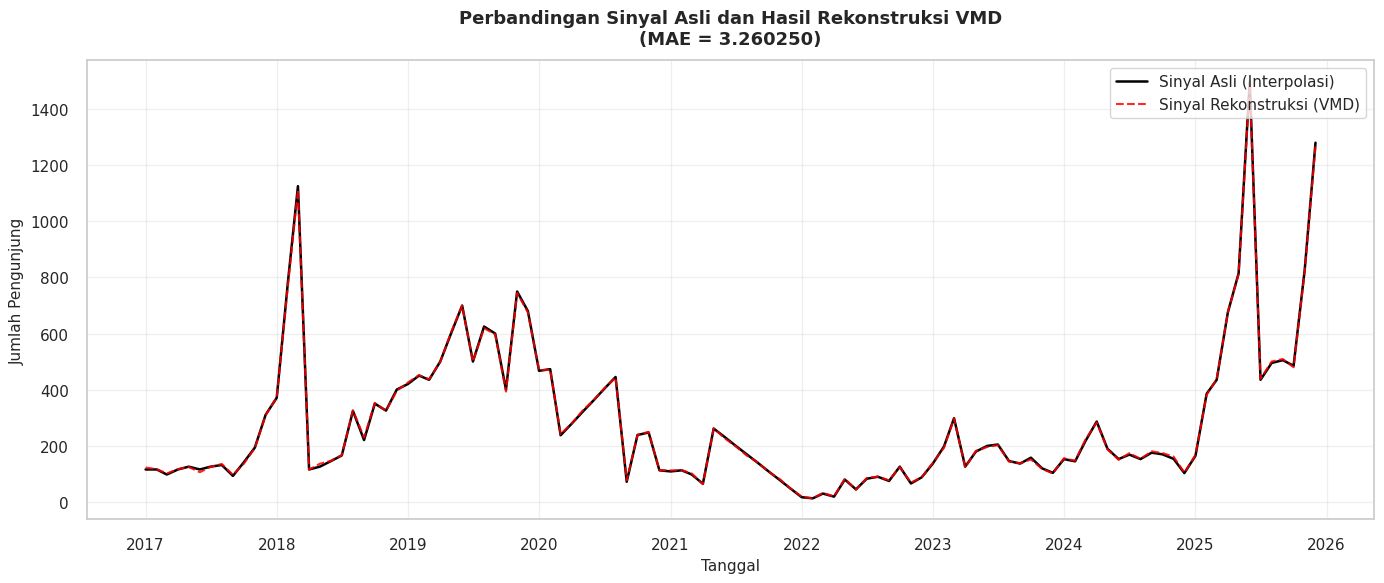

💾 Grafik disimpan: output_hasil/grafik/04_reconstruction_vmd.png


In [12]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import mean_absolute_error

# ─── 1. Membaca Hasil Dekomposisi & Data Preprocessing ─────────
# Membaca hasil mode VMD yang sudah disimpan
imfs_df = pd.read_csv('hasil-dekomposisi/imfs.csv')

# Rekonstruksi sinyal (penjumlahan seluruh mode VMD)
reconstructed_signal = imfs_df.sum(axis=1)

# Sinyal asli dan tanggal dari data preprocessing (data_clean)
original_signal = data_clean['visitors'].values
dates = data_clean['date']

# ─── 2. Evaluasi Rekonstruksi (MAE) ───────────────────────────
mae = mean_absolute_error(original_signal, reconstructed_signal)

print('=' * 65)
print('📊 EVALUASI REKONSTRUKSI VMD')
print('=' * 65)
print(f'Mean Absolute Error (MAE): {mae:.6f}')

# ─── 3. Visualisasi Sinyal Asli vs Rekonstruksi ────────────────
plt.figure(figsize=(14, 6))

# Plot Sinyal Asli (Interpolasi)
plt.plot(
    dates,
    original_signal,
    label='Sinyal Asli (Interpolasi)',
    color='black',
    linewidth=1.8,
)

# Plot Sinyal Rekonstruksi (Sum of VMD Modes)
plt.plot(
    dates,
    reconstructed_signal,
    label='Sinyal Rekonstruksi (VMD)',
    color='red',
    linestyle='--',
    linewidth=1.5,
    alpha=0.85,
)

plt.title(
    f'Perbandingan Sinyal Asli dan Hasil Rekonstruksi VMD\n(MAE = {mae:.6f})',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
plt.xlabel('Tanggal', fontsize=11)
plt.ylabel('Jumlah Pengunjung', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Simpan Grafik Evaluasi Rekonstruksi
os.makedirs('output_hasil/grafik', exist_ok=True)
plt.savefig(
    'output_hasil/grafik/04_reconstruction_vmd.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

print(
    '💾 Grafik disimpan:'
    ' output_hasil/grafik/04_reconstruction_vmd.png'
)

⚙️ PROSES NORMALISASI MINMAXSCALER MODE VMD
✅ Scaler berhasil disimpan: scaler/scaler_VMD_1.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_2.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_3.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_4.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_5.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_6.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_7.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_8.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_9.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_10.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_11.pkl
✅ Scaler berhasil disimpan: scaler/scaler_VMD_12.pkl

💾 Hasil normalisasi berhasil disimpan:
   - hasil-normalisasi/normalized_imfs.csv
   - hasil-normalisasi/normalized_imfs.pkl
   - hasil-normalisasi/normalized_imfs_with_date.csv


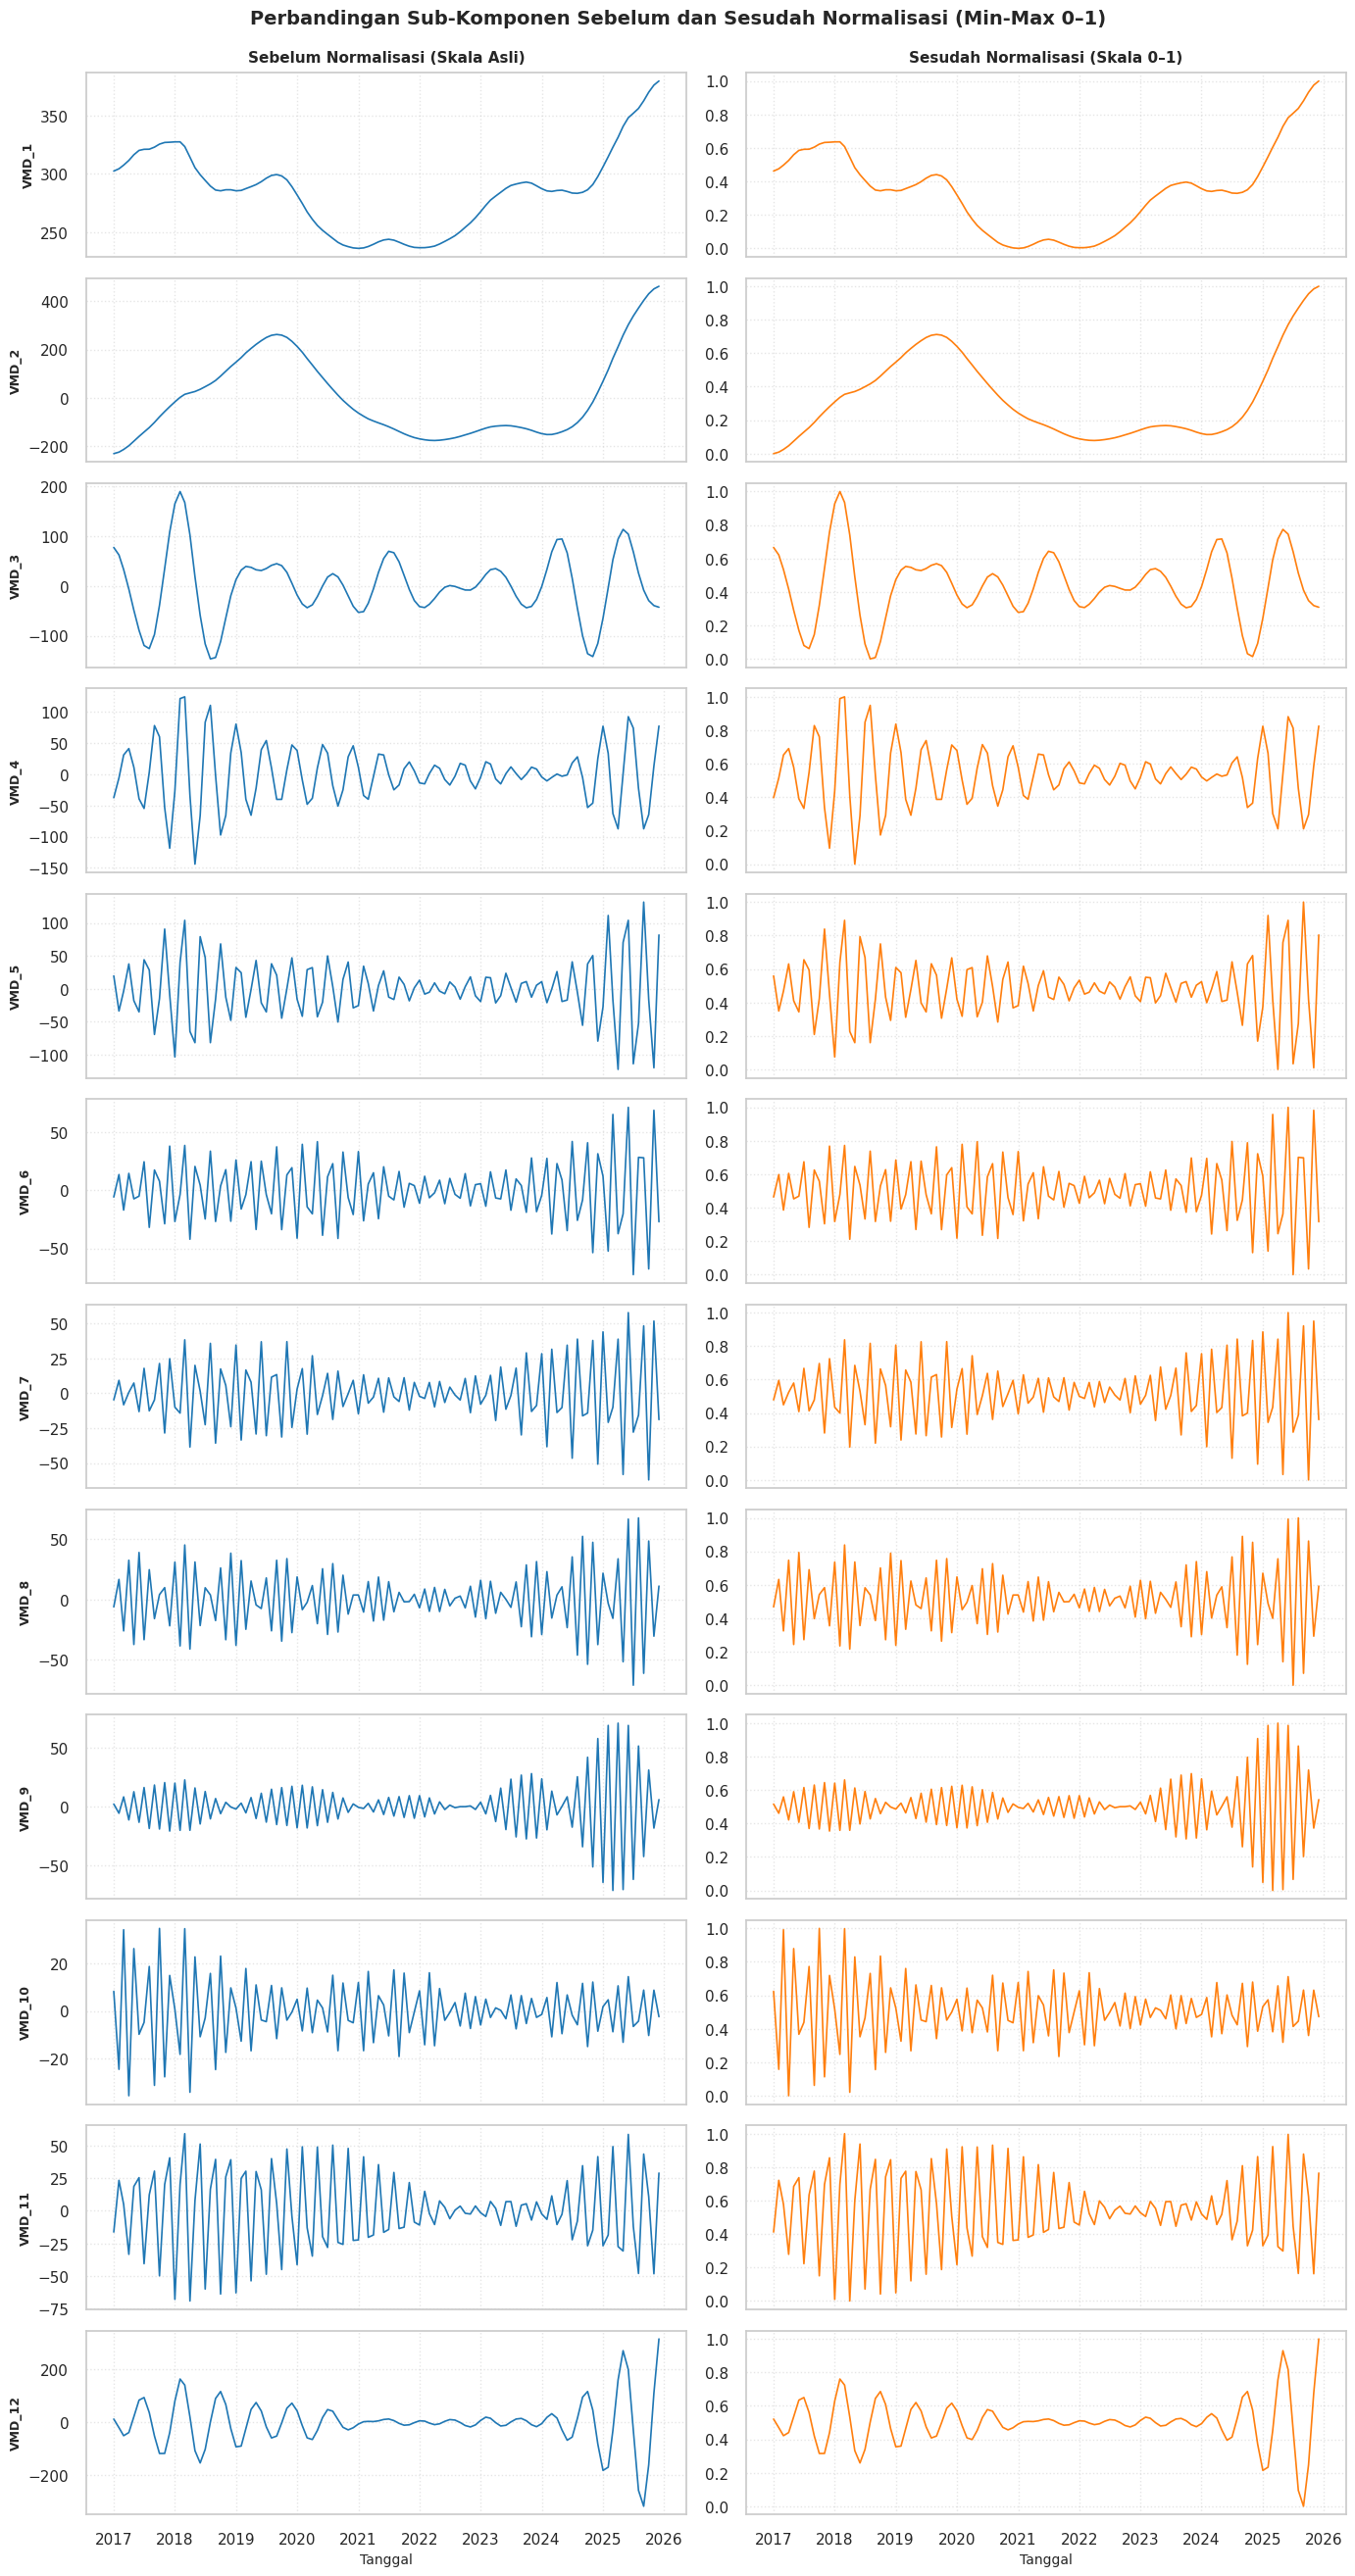

💾 Grafik disimpan: output_hasil/grafik/05_normalization_comparison.png

💾 Excel lengkap normalisasi disimpan: hasil-normalisasi/normalisasi_hasil_lengkap.xlsx
   Sheet: Ringkasan_MinMax, Data_Normalisasi, Perhitungan_Manual


In [13]:
import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# =========================================================
# 1. PERSIAPAN DIREKTORI
# =========================================================
os.makedirs('scaler', exist_ok=True)
os.makedirs('hasil-normalisasi', exist_ok=True)
os.makedirs('output_hasil/grafik', exist_ok=True)

# =========================================================
# 2. MEMBACA / MENYIAPKAN DATA KOMPONEN HYBRID
# =========================================================
# Menggunakan df_imfs_numeric bila tersedia di memori,
# jika tidak maka dibaca dari file imfs.csv hasil dekomposisi.
if 'df_imfs_numeric' in globals():
  data_to_normalize = df_imfs_numeric.copy()
else:
  data_to_normalize = pd.read_csv('hasil-dekomposisi/imfs.csv')

# ─── [PERBAIKAN] Menyiapkan kolom tanggal secara konsisten ─────
# Sebelumnya variabel `imfs` (dengan kolom 'date') dipakai langsung
# di script visualisasi tanpa dijamin selalu tersedia/konsisten.
# Di sini kita bangun ulang secara eksplisit agar tidak error.
if 'data_clean' in globals() and 'date' in data_clean.columns:
  tanggal = pd.to_datetime(data_clean['date']).reset_index(drop=True)
elif 'imfs' in globals() and 'date' in imfs.columns:
  tanggal = pd.to_datetime(imfs['date']).reset_index(drop=True)
else:
  # Fallback: index biasa jika kolom tanggal benar-benar tidak ada
  tanggal = pd.Series(range(len(data_to_normalize)), name='date')

data_to_normalize = data_to_normalize.reset_index(drop=True)

# DataFrame untuk menampung hasil normalisasi seluruh sub-komponen
normalized_imfs = pd.DataFrame()

# ─── [TAMBAHAN] Menyimpan ringkasan min/max tiap kolom untuk ────
#     keperluan perhitungan manual & rekap Excel nantinya
minmax_summary = []

print('=' * 65)
print('⚙️ PROSES NORMALISASI MINMAXSCALER MODE VMD')
print('=' * 65)

# =========================================================
# 3. NORMALISASI SETIAP SUB-KOMPONEN & SIMPAN SCALER
# =========================================================
for column in data_to_normalize.columns:
  scaler = MinMaxScaler(feature_range=(0, 1))

  # Reshape data 1D ke 2D array (syarat input sklearn)
  data = data_to_normalize[column].values.reshape(-1, 1)
  normalized_data = scaler.fit_transform(data)
  normalized_imfs[column] = normalized_data.flatten()

  # Simpan objek scaler masing-masing sub-komponen
  scaler_filename = f'scaler/scaler_{column}.pkl'
  joblib.dump(scaler, scaler_filename)

  # Simpan ringkasan min & max (dipakai untuk rumus manual)
  x_min = float(scaler.data_min_[0])
  x_max = float(scaler.data_max_[0])
  minmax_summary.append({
      'Komponen': column,
      'x_min': x_min,
      'x_max': x_max,
      'Range (x_max - x_min)': x_max - x_min,
  })

  print(f'✅ Scaler berhasil disimpan: {scaler_filename}')

# =========================================================
# 4. SIMPAN HASIL NORMALISASI (DATASET MURNI & DENGAN TANGGAL)
# =========================================================
normalized_imfs.to_csv('hasil-normalisasi/normalized_imfs.csv', index=False)
normalized_imfs.to_pickle('hasil-normalisasi/normalized_imfs.pkl')

normalized_imfs_with_date = normalized_imfs.copy()
normalized_imfs_with_date['date'] = tanggal.values
normalized_imfs_with_date.to_csv(
    'hasil-normalisasi/normalized_imfs_with_date.csv', index=False
)

print('\n💾 Hasil normalisasi berhasil disimpan:')
print('   - hasil-normalisasi/normalized_imfs.csv')
print('   - hasil-normalisasi/normalized_imfs.pkl')
print('   - hasil-normalisasi/normalized_imfs_with_date.csv')


# =========================================================
# 5. VISUALISASI SEBELUM VS SESUDAH NORMALISASI
# =========================================================
n_cols = len(data_to_normalize.columns)
sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(n_cols, 2, figsize=(14, 2.2 * n_cols), sharex=True)

# ─── [PERBAIKAN] jika hanya 1 komponen, axes tidak 2D — dipaksa jadi 2D ──
if n_cols == 1:
  axes = np.array([axes])

fig.suptitle(
    'Perbandingan Sub-Komponen Sebelum dan Sesudah Normalisasi (Min-Max 0–1)',
    fontsize=14,
    fontweight='bold',
    y=0.995,
)

for i, col in enumerate(data_to_normalize.columns):
  # Grafik Kiri: Sebelum Normalisasi (Skala Asli)
  axes[i, 0].plot(tanggal, data_to_normalize[col], color='#1f77b4', linewidth=1.2)
  axes[i, 0].set_ylabel(col, fontsize=9, fontweight='bold')
  axes[i, 0].grid(True, linestyle=':', alpha=0.5)

  # Grafik Kanan: Sesudah Normalisasi (Skala 0 sampai 1)
  axes[i, 1].plot(tanggal, normalized_imfs[col], color='#ff7f0e', linewidth=1.2)
  axes[i, 1].set_ylim(-0.05, 1.05)
  axes[i, 1].grid(True, linestyle=':', alpha=0.5)

  if i == 0:
    axes[i, 0].set_title('Sebelum Normalisasi (Skala Asli)', fontsize=11, fontweight='bold', pad=8)
    axes[i, 1].set_title('Sesudah Normalisasi (Skala 0–1)', fontsize=11, fontweight='bold', pad=8)

axes[-1, 0].set_xlabel('Tanggal', fontsize=10)
axes[-1, 1].set_xlabel('Tanggal', fontsize=10)

plt.tight_layout()
plt.savefig(
    'output_hasil/grafik/05_normalization_comparison.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()
print('💾 Grafik disimpan: output_hasil/grafik/05_normalization_comparison.png')


# =========================================================================
# =========================================================================
#   6. EKSPOR EXCEL: RINGKASAN SCALER, DATA HASIL, & PERHITUNGAN MANUAL
# =========================================================================
# =========================================================================
import openpyxl
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

header_fill = PatternFill('solid', start_color='1F4E79', fgColor='1F4E79')
alt_fill = PatternFill('solid', start_color='D6E4F0', fgColor='D6E4F0')
note_fill = PatternFill('solid', start_color='FFF2CC', fgColor='FFF2CC')
best_fill = PatternFill('solid', start_color='C6EFCE', fgColor='C6EFCE')
header_font = Font(bold=True, color='FFFFFF', name='Arial', size=11)
data_font = Font(name='Arial', size=10)
note_font = Font(name='Arial', size=10, italic=True)
center = Alignment(horizontal='center', vertical='center', wrap_text=True)
left_wrap = Alignment(horizontal='left', vertical='center', wrap_text=True)
thin_border = Border(
    left=Side(style='thin'), right=Side(style='thin'),
    top=Side(style='thin'), bottom=Side(style='thin'),
)


def title_block(ws, r, text, span=7, size=13, height=22):
  ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=span)
  c = ws.cell(row=r, column=1, value=text)
  c.font = Font(bold=True, color='FFFFFF', name='Arial', size=size)
  c.fill = header_fill
  c.alignment = center
  ws.row_dimensions[r].height = height
  return r + 1


def note_block(ws, r, text, span=7, height=32):
  ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=span)
  c = ws.cell(row=r, column=1, value=text)
  c.font = note_font
  c.fill = note_fill
  c.alignment = left_wrap
  ws.row_dimensions[r].height = height
  return r + 1


def table_header(ws, r, headers):
  for ci, h in enumerate(headers, start=1):
    c = ws.cell(row=r, column=ci, value=h)
    c.font = header_font
    c.fill = header_fill
    c.alignment = center
    c.border = thin_border
  return r + 1


def table_row(ws, r, values, alt=False, highlight=False):
  fill = best_fill if highlight else (alt_fill if alt else PatternFill())
  for ci, v in enumerate(values, start=1):
    c = ws.cell(row=r, column=ci, value=v)
    c.font = data_font
    c.fill = fill
    c.alignment = center
    c.border = thin_border
  return r + 1


wb = openpyxl.Workbook()

# ------------------------------------------------------------------
# SHEET 1: Ringkasan Min-Max per Komponen (dasar rumus normalisasi)
# ------------------------------------------------------------------
ws1 = wb.active
ws1.title = 'Ringkasan_MinMax'
r = 1
r = title_block(ws1, r, 'Ringkasan Nilai Min & Max per Sub-Komponen (Dasar Normalisasi Min-Max)', span=4)
r = note_block(
    ws1, r,
    'Nilai x_min dan x_max diambil langsung dari MinMaxScaler.data_min_ dan data_max_ '
    'masing-masing sub-komponen, dengan feature_range = (0, 1).',
    span=4,
)
r += 1
r = table_header(ws1, r, ['Komponen', 'x_min', 'x_max', 'Range (x_max - x_min)'])
for i, row in enumerate(minmax_summary):
  r = table_row(
      ws1, r,
      [row['Komponen'], round(row['x_min'], 6), round(row['x_max'], 6), round(row['Range (x_max - x_min)'], 6)],
      alt=(i % 2 == 0),
  )
for i, w in enumerate([26, 20, 20, 24], start=1):
  ws1.column_dimensions[get_column_letter(i)].width = w

# ------------------------------------------------------------------
# SHEET 2: Data Hasil Normalisasi Lengkap (seluruh komponen)
# ------------------------------------------------------------------
ws2 = wb.create_sheet('Data_Normalisasi')
r = 1
n_cols_ws2 = len(normalized_imfs.columns) + 1
r = title_block(ws2, r, 'Hasil Normalisasi Min-Max (Skala 0–1) — Seluruh Sub-Komponen', span=min(n_cols_ws2, 12))
r += 1
headers2 = ['Tanggal'] + list(normalized_imfs.columns)
r = table_header(ws2, r, headers2)
tanggal_str = pd.to_datetime(tanggal).dt.strftime('%Y-%m-%d').values if np.issubdtype(pd.Series(tanggal).dtype, np.datetime64) else [str(t)[:10] for t in tanggal]
for i in range(len(normalized_imfs)):
  row_vals = [tanggal_str[i]] + [round(float(normalized_imfs.iloc[i, c]), 6) for c in range(len(normalized_imfs.columns))]
  r = table_row(ws2, r, row_vals, alt=(i % 2 == 0))
for i in range(1, n_cols_ws2 + 1):
  ws2.column_dimensions[get_column_letter(i)].width = 16

# ------------------------------------------------------------------
# SHEET 3: Perhitungan Manual Rumus Normalisasi Min-Max
# ------------------------------------------------------------------
ws3 = wb.create_sheet('Perhitungan_Manual')
r = 1
r = title_block(ws3, r, 'PERHITUNGAN MANUAL NORMALISASI MIN-MAX (SKALA 0–1)', span=7, size=14)
r = note_block(
    ws3, r,
    'Rumus: x_norm = (x - x_min) / (x_max - x_min). '
    'Ilustrasi ditampilkan untuk 2 komponen contoh (kolom pertama & kedua) sebanyak 10 data pertama, '
    'lalu diverifikasi terhadap hasil MinMaxScaler (sklearn) untuk memastikan kesesuaian.',
    span=7, height=44,
)
r += 1

contoh_kolom = list(data_to_normalize.columns)[: min(2, len(data_to_normalize.columns))]
n_preview = min(10, len(data_to_normalize))

for kolom in contoh_kolom:
  x_min_k = data_to_normalize[kolom].min()
  x_max_k = data_to_normalize[kolom].max()

  r = title_block(ws3, r, f'Komponen: {kolom}  (x_min = {x_min_k:.6f} ; x_max = {x_max_k:.6f})', span=7, size=12)
  r = table_header(ws3, r, ['g (Titik ke-)', 'x (nilai asli)', 'x - x_min', 'x_max - x_min', 'x_norm = (x-x_min)/(x_max-x_min)', 'x_norm (sklearn)', 'Selisih'])

  for i in range(n_preview):
    x_val = data_to_normalize[kolom].iloc[i]
    x_norm_manual = (x_val - x_min_k) / (x_max_k - x_min_k)
    x_norm_sklearn = normalized_imfs[kolom].iloc[i]
    r = table_row(
        ws3, r,
        [
            i + 1, round(float(x_val), 4), round(float(x_val - x_min_k), 4),
            round(float(x_max_k - x_min_k), 4), round(float(x_norm_manual), 6),
            round(float(x_norm_sklearn), 6), round(float(x_norm_manual - x_norm_sklearn), 8),
        ],
        alt=(i % 2 == 0),
    )

  cocok = 'COCOK ✅' if abs((data_to_normalize[kolom] - x_min_k) / (x_max_k - x_min_k) - normalized_imfs[kolom]).max() < 1e-9 else 'TIDAK COCOK ❌'
  r = note_block(
      ws3, r,
      f'Verifikasi (seluruh {len(data_to_normalize)} data pada komponen {kolom}): '
      f'perhitungan manual vs hasil MinMaxScaler → {cocok}',
      span=7, height=22,
  )
  r += 1

for i in range(1, 8):
  ws3.column_dimensions[get_column_letter(i)].width = 22

# ─── SIMPAN FILE EXCEL ──────────────────────────────────────────────
xlsx_path_norm = 'hasil-normalisasi/normalisasi_hasil_lengkap.xlsx'
wb.save(xlsx_path_norm)
print(f'\n💾 Excel lengkap normalisasi disimpan: {xlsx_path_norm}')
print('   Sheet: Ringkasan_MinMax, Data_Normalisasi, Perhitungan_Manual')


==================== MEMULAI SPLIT + WINDOW ====================


==================== VMD_1 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


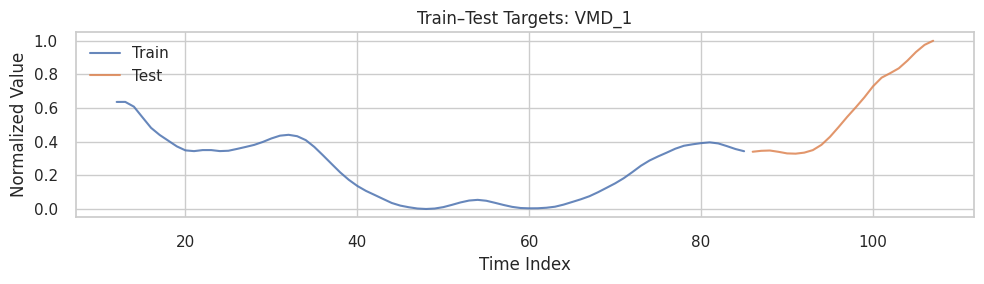


==================== VMD_2 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


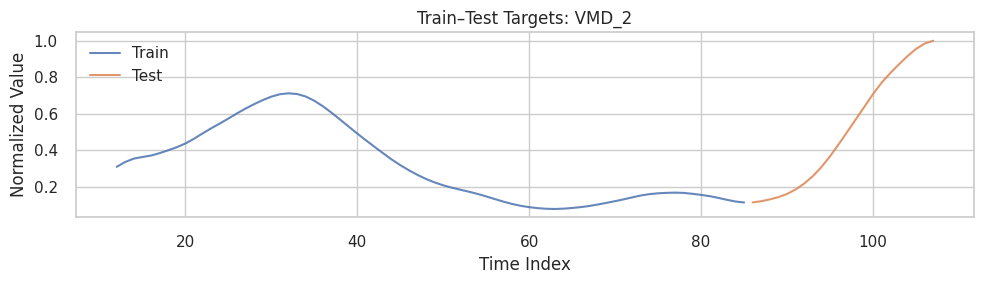


==================== VMD_3 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


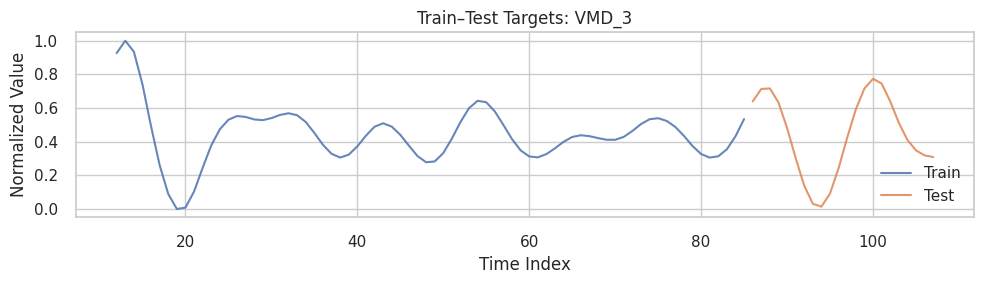


==================== VMD_4 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


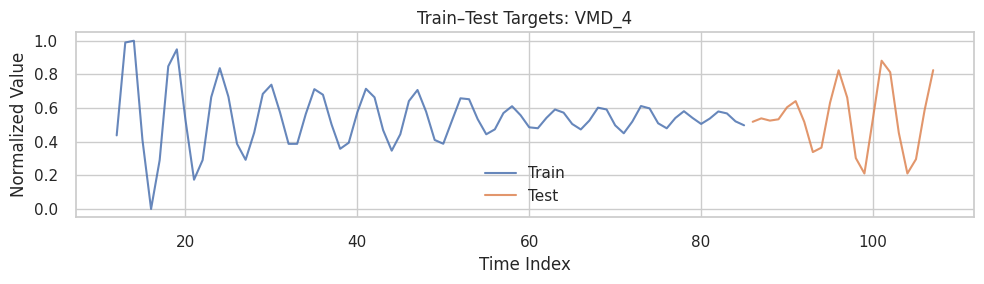


==================== VMD_5 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


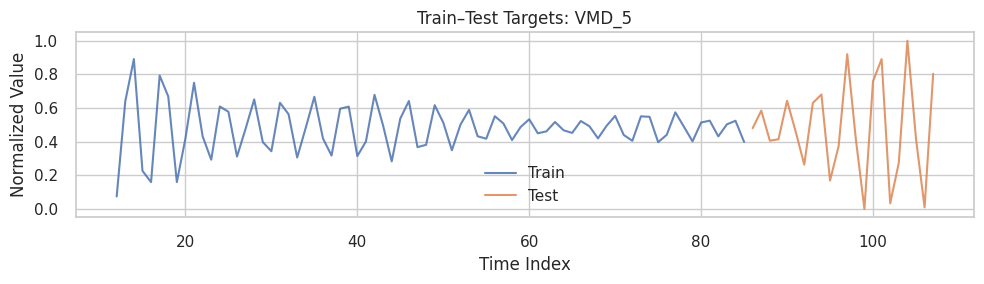


==================== VMD_6 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


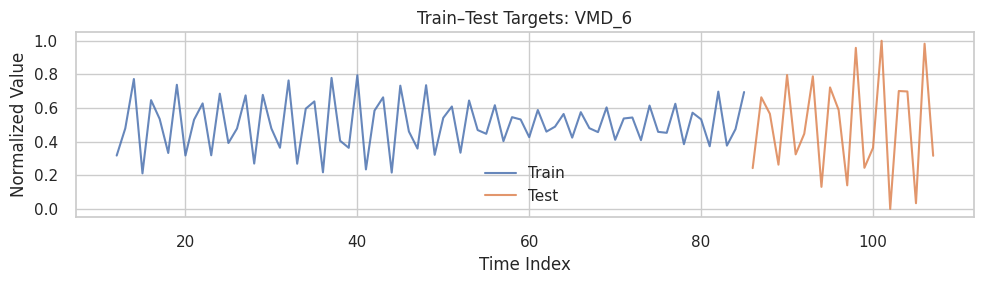


==================== VMD_7 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


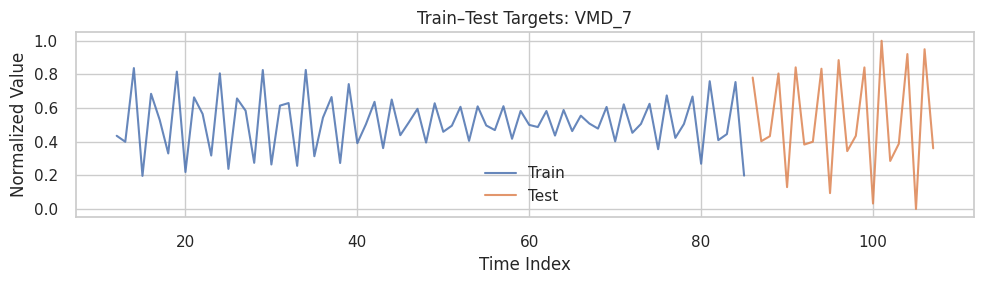


==================== VMD_8 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


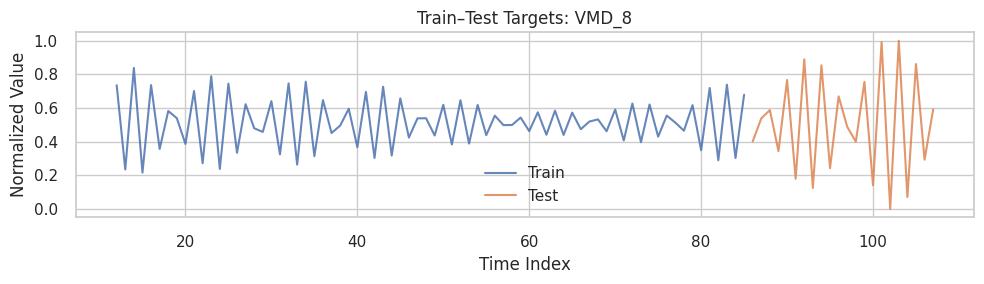


==================== VMD_9 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


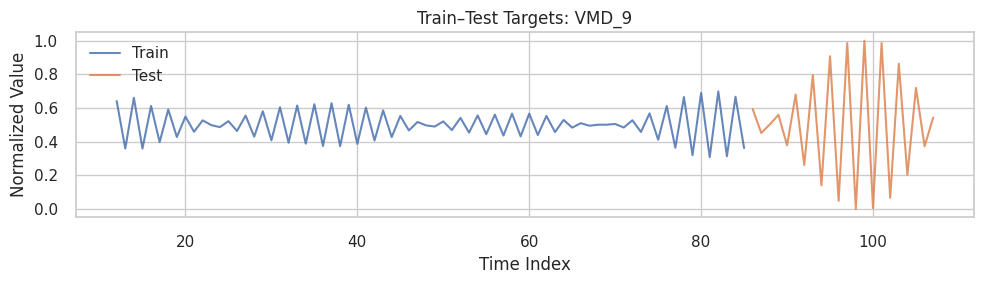


==================== VMD_10 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


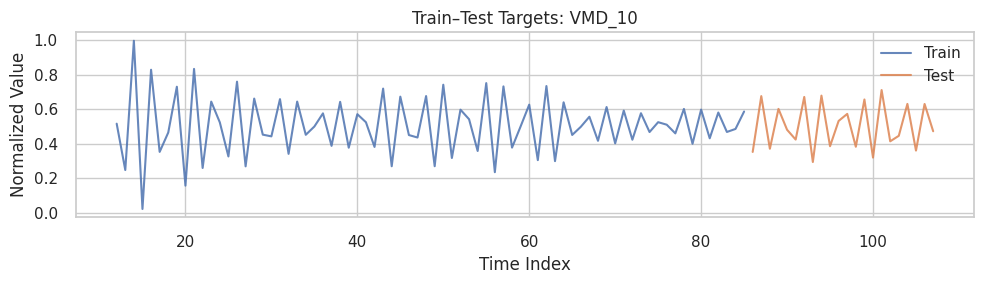


==================== VMD_11 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


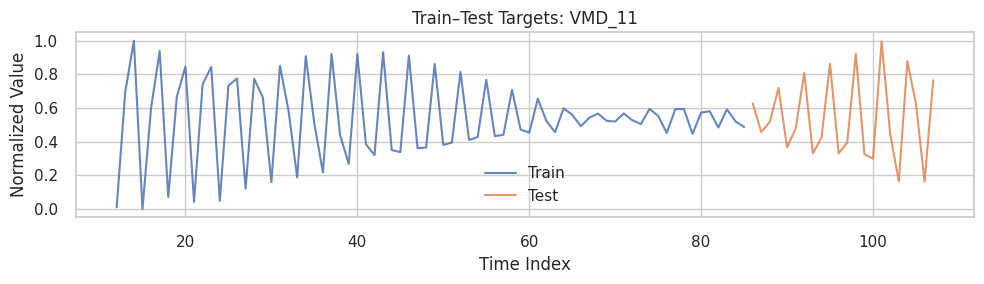


==================== VMD_12 ====================
Total data raw     : 108
Train raw length   : 86
Test raw length    : 22

--- SHAPE SETELAH WINDOWING ---
X_train : (74, 12, 1)
y_train : (74,)
X_test  : (22, 12, 1)
y_test  : (22,)


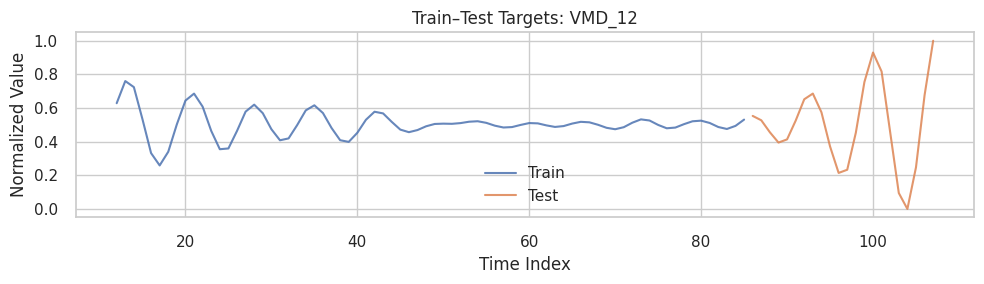


==================== RINGKASAN ====================
Component  Total_Raw  Train_Raw  Test_Raw X_train_shape y_train_shape X_test_shape y_test_shape
    VMD_1        108         86        22   (74, 12, 1)         (74,)  (22, 12, 1)        (22,)
    VMD_2        108         86        22   (74, 12, 1)         (74,)  (22, 12, 1)        (22,)
    VMD_3        108         86        22   (74, 12, 1)         (74,)  (22, 12, 1)        (22,)
    VMD_4        108         86        22   (74, 12, 1)         (74,)  (22, 12, 1)        (22,)
    VMD_5        108         86        22   (74, 12, 1)         (74,)  (22, 12, 1)        (22,)
    VMD_6        108         86        22   (74, 12, 1)         (74,)  (22, 12, 1)        (22,)
    VMD_7        108         86        22   (74, 12, 1)         (74,)  (22, 12, 1)        (22,)
    VMD_8        108         86        22   (74, 12, 1)         (74,)  (22, 12, 1)        (22,)
    VMD_9        108         86        22   (74, 12, 1)         (74,)  (22, 12, 1) 

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ======================
# CONFIG
# ======================
WINDOW = 12
TEST_RATIO = 0.2
INPUT_FILE = "hasil-normalisasi/normalized_imfs.csv"
OUTPUT_DIR = "dataset-split"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ======================
# FUNGSI WINDOWING
# ======================
def make_windowed_dataset(series, window):
  X, y = [], []
  for i in range(len(series) - window):
    X.append(series[i:i + window])
    y.append(series[i + window])
  return np.array(X), np.array(y)


# ======================
# LOAD DATA
# ======================
imf_df = pd.read_csv(INPUT_FILE)
windowed_data = {}
summary = []

# ─── [TAMBAHAN] Tempat menyimpan contoh detail windowing & split ────
#     per komponen, untuk direkap ke Excel (perhitungan manual)
manual_calc_records = {}

print("\n==================== MEMULAI SPLIT + WINDOW ====================\n")

for col in imf_df.columns:
  print(f"\n==================== {col} ====================")
  series = imf_df[col].values.astype(float)
  total_len = len(series)

  # split data train dan test
  split_idx = int(total_len * (1 - TEST_RATIO))
  train_series = series[:split_idx]
  test_series = series[split_idx:]

  print(f"Total data raw     : {total_len}")
  print(f"Train raw length   : {len(train_series)}")
  print(f"Test raw length    : {len(test_series)}")

  # windowing data train
  X_train, y_train = make_windowed_dataset(train_series, WINDOW)

  # windowing data test (dengan konteks dari akhir train)
  test_series_ctx = series[split_idx - WINDOW:]
  X_test, y_test = make_windowed_dataset(test_series_ctx, WINDOW)

  # validasi jumlah target test
  assert len(y_test) == len(test_series)

  # reshape ke format 3D (GRU/LSTM)
  X_train = X_train.reshape((X_train.shape[0], WINDOW, 1))
  X_test = X_test.reshape((X_test.shape[0], WINDOW, 1))

  # simpan ke dictionary
  windowed_data[col] = {
      "X_train": X_train,
      "y_train": y_train,
      "X_test": X_test,
      "y_test": y_test,
      "split_idx": split_idx,
  }

  # simpan ke file .npy per komponen
  comp_dir = os.path.join(OUTPUT_DIR, col)
  os.makedirs(comp_dir, exist_ok=True)
  np.save(os.path.join(comp_dir, "X_train.npy"), X_train)
  np.save(os.path.join(comp_dir, "y_train.npy"), y_train)
  np.save(os.path.join(comp_dir, "X_test.npy"), X_test)
  np.save(os.path.join(comp_dir, "y_test.npy"), y_test)

  # informasi bentuk data
  print("\n--- SHAPE SETELAH WINDOWING ---")
  print(f"X_train : {X_train.shape}")
  print(f"y_train : {y_train.shape}")
  print(f"X_test  : {X_test.shape}")
  print(f"y_test  : {y_test.shape}")

  summary.append({
      "Component": col,
      "Total_Raw": total_len,
      "Train_Raw": len(train_series),
      "Test_Raw": len(test_series),
      "X_train_shape": X_train.shape,
      "y_train_shape": y_train.shape,
      "X_test_shape": X_test.shape,
      "y_test_shape": y_test.shape,
  })

  # ─── [TAMBAHAN] Simpan contoh mentah (belum di-reshape 3D) ────
  #     untuk 3 window pertama train & 3 window pertama test,
  #     dipakai pada sheet perhitungan manual di Excel
  X_train_raw, y_train_raw = make_windowed_dataset(train_series, WINDOW)
  X_test_raw, y_test_raw = make_windowed_dataset(test_series_ctx, WINDOW)
  manual_calc_records[col] = {
      "series": series,
      "total_len": total_len,
      "split_idx": split_idx,
      "train_len": len(train_series),
      "test_len": len(test_series),
      "X_train_raw": X_train_raw,
      "y_train_raw": y_train_raw,
      "X_test_raw": X_test_raw,
      "y_test_raw": y_test_raw,
      "test_series_ctx": test_series_ctx,
  }

  # visualisasi target train dan test
  train_target_idx = np.arange(WINDOW, split_idx)
  test_target_idx = np.arange(split_idx, total_len)

  plt.figure(figsize=(10, 3))
  plt.plot(train_target_idx, y_train, label="Train", alpha=0.85)
  plt.plot(test_target_idx, y_test, label="Test", alpha=0.85)
  plt.title(f"Train–Test Targets: {col}")
  plt.xlabel("Time Index")
  plt.ylabel("Normalized Value")
  plt.grid(True)
  plt.legend()
  plt.tight_layout()
  plt.show()

# ============================
# RINGKASAN
# ============================
summary_df = pd.DataFrame(summary)
print("\n==================== RINGKASAN ====================")
print(summary_df.to_string(index=False))
summary_df.to_csv(os.path.join(OUTPUT_DIR, "summary_shapes.csv"), index=False)
print(f"\nSummary saved: {OUTPUT_DIR}/summary_shapes.csv")


# =========================================================================
# =========================================================================
#   EKSPOR EXCEL: PERHITUNGAN MANUAL SLIDING WINDOW & TRAIN-TEST SPLIT
# =========================================================================
# =========================================================================
import openpyxl
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

header_fill = PatternFill('solid', start_color='1F4E79', fgColor='1F4E79')
alt_fill = PatternFill('solid', start_color='D6E4F0', fgColor='D6E4F0')
note_fill = PatternFill('solid', start_color='FFF2CC', fgColor='FFF2CC')
best_fill = PatternFill('solid', start_color='C6EFCE', fgColor='C6EFCE')
header_font = Font(bold=True, color='FFFFFF', name='Arial', size=11)
data_font = Font(name='Arial', size=10)
note_font = Font(name='Arial', size=10, italic=True)
center = Alignment(horizontal='center', vertical='center', wrap_text=True)
left_wrap = Alignment(horizontal='left', vertical='center', wrap_text=True)
thin_border = Border(
    left=Side(style='thin'), right=Side(style='thin'),
    top=Side(style='thin'), bottom=Side(style='thin'),
)


def title_block(ws, r, text, span=7, size=13, height=22):
  ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=span)
  c = ws.cell(row=r, column=1, value=text)
  c.font = Font(bold=True, color='FFFFFF', name='Arial', size=size)
  c.fill = header_fill
  c.alignment = center
  ws.row_dimensions[r].height = height
  return r + 1


def note_block(ws, r, text, span=7, height=32):
  ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=span)
  c = ws.cell(row=r, column=1, value=text)
  c.font = note_font
  c.fill = note_fill
  c.alignment = left_wrap
  ws.row_dimensions[r].height = height
  return r + 1


def table_header(ws, r, headers):
  for ci, h in enumerate(headers, start=1):
    c = ws.cell(row=r, column=ci, value=h)
    c.font = header_font
    c.fill = header_fill
    c.alignment = center
    c.border = thin_border
  return r + 1


def table_row(ws, r, values, alt=False, highlight=False):
  fill = best_fill if highlight else (alt_fill if alt else PatternFill())
  for ci, v in enumerate(values, start=1):
    c = ws.cell(row=r, column=ci, value=v)
    c.font = data_font
    c.fill = fill
    c.alignment = center
    c.border = thin_border
  return r + 1


wb = openpyxl.Workbook()

# ------------------------------------------------------------------
# SHEET 1: Ringkasan Split & Windowing Seluruh Komponen
# ------------------------------------------------------------------
ws1 = wb.active
ws1.title = 'Ringkasan_Split_Window'
r = 1
r = title_block(ws1, r, 'Ringkasan Train-Test Split & Sliding Window per Komponen', span=8)
r = note_block(
    ws1, r,
    f'Parameter: WINDOW = {WINDOW}, TEST_RATIO = {TEST_RATIO}. '
    f'split_idx = int(Total_Raw x (1 - TEST_RATIO)). '
    f'Jumlah sampel setelah windowing = Panjang_Data - WINDOW.',
    span=8, height=32,
)
r += 1
r = table_header(ws1, r, ['Komponen', 'Total_Raw', 'split_idx', 'Train_Raw', 'Test_Raw', 'X_train shape', 'X_test shape', 'y_test == Test_Raw?'])
for i, row in enumerate(summary):
  cek = 'OK ✅' if row['y_test_shape'][0] == row['Test_Raw'] else 'BEDA ❌'
  r = table_row(
      ws1, r,
      [
          row['Component'], row['Total_Raw'], windowed_data[row['Component']]['split_idx'],
          row['Train_Raw'], row['Test_Raw'], str(row['X_train_shape']), str(row['X_test_shape']), cek,
      ],
      alt=(i % 2 == 0),
  )
for i, w in enumerate([24, 12, 12, 12, 12, 16, 16, 18], start=1):
  ws1.column_dimensions[get_column_letter(i)].width = w

# ------------------------------------------------------------------
# SHEET 2: Perhitungan Manual — Train/Test Split
# ------------------------------------------------------------------
ws2 = wb.create_sheet('Perhitungan_Manual_Split')
r = 1
r = title_block(ws2, r, 'PERHITUNGAN MANUAL TRAIN-TEST SPLIT', span=7, size=14)
r = note_block(
    ws2, r,
    'Rumus: split_idx = int(Total_Raw x (1 - TEST_RATIO)). '
    'Data indeks [0 .. split_idx-1] menjadi Train, indeks [split_idx .. Total_Raw-1] menjadi Test.',
    span=7, height=32,
)
r += 1

contoh_kolom_split = list(imf_df.columns)[: min(2, len(imf_df.columns))]
for kolom in contoh_kolom_split:
  rec = manual_calc_records[kolom]
  total_len = rec['total_len']
  split_idx = rec['split_idx']
  train_len = rec['train_len']
  test_len = rec['test_len']

  r = title_block(ws2, r, f'Komponen: {kolom}', span=7, size=12)
  r = note_block(
      ws2, r,
      f'split_idx = int({total_len} x (1 - {TEST_RATIO})) = int({total_len} x {1-TEST_RATIO:.2f}) = int({total_len*(1-TEST_RATIO):.4f}) = {split_idx}\n'
      f'Train_Raw = split_idx = {split_idx}  ;  Test_Raw = Total_Raw - split_idx = {total_len} - {split_idx} = {test_len}',
      span=7, height=40,
  )
  r = table_header(ws2, r, ['Segmen', 'Indeks Mulai', 'Indeks Akhir', 'Jumlah Data', '', '', ''])
  r = table_row(ws2, r, ['Train', 0, split_idx - 1, train_len, '', '', ''], alt=True)
  r = table_row(ws2, r, ['Test', split_idx, total_len - 1, test_len, '', '', ''], alt=False)
  r += 1

for i in range(1, 8):
  ws2.column_dimensions[get_column_letter(i)].width = 20

# ------------------------------------------------------------------
# SHEET 3: Perhitungan Manual — Sliding Window (Train)
# ------------------------------------------------------------------
ws3 = wb.create_sheet('Perhitungan_Manual_Window')
r = 1
r = title_block(ws3, r, 'PERHITUNGAN MANUAL SLIDING WINDOW (DATA TRAIN)', span=15, size=14)
r = note_block(
    ws3, r,
    f'Rumus: X[i] = series[i : i+WINDOW]  ;  y[i] = series[i+WINDOW]  ,  WINDOW = {WINDOW}. '
    'Jendela (window) bergeser 1 langkah setiap iterasi. Berikut ditampilkan 3 window pertama '
    'sebagai ilustrasi, untuk komponen contoh.',
    span=15, height=32,
)
r += 1

kolom_contoh_window = contoh_kolom_split[0]
rec = manual_calc_records[kolom_contoh_window]
X_train_raw = rec['X_train_raw']
y_train_raw = rec['y_train_raw']

r = title_block(ws3, r, f'Komponen: {kolom_contoh_window}', span=15, size=12)
header_window = ['i (indeks window)'] + [f'x[{k}]' for k in range(WINDOW)] + ['-> y (target)']
r = table_header(ws3, r, header_window)
n_show = min(3, len(X_train_raw))
for i in range(n_show):
  row_vals = [i] + [round(float(v), 6) for v in X_train_raw[i]] + [round(float(y_train_raw[i]), 6)]
  r = table_row(ws3, r, row_vals, alt=(i % 2 == 0))

r = note_block(
    ws3, r,
    f'Contoh window ke-0: X[0] = series[0:{WINDOW}] (data indeks 0 s.d. {WINDOW-1}), '
    f'y[0] = series[{WINDOW}] (data indeks ke-{WINDOW}). '
    f'Window ke-1 bergeser satu langkah: X[1] = series[1:{WINDOW+1}], y[1] = series[{WINDOW+1}]. '
    f'Proses ini diulang hingga i = Train_Raw - WINDOW - 1, menghasilkan total {len(X_train_raw)} pasangan (X, y) untuk data train.',
    span=15, height=44,
)

for i in range(1, WINDOW + 3):
  ws3.column_dimensions[get_column_letter(i)].width = 12
ws3.column_dimensions['A'].width = 16

# ------------------------------------------------------------------
# SHEET 4: Perhitungan Manual — Sliding Window (Test dgn Konteks Train)
# ------------------------------------------------------------------
ws4 = wb.create_sheet('Perhitungan_Manual_Window_Test')
r = 1
r = title_block(ws4, r, 'PERHITUNGAN MANUAL SLIDING WINDOW (DATA TEST + KONTEKS AKHIR TRAIN)', span=15, size=14)
r = note_block(
    ws4, r,
    'Agar window pertama pada data Test tetap memiliki WINDOW titik data historis, diambil konteks tambahan '
    'dari WINDOW titik terakhir data Train: test_series_ctx = series[split_idx - WINDOW : ]. '
    'Windowing kemudian diterapkan pada test_series_ctx dengan rumus yang sama seperti pada data Train, '
    f'menghasilkan tepat {rec["test_len"]} pasangan (X, y) — sama dengan jumlah data Test asli (lihat sheet Ringkasan_Split_Window).',
    span=15, height=56,
)
r += 1

rec2 = manual_calc_records[kolom_contoh_window]
X_test_raw = rec2['X_test_raw']
y_test_raw = rec2['y_test_raw']
split_idx2 = rec2['split_idx']

r = title_block(ws4, r, f'Komponen: {kolom_contoh_window}  (split_idx = {split_idx2}, WINDOW = {WINDOW})', span=15, size=12)
r = note_block(
    ws4, r,
    f'test_series_ctx = series[{split_idx2} - {WINDOW} : ] = series[{split_idx2-WINDOW} : ]  → panjang = {len(rec2["test_series_ctx"])}',
    span=15, height=22,
)
header_window_test = ['i (indeks window)'] + [f'x[{k}]' for k in range(WINDOW)] + ['-> y (target)']
r = table_header(ws4, r, header_window_test)
n_show2 = min(3, len(X_test_raw))
for i in range(n_show2):
  row_vals = [i] + [round(float(v), 6) for v in X_test_raw[i]] + [round(float(y_test_raw[i]), 6)]
  r = table_row(ws4, r, row_vals, alt=(i % 2 == 0))

r = note_block(
    ws4, r,
    f'Window pertama (i=0) pada test_series_ctx berisi {WINDOW} titik terakhir data Train sebagai input, '
    f'dan target y[0] adalah data pertama pada set Test yang sesungguhnya (indeks asli ke-{split_idx2}). '
    f'Verifikasi: len(y_test) = {len(y_test_raw)}  vs  Test_Raw = {rec2["test_len"]}  → '
    f'{"COCOK ✅" if len(y_test_raw)==rec2["test_len"] else "TIDAK COCOK ❌"}',
    span=15, height=44,
)

for i in range(1, WINDOW + 3):
  ws4.column_dimensions[get_column_letter(i)].width = 12
ws4.column_dimensions['A'].width = 16

# ─── SIMPAN FILE EXCEL ──────────────────────────────────────────────
xlsx_path_window = os.path.join(OUTPUT_DIR, 'split_window_hasil_lengkap.xlsx')
wb.save(xlsx_path_window)
print(f'\n💾 Excel lengkap split & windowing disimpan: {xlsx_path_window}')
print('   Sheet: Ringkasan_Split_Window, Perhitungan_Manual_Split, Perhitungan_Manual_Window, Perhitungan_Manual_Window_Test')

In [15]:
import gc
import json
import os
import numpy as np
import optuna
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import GRU, Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam


def create_gru_model(units, dropout_rate, learning_rate, input_shape):
  """Membangun arsitektur model GRU univariate dengan API Keras terbaru (Input layer)."""
  model = Sequential([
      Input(shape=input_shape),
      GRU(units=units, activation='tanh', return_sequences=False),
      Dropout(dropout_rate),
      Dense(1, activation='linear'),
  ])
  optimizer = Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
  return model


print('✅ Fungsi create_gru_model siap digunakan.')


def objective_single(trial, X, y):
  """Objective function Optuna untuk fine-tuning hyperparameter GRU per sub-mode."""
  # Split Data Train dan Validation (80:20) tanpa shuffle (Strict Time-Series Order)
  split_idx = int(len(X) * 0.8)
  X_train, X_val = X[:split_idx], X[split_idx:]
  y_train, y_val = y[:split_idx], y[split_idx:]

  # Ruang pencarian hyperparameter
  units = trial.suggest_categorical('units', [8, 16, 24, 64])
  dropout = trial.suggest_float('dropout', 0.0, 0.4)
  batch_size = trial.suggest_categorical('batch_size', [4, 8, 16, 20, 24])
  learning_rate = trial.suggest_categorical(
      'learning_rate', [1e-4, 3e-4, 1e-3, 3e-3]
  )

  # Menerima input shape dan membangun model GRU
  input_shape = (X_train.shape[1], X_train.shape[2])
  model = create_gru_model(
      units=units,
      dropout_rate=dropout,
      learning_rate=learning_rate,
      input_shape=input_shape,
  )

  # Early Stopping callback untuk menghentikan training jika val_loss tidak membaik
  early_stop = EarlyStopping(
      monitor='val_loss', patience=20, restore_best_weights=True
  )

  # Training model
  model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=200,
      batch_size=batch_size,
      callbacks=[early_stop],
      verbose=0,
  )

  # Evaluasi MAE pada set validasi
  y_pred = model.predict(X_val, verbose=0).flatten()
  mae = mean_absolute_error(y_val.flatten(), y_pred)

  # ─── [TAMBAHAN] Simpan cuplikan data split & prediksi ke trial ────
  #     agar bisa direkonstruksi untuk perhitungan manual di Excel,
  #     tanpa perlu menyimpan seluruh array (hemat memori studi Optuna)
  trial.set_user_attr('split_idx', int(split_idx))
  trial.set_user_attr('n_train', int(len(X_train)))
  trial.set_user_attr('n_val', int(len(X_val)))
  trial.set_user_attr('y_val_preview', y_val.flatten()[:5].round(6).tolist())
  trial.set_user_attr('y_pred_preview', y_pred[:5].round(6).tolist())

  # Bersihkan session Keras & garbage collector untuk menghemat RAM/GPU
  tf.keras.backend.clear_session()
  gc.collect()
  return mae


class StopIfNoImprovement:
  """Callback kustom untuk menghentikan studi Optuna jika nilai MAE stagnan."""

  def __init__(self, patience=10):
    self.patience = patience
    self.best_value = np.inf
    self.counter = 0

  def __call__(self, study, trial):
    current = trial.value
    if current is None:
      return
    if current < self.best_value:
      self.best_value = current
      self.counter = 0
    else:
      self.counter += 1
    if self.counter >= self.patience:
      print(
          f'\n>>> STOPPING OPTUNA: MAE tidak membaik selama {self.patience}'
          ' trial.\n'
      )
      study.stop()


print(
    '✅ Fungsi objective_single dan StopIfNoImprovement berhasil'
    ' didefinisikan.'
)

# ─── 1. Penyiapan windowed_data per Sub-Mode (Mencegah KeyError) ───
if (
    'windowed_data' not in globals()
    or not isinstance(windowed_data, dict)
    or len(windowed_data) == 0
    or 'X_train' not in list(windowed_data.values())[0]
):
  print('📦 Membentuk windowed_data untuk setiap sub-mode...')
  windowed_data = {}
  seq_length = 12  # Lag 12 periode (1 tahun)
  # Ambil data ter-normalisasi dari normalized_imfs
  source_df = (
      normalized_imfs
      if 'normalized_imfs' in globals()
      else pd.read_csv('hasil-normalisasi/normalized_imfs.csv')
  )
  for col in source_df.columns:
    if col == 'date':
      continue
    mode_values = source_df[col].values
    # Pembentukan Sliding Window Sequence
    X_list, y_list = [], []
    for i in range(len(mode_values) - seq_length):
      X_list.append(mode_values[i : i + seq_length])
      y_list.append(mode_values[i + seq_length])
    X_arr = np.array(X_list)
    y_arr = np.array(y_list)
    # Reshape ke bentuk 3D Keras: [samples, time_steps, features] -> (N, 12, 1)
    X_arr = X_arr.reshape(X_arr.shape[0], X_arr.shape[1], 1)
    windowed_data[col] = {'X_train': X_arr, 'y_train': y_arr}
  print(
      '✅ Pembentukan windowed_data selesai untuk'
      f' {len(windowed_data)} sub-mode.'
  )

# ─── 2. Execution Loop Optimasi Optuna ───────────────────────────
components = list(windowed_data.keys())
best_params = {}
studies_dict = {}

# ─── [TAMBAHAN] Tempat rekap seluruh riwayat trial (semua komponen) ──
all_trials_records = []

print('\n' + '=' * 65)
print('🚀 OPTIMASI HYPERPARAMETER GRU UNTUK SELURUH MODE VMD')
print('=' * 65)

for comp in components:
  # Mengambil data fitur (X_train) dan target (y_train) khusus untuk sub-mode ini
  X = windowed_data[comp]['X_train']
  y = windowed_data[comp]['y_train']

  print(f'\n=== Optimasi Hyperparameter GRU untuk: {comp} ===')

  # Mematikan log default Optuna agar tampilan output di notebook bersih
  optuna.logging.set_verbosity(optuna.logging.WARNING)

  # Inisialisasi study Optuna dengan TPESampler
  study = optuna.create_study(
      direction='minimize',
      sampler=optuna.samplers.TPESampler(seed=42),
      study_name=f'optuna_gru_{comp}',
  )

  # Inisialisasi callback early stopping Optuna (patience = 10 trial)
  callback = StopIfNoImprovement(patience=10)

  # Memulai proses optimasi
  study.optimize(
      lambda trial: objective_single(trial, X, y),
      n_trials=35,
      callbacks=[callback],
      show_progress_bar=True,
  )

  # Menyimpan parameter terbaik beserta nilai MAE validasi terendahnya
  best_params[comp] = study.best_params
  best_params[comp]['best_val_mae'] = float(study.best_value)
  studies_dict[comp] = study

  # ─── [TAMBAHAN] Rekap seluruh trial komponen ini ke list global ────
  for t in study.trials:
    all_trials_records.append({
        'Component': comp,
        'Trial': t.number,
        'Value_MAE': t.value,
        'units': t.params.get('units'),
        'dropout': t.params.get('dropout'),
        'batch_size': t.params.get('batch_size'),
        'learning_rate': t.params.get('learning_rate'),
        'State': str(t.state),
    })

  print(f'✅ Best Validation MAE ({comp}) : {study.best_value:.6f}')
  print(f'   Best Hyperparameters        : {study.best_params}')

print('\n' + '=' * 65)
print('SELESAI SEMUA PROSES OPTIMASI ✔')
print('=' * 65)

# ─── 3. Menyimpan Hasil Parameter Terbaik ke File JSON ────────────
os.makedirs('best-parameter-gru', exist_ok=True)
json_path = 'best-parameter-gru/best_gru_params_per_mode.json'
with open(json_path, 'w') as f:
  json.dump(best_params, f, indent=4)
print(f'\n💾 Parameter GRU terbaik seluruh sub-mode disimpan di: {json_path}')


# ============================
# RINGKASAN HASIL OPTUNA
# ============================
components = list(best_params.keys())
print('=' * 75)
print('📋 RINGKASAN HASIL OPTIMASI OPTUNA PER SUB-MODE (VAL MAE)')
print('=' * 75)

results_data = []
for comp in components:
  params = best_params.get(comp, {}).copy()
  study = studies_dict.get(comp, None)
  best_mae = (
      study.best_value if study is not None else params.get('best_val_mae', None)
  )
  params.pop('best_val_mae', None)
  row = {'Component': comp, 'Best_Val_MAE': best_mae}
  row.update(params)
  results_data.append(row)

results_df = pd.DataFrame(results_data)
cols_order = ['Component', 'Best_Val_MAE'] + [
    c for c in results_df.columns if c not in ['Component', 'Best_Val_MAE']
]
results_df = results_df[cols_order]
print('\n')
print(results_df.to_string(index=False))

output_dir = 'best-parameter-gru'
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, 'optuna_best_params_mae.csv')
results_df.to_csv(output_path, index=False)
print(f'\n💾 Hasil ringkasan Optuna berhasil disimpan ke: {output_path}')


# =========================================================================
# =========================================================================
#   EKSPOR EXCEL: PENCARIAN HYPERPARAMETER (SEMUA TRIAL, PARAMETER
#   OPTIMAL, SPLIT TRAIN-VAL, DAN PERHITUNGAN MANUAL RUMUS MAE)
# =========================================================================
# =========================================================================
import openpyxl
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

header_fill = PatternFill('solid', start_color='1F4E79', fgColor='1F4E79')
alt_fill = PatternFill('solid', start_color='D6E4F0', fgColor='D6E4F0')
note_fill = PatternFill('solid', start_color='FFF2CC', fgColor='FFF2CC')
best_fill = PatternFill('solid', start_color='C6EFCE', fgColor='C6EFCE')
header_font = Font(bold=True, color='FFFFFF', name='Arial', size=11)
data_font = Font(name='Arial', size=10)
note_font = Font(name='Arial', size=10, italic=True)
center = Alignment(horizontal='center', vertical='center', wrap_text=True)
left_wrap = Alignment(horizontal='left', vertical='center', wrap_text=True)
thin_border = Border(
    left=Side(style='thin'), right=Side(style='thin'),
    top=Side(style='thin'), bottom=Side(style='thin'),
)


def title_block(ws, r, text, span=7, size=13, height=22):
  ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=span)
  c = ws.cell(row=r, column=1, value=text)
  c.font = Font(bold=True, color='FFFFFF', name='Arial', size=size)
  c.fill = header_fill
  c.alignment = center
  ws.row_dimensions[r].height = height
  return r + 1


def note_block(ws, r, text, span=7, height=32):
  ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=span)
  c = ws.cell(row=r, column=1, value=text)
  c.font = note_font
  c.fill = note_fill
  c.alignment = left_wrap
  ws.row_dimensions[r].height = height
  return r + 1


def table_header(ws, r, headers):
  for ci, h in enumerate(headers, start=1):
    c = ws.cell(row=r, column=ci, value=h)
    c.font = header_font
    c.fill = header_fill
    c.alignment = center
    c.border = thin_border
  return r + 1


def table_row(ws, r, values, alt=False, highlight=False):
  fill = best_fill if highlight else (alt_fill if alt else PatternFill())
  for ci, v in enumerate(values, start=1):
    c = ws.cell(row=r, column=ci, value=v)
    c.font = data_font
    c.fill = fill
    c.alignment = center
    c.border = thin_border
  return r + 1


wb = openpyxl.Workbook()

# ------------------------------------------------------------------
# SHEET 1: Riwayat Seluruh Trial Optuna (semua komponen)
# ------------------------------------------------------------------
ws1 = wb.active
ws1.title = 'Riwayat_Trial_Optuna'
r = 1
r = title_block(ws1, r, 'Riwayat Seluruh Trial Pencarian Hyperparameter GRU (Optuna, TPESampler)', span=8)
r = note_block(
    ws1, r,
    'Setiap baris merupakan satu trial (kombinasi hyperparameter) yang diuji Optuna untuk komponen terkait. '
    'Value_MAE adalah MAE pada data validasi. Pencarian dihentikan otomatis (early-stop studi) jika MAE '
    'tidak membaik selama 10 trial berturut-turut, atau maksimum 35 trial.',
    span=8, height=44,
)
r += 1
r = table_header(ws1, r, ['Komponen', 'Trial ke-', 'Value (MAE)', 'units', 'dropout', 'batch_size', 'learning_rate', 'State'])
df_trials = pd.DataFrame(all_trials_records)
for i, row in df_trials.iterrows():
  r = table_row(
      ws1, r,
      [
          row['Component'], int(row['Trial']),
          round(float(row['Value_MAE']), 6) if pd.notna(row['Value_MAE']) else None,
          row['units'], round(float(row['dropout']), 4) if pd.notna(row['dropout']) else None,
          row['batch_size'], row['learning_rate'], row['State'],
      ],
      alt=(i % 2 == 0),
  )
for i, w in enumerate([20, 10, 14, 10, 12, 12, 16, 16], start=1):
  ws1.column_dimensions[get_column_letter(i)].width = w

# ------------------------------------------------------------------
# SHEET 2: Parameter Optimal Terpilih per Komponen
# ------------------------------------------------------------------
ws2 = wb.create_sheet('Parameter_Optimal')
r = 1
r = title_block(ws2, r, 'Hyperparameter GRU Optimal Terpilih per Sub-Mode (MAE Validasi Terendah)', span=7)
r = note_block(
    ws2, r,
    'Parameter optimal dipilih Optuna sebagai kombinasi hyperparameter dari seluruh trial yang menghasilkan '
    'MAE validasi terendah (Best_Val_MAE) untuk masing-masing komponen.',
    span=7, height=32,
)
r += 1
r = table_header(ws2, r, list(results_df.columns))
for i, row in results_df.iterrows():
  r = table_row(ws2, r, [row[c] if not isinstance(row[c], float) else round(row[c], 6) for c in results_df.columns], alt=(i % 2 == 0), highlight=True)
for i, w in enumerate([20, 14, 10, 12, 12, 16], start=1):
  ws2.column_dimensions[get_column_letter(i)].width = w

# ------------------------------------------------------------------
# SHEET 3: Perhitungan Manual — Split Train/Validation (80:20)
# ------------------------------------------------------------------
ws3 = wb.create_sheet('Perhitungan_Manual_Split')
r = 1
r = title_block(ws3, r, 'PERHITUNGAN MANUAL SPLIT TRAIN-VALIDATION (80:20) PER TRIAL', span=6, size=14)
r = note_block(
    ws3, r,
    'Rumus: split_idx = int(len(X) x 0.8). Data indeks [0..split_idx-1] menjadi Train, '
    'sisanya [split_idx..len(X)-1] menjadi Validation. Split TIDAK di-shuffle (tetap berurutan waktu).',
    span=6, height=32,
)
r += 1
r = table_header(ws3, r, ['Komponen', 'Total Sampel (X)', 'split_idx = int(N x 0.8)', 'n_train', 'n_val', 'Verifikasi n_train+n_val=N'])
for i, comp in enumerate(components):
  best_trial = studies_dict[comp].best_trial
  n_total = len(windowed_data[comp]['X_train'])
  split_idx_c = best_trial.user_attrs.get('split_idx')
  n_train_c = best_trial.user_attrs.get('n_train')
  n_val_c = best_trial.user_attrs.get('n_val')
  cek = 'OK ✅' if (n_train_c is not None and n_val_c is not None and n_train_c + n_val_c == n_total) else '-'
  r = table_row(ws3, r, [comp, n_total, split_idx_c, n_train_c, n_val_c, cek], alt=(i % 2 == 0))
for i, w in enumerate([22, 16, 22, 12, 12, 24], start=1):
  ws3.column_dimensions[get_column_letter(i)].width = w

# ------------------------------------------------------------------
# SHEET 4: Perhitungan Manual — Rumus MAE (Mean Absolute Error)
# ------------------------------------------------------------------
ws4 = wb.create_sheet('Perhitungan_Manual_MAE')
r = 1
r = title_block(ws4, r, 'PERHITUNGAN MANUAL MEAN ABSOLUTE ERROR (MAE) PADA TRIAL TERBAIK', span=6, size=14)
r = note_block(
    ws4, r,
    'Rumus: MAE = (1/n) x Σ|y_actual - y_pred|. Ilustrasi berikut menggunakan 5 data pertama dari '
    'set validasi pada trial terbaik (best_trial) tiap komponen. MAE pada tabel ini dihitung dari cuplikan '
    '5 data saja (ilustrasi rumus), sedangkan Best_Val_MAE pada sheet Parameter_Optimal dihitung dari SELURUH data validasi.',
    span=6, height=48,
)
r += 1

contoh_komponen_mae = components[: min(2, len(components))]
for comp in contoh_komponen_mae:
  best_trial = studies_dict[comp].best_trial
  y_val_preview = best_trial.user_attrs.get('y_val_preview', [])
  y_pred_preview = best_trial.user_attrs.get('y_pred_preview', [])

  r = title_block(ws4, r, f'Komponen: {comp}  (Best Trial #{best_trial.number}, Best_Val_MAE seluruh data = {best_trial.value:.6f})', span=6, size=12)
  r = table_header(ws4, r, ['g (Titik ke-)', 'y_actual', 'y_pred', '|y_actual - y_pred|', '', '', ''][:5])
  abs_errors = []
  for i, (ya, yp) in enumerate(zip(y_val_preview, y_pred_preview)):
    ae = abs(ya - yp)
    abs_errors.append(ae)
    r = table_row(ws4, r, [i + 1, round(ya, 6), round(yp, 6), round(ae, 6), '', '', ''][:5], alt=(i % 2 == 0))
  if abs_errors:
    mae_preview = sum(abs_errors) / len(abs_errors)
    r = note_block(
        ws4, r,
        f'MAE (5 data ilustrasi) = Σ|y_actual - y_pred| / n = {sum(abs_errors):.6f} / {len(abs_errors)} = {mae_preview:.6f}. '
        f'MAE sesungguhnya (seluruh data validasi, dari Optuna) = {best_trial.value:.6f}.',
        span=6, height=32,
    )
  r += 1

for i in range(1, 7):
  ws4.column_dimensions[get_column_letter(i)].width = 20

# ─── SIMPAN FILE EXCEL ──────────────────────────────────────────────
xlsx_path_optuna = os.path.join('best-parameter-gru', 'optuna_hasil_lengkap.xlsx')
wb.save(xlsx_path_optuna)
print(f'\n💾 Excel lengkap pencarian hyperparameter disimpan: {xlsx_path_optuna}')
print('   Sheet: Riwayat_Trial_Optuna, Parameter_Optimal, Perhitungan_Manual_Split, Perhitungan_Manual_MAE')

✅ Fungsi create_gru_model siap digunakan.
✅ Fungsi objective_single dan StopIfNoImprovement berhasil didefinisikan.

🚀 OPTIMASI HYPERPARAMETER GRU UNTUK SELURUH MODE VMD

=== Optimasi Hyperparameter GRU untuk: VMD_1 ===


  0%|          | 0/35 [00:00<?, ?it/s]

I0000 00:00:1792144985.775537      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792144985.779742      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



>>> STOPPING OPTUNA: MAE tidak membaik selama 10 trial.

✅ Best Validation MAE (VMD_1) : 0.004708
   Best Hyperparameters        : {'units': 8, 'dropout': 0.23761041783920717, 'batch_size': 4, 'learning_rate': 0.003}

=== Optimasi Hyperparameter GRU untuk: VMD_2 ===


  0%|          | 0/35 [00:00<?, ?it/s]


>>> STOPPING OPTUNA: MAE tidak membaik selama 10 trial.

✅ Best Validation MAE (VMD_2) : 0.004712
   Best Hyperparameters        : {'units': 64, 'dropout': 0.15547091587579281, 'batch_size': 8, 'learning_rate': 0.003}

=== Optimasi Hyperparameter GRU untuk: VMD_3 ===


... (16 outputs left out)

  0%|          | 0/35 [00:00<?, ?it/s]


>>> STOPPING OPTUNA: MAE tidak membaik selama 10 trial.

✅ Best Validation MAE (VMD_11) : 0.009244
   Best Hyperparameters        : {'units': 64, 'dropout': 0.0026219151210661513, 'batch_size': 4, 'learning_rate': 0.001}

=== Optimasi Hyperparameter GRU untuk: VMD_12 ===


  0%|          | 0/35 [00:00<?, ?it/s]


>>> STOPPING OPTUNA: MAE tidak membaik selama 10 trial.

✅ Best Validation MAE (VMD_12) : 0.005185
   Best Hyperparameters        : {'units': 16, 'dropout': 0.20046229931107123, 'batch_size': 4, 'learning_rate': 0.003}

SELESAI SEMUA PROSES OPTIMASI ✔

💾 Parameter GRU terbaik seluruh sub-mode disimpan di: best-parameter-gru/best_gru_params_per_mode.json
📋 RINGKASAN HASIL OPTIMASI OPTUNA PER SUB-MODE (VAL MAE)


Component  Best_Val_MAE  units  dropout  batch_size  learning_rate
    VMD_1      0.004708      8 0.237610           4          0.003
    VMD_2      0.004712     64 0.155471           8          0.003
    VMD_3      0.010928     16 0.115984           4          0.003
    VMD_4      0.004644     24 0.004558           4          0.003
    VMD_5      0.010161     64 0.223634           4          0.003
    VMD_6      0.012214     64 0.155471           8          0.003
    VMD_7      0.014617     64 0.005079           4          0.003
    VMD_8      0.008106     24 0.001042         

✅ Helper function retrain_component dan plot_retrain_results siap.
🚀 PROSES RETRAIN MODEL FINAL UNTUK SELURUH SUB-MODE

▶ Memulai Retrain FINAL untuk sub-mode: VMD_1


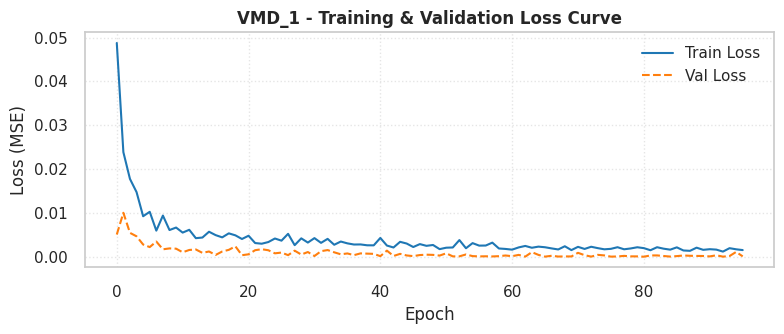

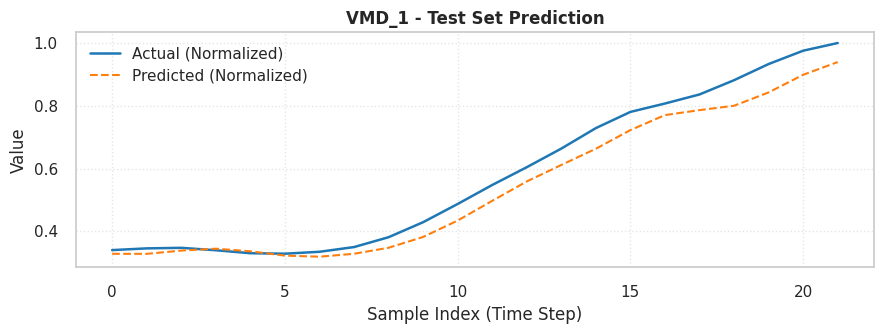

✅ VMD_1 Selesai | Test MAE: 0.040610

▶ Memulai Retrain FINAL untuk sub-mode: VMD_2


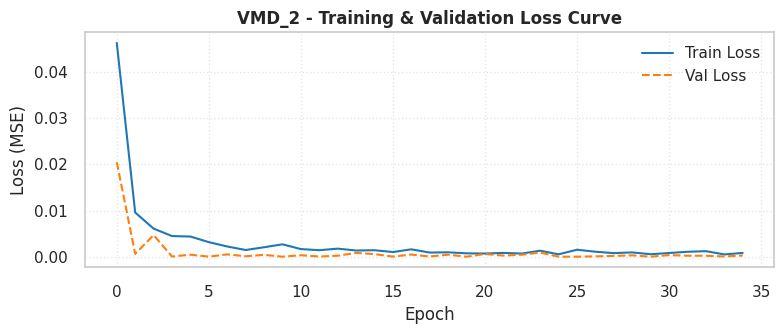

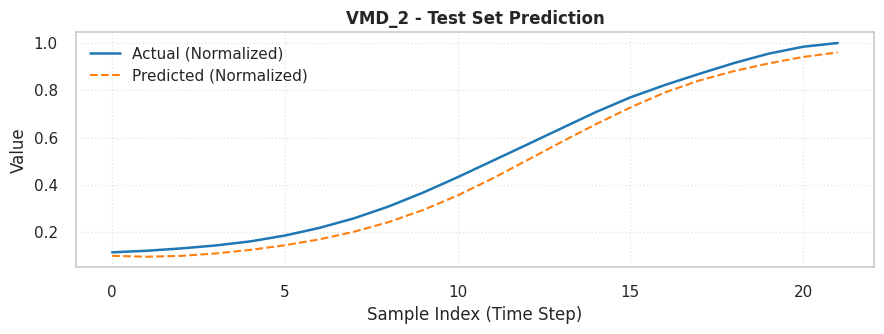

✅ VMD_2 Selesai | Test MAE: 0.046158

▶ Memulai Retrain FINAL untuk sub-mode: VMD_3


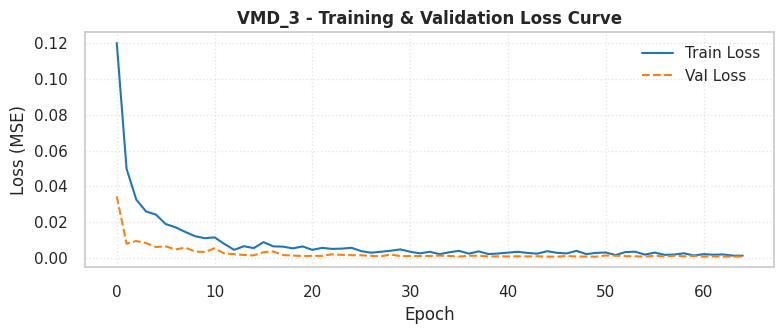

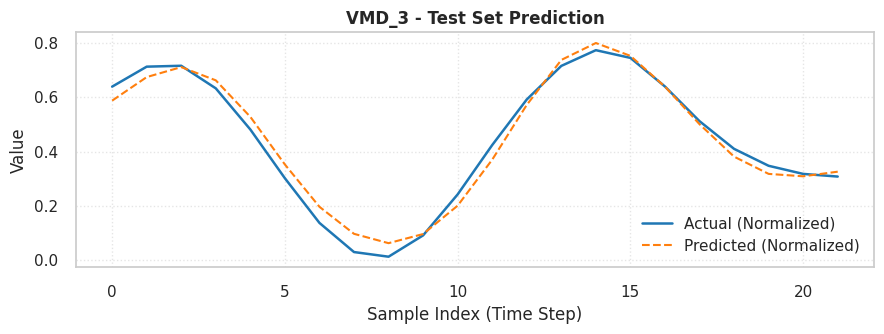

✅ VMD_3 Selesai | Test MAE: 0.030475

▶ Memulai Retrain FINAL untuk sub-mode: VMD_4


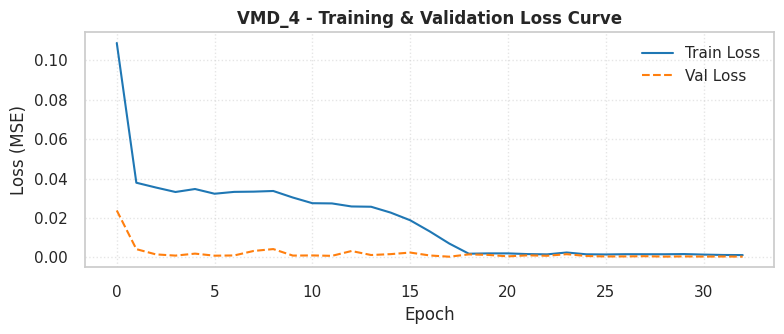

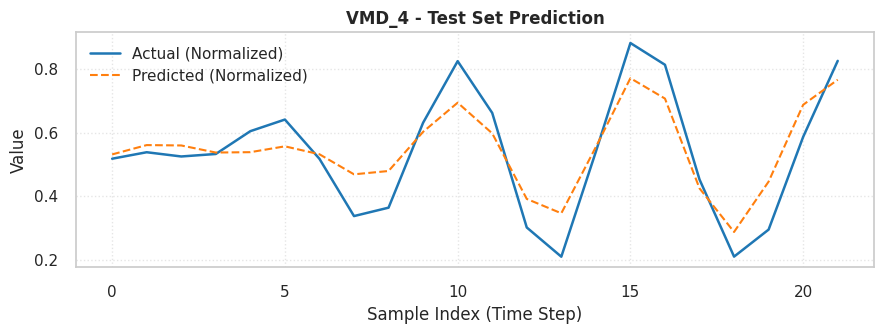

✅ VMD_4 Selesai | Test MAE: 0.071853

▶ Memulai Retrain FINAL untuk sub-mode: VMD_5


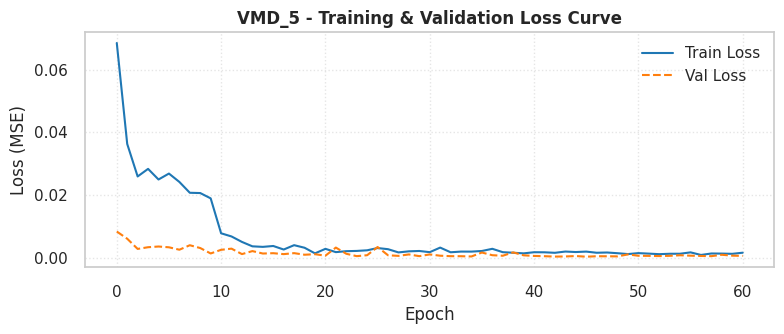

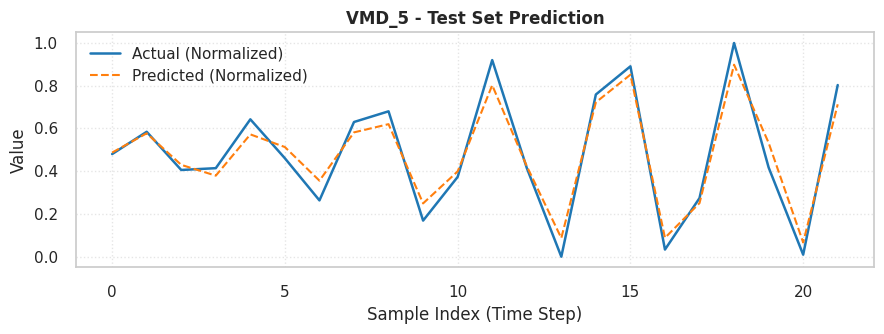

✅ VMD_5 Selesai | Test MAE: 0.056124

▶ Memulai Retrain FINAL untuk sub-mode: VMD_6


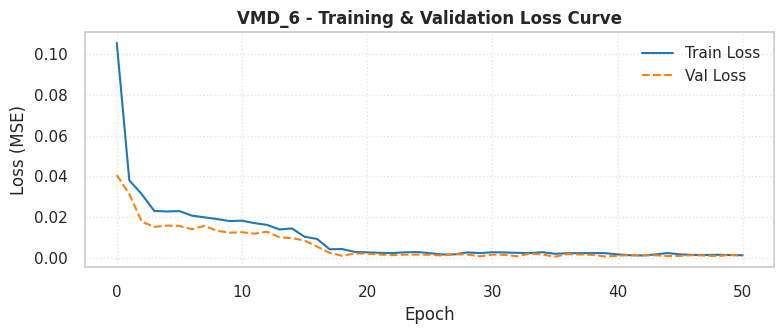

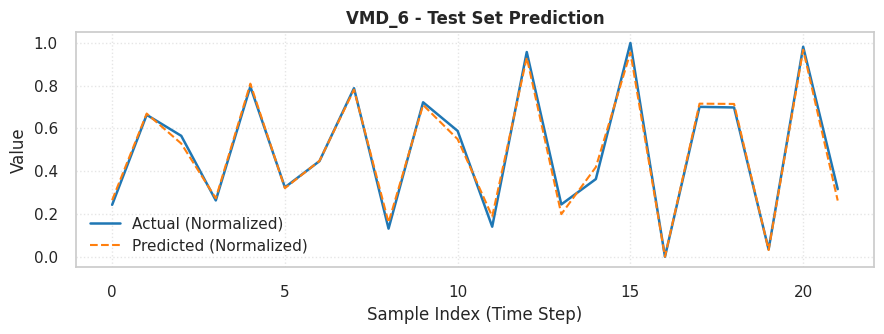

✅ VMD_6 Selesai | Test MAE: 0.022762

▶ Memulai Retrain FINAL untuk sub-mode: VMD_7


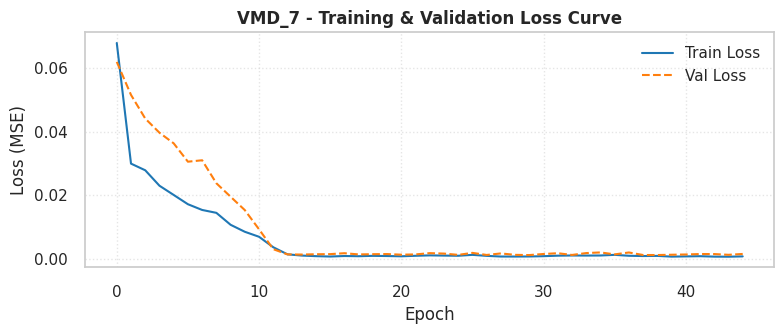

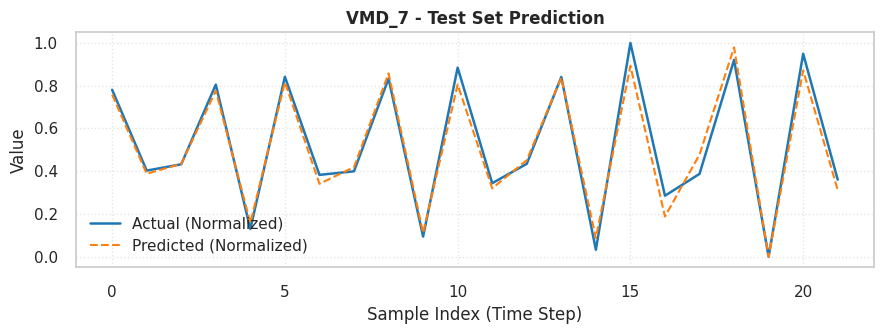

✅ VMD_7 Selesai | Test MAE: 0.040156

▶ Memulai Retrain FINAL untuk sub-mode: VMD_8


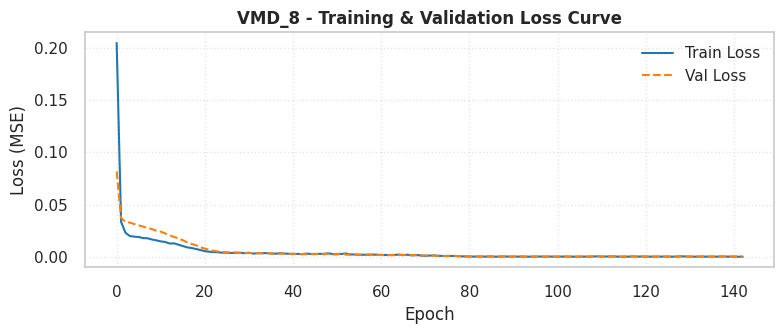

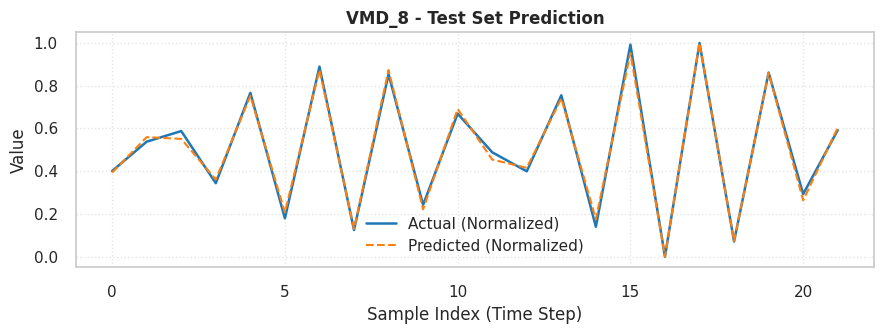

✅ VMD_8 Selesai | Test MAE: 0.017848

▶ Memulai Retrain FINAL untuk sub-mode: VMD_9


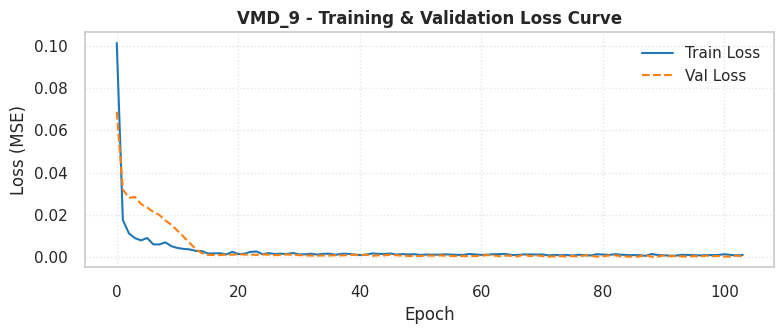

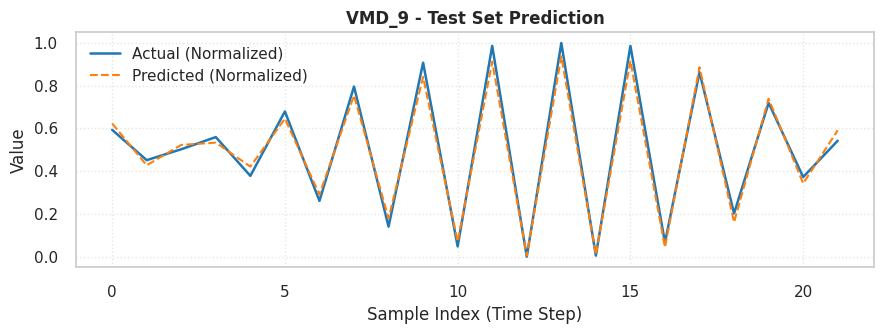

✅ VMD_9 Selesai | Test MAE: 0.035284

▶ Memulai Retrain FINAL untuk sub-mode: VMD_10


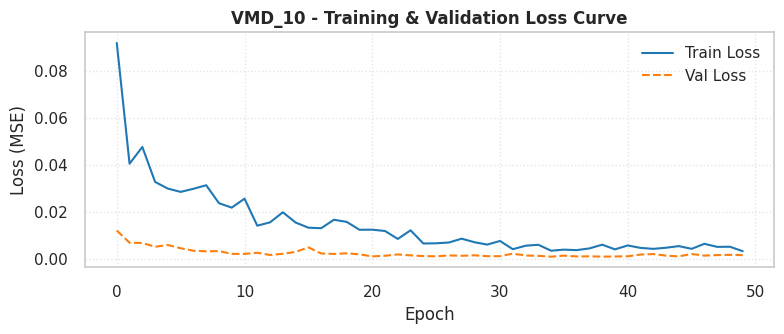

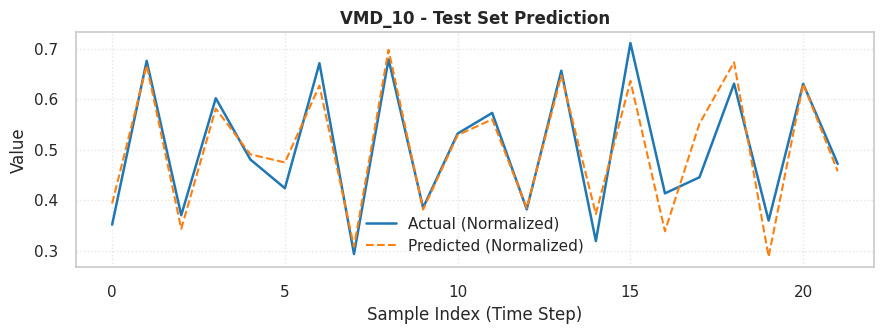

✅ VMD_10 Selesai | Test MAE: 0.032159

▶ Memulai Retrain FINAL untuk sub-mode: VMD_11


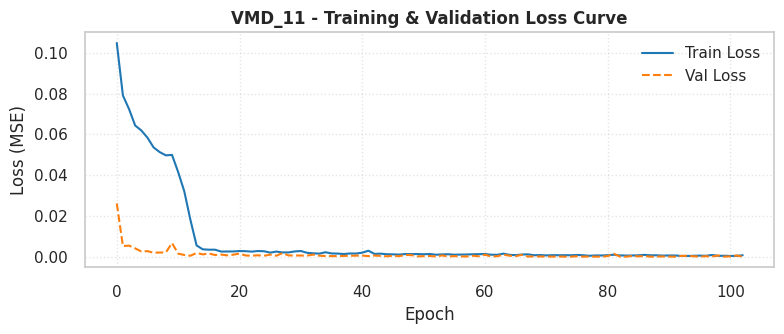

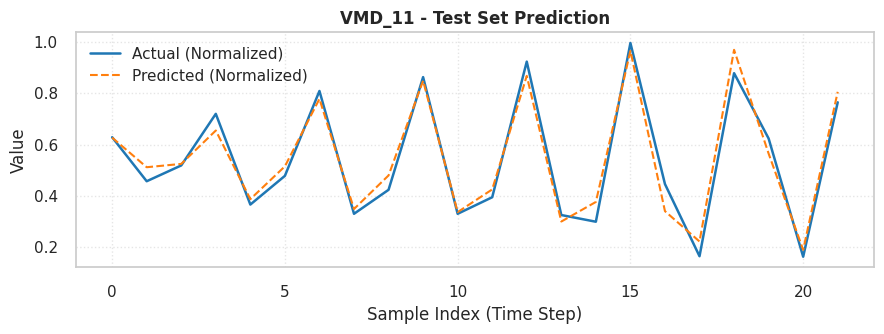

✅ VMD_11 Selesai | Test MAE: 0.041404

▶ Memulai Retrain FINAL untuk sub-mode: VMD_12


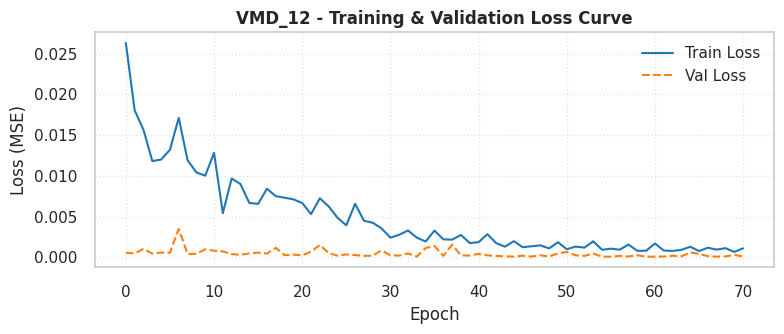

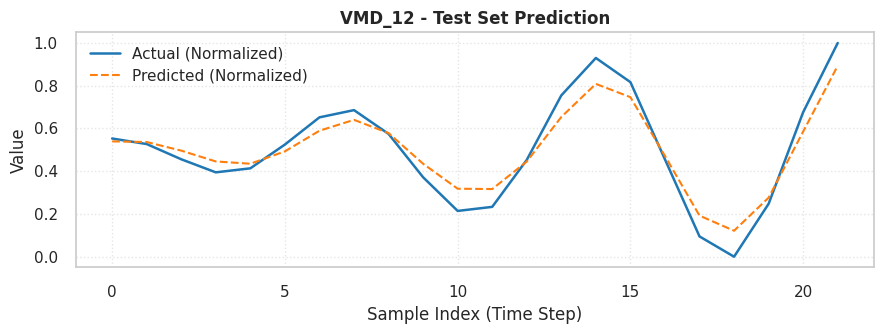

✅ VMD_12 Selesai | Test MAE: 0.058686

📊 RINGKASAN RETRAIN MODEL GRU TERBAIK SELURUH SUB-MODE
Component  Units  Dropout  Learning Rate  Batch Size  Best Epoch  Test MAE  Test RMSE                           Model Path
    VMD_1      8 0.237610          0.003           4          81  0.040610   0.047998  retrain-models/VMD_1_gru_best.keras
    VMD_2     64 0.155471          0.003           8          20  0.046158   0.049165  retrain-models/VMD_2_gru_best.keras
    VMD_3     16 0.115984          0.003           4          50  0.030475   0.036154  retrain-models/VMD_3_gru_best.keras
    VMD_4     24 0.004558          0.003           4          18  0.071853   0.085040  retrain-models/VMD_4_gru_best.keras
    VMD_5     64 0.223634          0.003           4          46  0.056124   0.065440  retrain-models/VMD_5_gru_best.keras
    VMD_6     64 0.155471          0.003           8          36  0.022762   0.028845  retrain-models/VMD_6_gru_best.keras
    VMD_7     64 0.005079          0.003     

In [16]:
import gc
import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Model

# ============================================================================
# Helper 1: Retrain Model Final Satu Sub-Mode / Komponen
# ============================================================================


def retrain_component(
    comp,
    X_train,
    y_train,
    X_test,
    y_test,
    params,
    max_epochs=200,
    patience=20,
    train_val_split=0.10,
    model_dir='retrain-models',
):
  """Retrain model GRU final untuk 1 sub-mode dengan memuat data yang sudah di-split.

  Menggunakan val_split berurutan (tanpa shuffle) untuk Time Series.
  """
  # 1) Internal validation split dari train (time order) untuk Early Stopping
  val_size = int(train_val_split * len(X_train))
  if val_size < 1:
    raise ValueError(
        f'[{comp}] Train terlalu kecil untuk val split. len_train={len(X_train)}'
    )

  X_tr, y_tr = X_train[:-val_size], y_train[:-val_size]
  X_val, y_val = X_train[-val_size:], y_train[-val_size:]

  # 2) Ambil best params hasil tuning Optuna
  units = params.get('units', 16)
  dropout = params.get('dropout', 0.1)
  lr = params.get('learning_rate', 0.001)
  batch_size = params.get('batch_size', 16)

  # 3) Build model GRU
  input_shape = (X_train.shape[1], X_train.shape[2])
  model = create_gru_model(
      units=units,
      dropout_rate=dropout,
      learning_rate=lr,
      input_shape=input_shape,
  )

  # 4) Train dengan EarlyStopping
  early_stop = EarlyStopping(
      monitor='val_loss', patience=patience, restore_best_weights=True
  )

  history = model.fit(
      X_tr,
      y_tr,
      validation_data=(X_val, y_val),
      epochs=max_epochs,
      batch_size=batch_size,
      callbacks=[early_stop],
      verbose=0,
  )

  # Catat epoch terbaik
  best_epoch = int(np.argmin(history.history['val_loss']) + 1)

  # 5) Prediksi pada data Test set
  y_pred = model.predict(X_test, verbose=0).reshape(-1)
  y_pred = np.clip(y_pred, 0.0, 1.0)  # Klipping dalam batas skala normalisasi
  y_true = y_test.reshape(-1)

  test_mae = mean_absolute_error(y_true, y_pred)
  test_rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))

  # 6) Simpan model
  os.makedirs(model_dir, exist_ok=True)
  model_path = os.path.join(model_dir, f'{comp}_gru_best.keras')
  model.save(model_path)

  # ─── [TAMBAHAN] Ambil bobot GRU SEBELUM clear_session, untuk ────
  #     keperluan perhitungan manual forward-pass di Excel nanti.
  #     Layer ke-1 (index 1) pada Sequential = layer GRU
  #     (index 0 = Input layer, tidak punya bobot).
  gru_layer = None
  for layer in model.layers:
    if 'gru' in layer.name.lower():
      gru_layer = layer
      break
  gru_weights = [w.copy() for w in gru_layer.get_weights()] if gru_layer is not None else None

  # Ambil juga output hidden-state GRU (sebelum Dropout & Dense) untuk
  # 1 sampel contoh dari X_test, sebagai pembanding hasil hitung manual
  gru_output_sample = None
  if gru_layer is not None:
    sub_model = Model(inputs=model.inputs, outputs=gru_layer.output)
    gru_output_sample = sub_model.predict(X_test[:1], verbose=0)[0]  # shape (units,)

  # 7) Cleanup session memory
  tf.keras.backend.clear_session()
  gc.collect()

  summary = {
      'Component': comp,
      'Units': units,
      'Dropout': dropout,
      'Learning Rate': lr,
      'Batch Size': batch_size,
      'Best Epoch': best_epoch,
      'Test MAE': float(test_mae),
      'Test RMSE': test_rmse,
      'Model Path': model_path,
  }

  preds_df = pd.DataFrame({'y_true': y_true, 'y_pred': y_pred})

  # ─── [TAMBAHAN] Info tambahan untuk perhitungan manual ────────
  manual_info = {
      'val_size': val_size,
      'n_train_internal': len(X_tr),
      'n_val_internal': len(X_val),
      'units': units,
      'gru_weights': gru_weights,       # [kernel, recurrent_kernel, bias]
      'X_test_sample': X_test[0].copy(),  # shape (WINDOW, 1)
      'gru_output_sample': gru_output_sample,  # shape (units,)
  }

  return summary, preds_df, history, manual_info


# ============================================================================
# Helper 2: Visualisasi Kurva Pembelajaran & Hasil Prediksi
# ============================================================================


def plot_retrain_results(comp, history, preds_df, out_dir='retrain-plots'):
  os.makedirs(out_dir, exist_ok=True)

  # A. Learning Curve
  plt.figure(figsize=(8, 3.5))
  plt.plot(
      history.history['loss'], label='Train Loss', color='#1f77b4', linewidth=1.5
  )
  plt.plot(
      history.history['val_loss'],
      label='Val Loss',
      color='#ff7f0e',
      linestyle='--',
      linewidth=1.5,
  )
  plt.title(f'{comp} - Training & Validation Loss Curve', fontweight='bold')
  plt.xlabel('Epoch')
  plt.ylabel('Loss (MSE)')
  plt.legend()
  plt.grid(True, linestyle=':', alpha=0.5)

  lc_path = os.path.join(out_dir, f'{comp}_learning_curve.png')
  plt.tight_layout()
  plt.savefig(lc_path, dpi=150)
  plt.show()

  # B. Actual vs Predicted (Test Set)
  plt.figure(figsize=(9, 3.5))
  plt.plot(
      preds_df['y_true'].values,
      label='Actual (Normalized)',
      color='#1f77b4',
      linewidth=1.8,
  )
  plt.plot(
      preds_df['y_pred'].values,
      label='Predicted (Normalized)',
      color='#ff7f0e',
      linestyle='--',
      linewidth=1.5,
  )
  plt.title(f'{comp} - Test Set Prediction', fontweight='bold')
  plt.xlabel('Sample Index (Time Step)')
  plt.ylabel('Value')
  plt.legend()
  plt.grid(True, linestyle=':', alpha=0.5)

  pred_path = os.path.join(out_dir, f'{comp}_actual_vs_pred.png')
  plt.tight_layout()
  plt.savefig(pred_path, dpi=150)
  plt.show()

  return lc_path, pred_path


print('✅ Helper function retrain_component dan plot_retrain_results siap.')


# ============================================================================
# MAIN: PENYIAPAN FOLDER SPLIT DATA & PROSES RETRAIN MODEL FINAL
# ============================================================================
split_base_path = 'dataset-split'  # Folder induk
preds_dir = 'retrain-preds'
os.makedirs(preds_dir, exist_ok=True)
os.makedirs(split_base_path, exist_ok=True)

# Ambil daftar seluruh sub-mode / komponen yang telah di-tune oleh Optuna
components = list(best_params.keys())
retrain_summaries = []

# ─── [TAMBAHAN] Tempat menyimpan info manual per komponen ────────
manual_info_all = {}

print('=' * 65)
print('🚀 PROSES RETRAIN MODEL FINAL UNTUK SELURUH SUB-MODE')
print('=' * 65)

for comp in components:
  print(f'\n▶ Memulai Retrain FINAL untuk sub-mode: {comp}')

  # Path folder spesifik per sub-mode (misal: dataset-split/VMD_1)
  comp_path = os.path.join(split_base_path, comp)
  os.makedirs(comp_path, exist_ok=True)

  # 1. Cek apakah file dataset-split sudah tersimpan, jika belum buat secara otomatis
  try:
    X_train = np.load(os.path.join(comp_path, 'X_train.npy'))
    y_train = np.load(os.path.join(comp_path, 'y_train.npy'))
    X_test = np.load(os.path.join(comp_path, 'X_test.npy'))
    y_test = np.load(os.path.join(comp_path, 'y_test.npy'))
  except FileNotFoundError:
    print(
        f'📦 Membentuk & menyimpan dataset-split (80:20) untuk {comp} ke'
        f' {comp_path}...'
    )
    X_full = windowed_data[comp]['X_train']
    y_full = windowed_data[comp]['y_train']
    split_idx = int(len(X_full) * 0.8)
    X_train, X_test = X_full[:split_idx], X_full[split_idx:]
    y_train, y_test = y_full[:split_idx], y_full[split_idx:]
    np.save(os.path.join(comp_path, 'X_train.npy'), X_train)
    np.save(os.path.join(comp_path, 'y_train.npy'), y_train)
    np.save(os.path.join(comp_path, 'X_test.npy'), X_test)
    np.save(os.path.join(comp_path, 'y_test.npy'), y_test)

  # 2. Jalankan pelatihan ulang model GRU
  summary, preds_df, history, manual_info = retrain_component(
      comp=comp,
      X_train=X_train,
      y_train=y_train,
      X_test=X_test,
      y_test=y_test,
      params=best_params[comp],
      max_epochs=200,
      patience=15,
      train_val_split=0.10,
  )
  manual_info_all[comp] = manual_info

  # 3. Visualisasi dan tampilkan hasil retrain
  lc_path, pred_plot_path = plot_retrain_results(
      comp=comp, history=history, preds_df=preds_df, out_dir='retrain-plots'
  )

  retrain_summaries.append(summary)

  # 4. Simpan hasil prediksi test set ke file CSV
  preds_path = os.path.join(preds_dir, f'preds_{comp}.csv')
  preds_df.to_csv(preds_path, index=False)
  # ─── [TAMBAHAN] simpan juga preds_df ke manual_info untuk MAE/RMSE manual
  manual_info_all[comp]['preds_df'] = preds_df

  print(f'✅ {comp} Selesai | Test MAE: {summary["Test MAE"]:.6f}')

# ============================================================================
# RINGKASAN HASIL RETRAIN FINAL
# ============================================================================
retrain_df = pd.DataFrame(retrain_summaries)
retrain_out_dir = 'retrain-results'
os.makedirs(retrain_out_dir, exist_ok=True)
output_summary_csv = os.path.join(
    retrain_out_dir, 'retrain_test_results_per_imf.csv'
)
retrain_df.to_csv(output_summary_csv, index=False)
print('\n' + '=' * 65)
print('📊 RINGKASAN RETRAIN MODEL GRU TERBAIK SELURUH SUB-MODE')
print('=' * 65)
print(retrain_df.to_string(index=False))
print(f'\n💾 Hasil evaluasi retrain disimpan ke: {output_summary_csv}')


# =========================================================================
# =========================================================================
#   EKSPOR EXCEL: PERHITUNGAN MANUAL RETRAIN GRU
#   (Split Internal, Rumus MAE/RMSE, dan Forward-Pass Rumus GRU)
# =========================================================================
# =========================================================================
import openpyxl
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

header_fill = PatternFill('solid', start_color='1F4E79', fgColor='1F4E79')
alt_fill = PatternFill('solid', start_color='D6E4F0', fgColor='D6E4F0')
note_fill = PatternFill('solid', start_color='FFF2CC', fgColor='FFF2CC')
best_fill = PatternFill('solid', start_color='C6EFCE', fgColor='C6EFCE')
header_font = Font(bold=True, color='FFFFFF', name='Arial', size=11)
data_font = Font(name='Arial', size=10)
note_font = Font(name='Arial', size=10, italic=True)
center = Alignment(horizontal='center', vertical='center', wrap_text=True)
left_wrap = Alignment(horizontal='left', vertical='center', wrap_text=True)
thin_border = Border(
    left=Side(style='thin'), right=Side(style='thin'),
    top=Side(style='thin'), bottom=Side(style='thin'),
)


def title_block(ws, r, text, span=7, size=13, height=22):
  ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=span)
  c = ws.cell(row=r, column=1, value=text)
  c.font = Font(bold=True, color='FFFFFF', name='Arial', size=size)
  c.fill = header_fill
  c.alignment = center
  ws.row_dimensions[r].height = height
  return r + 1


def note_block(ws, r, text, span=7, height=32):
  ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=span)
  c = ws.cell(row=r, column=1, value=text)
  c.font = note_font
  c.fill = note_fill
  c.alignment = left_wrap
  ws.row_dimensions[r].height = height
  return r + 1


def table_header(ws, r, headers):
  for ci, h in enumerate(headers, start=1):
    c = ws.cell(row=r, column=ci, value=h)
    c.font = header_font
    c.fill = header_fill
    c.alignment = center
    c.border = thin_border
  return r + 1


def table_row(ws, r, values, alt=False, highlight=False):
  fill = best_fill if highlight else (alt_fill if alt else PatternFill())
  for ci, v in enumerate(values, start=1):
    c = ws.cell(row=r, column=ci, value=v)
    c.font = data_font
    c.fill = fill
    c.alignment = center
    c.border = thin_border
  return r + 1


wb = openpyxl.Workbook()

# ------------------------------------------------------------------
# SHEET 1: Ringkasan Retrain Final
# ------------------------------------------------------------------
ws1 = wb.active
ws1.title = 'Ringkasan_Retrain'
r = 1
r = title_block(ws1, r, 'Ringkasan Hasil Retrain Model GRU Final per Sub-Mode', span=9)
r += 1
r = table_header(ws1, r, ['Component', 'Units', 'Dropout', 'Learning Rate', 'Batch Size', 'Best Epoch', 'Test MAE', 'Test RMSE', 'Model Path'])
for i, row in retrain_df.iterrows():
  r = table_row(
      ws1, r,
      [
          row['Component'], row['Units'], round(float(row['Dropout']), 4),
          row['Learning Rate'], row['Batch Size'], row['Best Epoch'],
          round(float(row['Test MAE']), 6), round(float(row['Test RMSE']), 6),
          row['Model Path'],
      ],
      alt=(i % 2 == 0), highlight=True,
  )
for i, w in enumerate([20, 10, 12, 14, 12, 12, 14, 14, 30], start=1):
  ws1.column_dimensions[get_column_letter(i)].width = w

# ------------------------------------------------------------------
# SHEET 2: Perhitungan Manual — Split Internal Train/Val (90:10)
# ------------------------------------------------------------------
ws2 = wb.create_sheet('Perhitungan_Manual_Split')
r = 1
r = title_block(ws2, r, 'PERHITUNGAN MANUAL SPLIT INTERNAL TRAIN-VALIDATION (90:10) UNTUK RETRAIN', span=6, size=14)
r = note_block(
    ws2, r,
    'Rumus: val_size = int(train_val_split x len(X_train)) = int(0.10 x len(X_train)). '
    'X_tr = X_train[:-val_size] (data awal), X_val = X_train[-val_size:] (data akhir, berurutan waktu).',
    span=6, height=32,
)
r += 1
r = table_header(ws2, r, ['Component', 'len(X_train)', 'val_size = int(0.10 x N)', 'n_train_internal', 'n_val_internal', 'Verifikasi n_tr+n_val=N'])
for i, comp in enumerate(components):
  info = manual_info_all[comp]
  n_total = info['n_train_internal'] + info['n_val_internal']
  cek = 'OK ✅' if n_total == info['n_train_internal'] + info['n_val_internal'] else '-'
  r = table_row(
      ws2, r,
      [comp, n_total, info['val_size'], info['n_train_internal'], info['n_val_internal'], cek],
      alt=(i % 2 == 0),
  )
for i, w in enumerate([20, 14, 22, 16, 16, 22], start=1):
  ws2.column_dimensions[get_column_letter(i)].width = w

# ------------------------------------------------------------------
# SHEET 3: Perhitungan Manual — Rumus Test MAE & RMSE
# ------------------------------------------------------------------
ws3 = wb.create_sheet('Perhitungan_Manual_MAE_RMSE')
r = 1
r = title_block(ws3, r, 'PERHITUNGAN MANUAL TEST MAE & RMSE', span=6, size=14)
r = note_block(
    ws3, r,
    'MAE = (1/n) x Σ|y_true - y_pred|   ;   RMSE = √[(1/n) x Σ(y_true - y_pred)²]. '
    'Ilustrasi berikut menggunakan 5 data pertama set Test untuk 2 komponen contoh, '
    'lalu diverifikasi terhadap hasil sklearn (Test MAE / Test RMSE) pada seluruh data.',
    span=6, height=44,
)
r += 1

contoh_komponen = components[: min(2, len(components))]
for comp in contoh_komponen:
  preds_df_c = manual_info_all[comp]['preds_df']
  n_preview = min(5, len(preds_df_c))
  y_true_prev = preds_df_c['y_true'].values[:n_preview]
  y_pred_prev = preds_df_c['y_pred'].values[:n_preview]

  test_mae_full = retrain_df.loc[retrain_df['Component'] == comp, 'Test MAE'].values[0]
  test_rmse_full = retrain_df.loc[retrain_df['Component'] == comp, 'Test RMSE'].values[0]

  r = title_block(ws3, r, f'Komponen: {comp}', span=6, size=12)
  r = table_header(ws3, r, ['g (Titik ke-)', 'y_true', 'y_pred', '|y_true - y_pred|', '(y_true - y_pred)²', ''][:5])
  abs_err, sq_err = [], []
  for i in range(n_preview):
    ae = abs(y_true_prev[i] - y_pred_prev[i])
    se = (y_true_prev[i] - y_pred_prev[i]) ** 2
    abs_err.append(ae)
    sq_err.append(se)
    r = table_row(ws3, r, [i + 1, round(float(y_true_prev[i]), 6), round(float(y_pred_prev[i]), 6), round(float(ae), 6), round(float(se), 6)][:5], alt=(i % 2 == 0))

  mae_prev = sum(abs_err) / n_preview
  rmse_prev = (sum(sq_err) / n_preview) ** 0.5
  r = note_block(
      ws3, r,
      f'MAE (5 data) = Σ|y_true-y_pred|/n = {sum(abs_err):.6f}/{n_preview} = {mae_prev:.6f}   ;   '
      f'RMSE (5 data) = √(Σ(y_true-y_pred)²/n) = √({sum(sq_err):.6f}/{n_preview}) = {rmse_prev:.6f}\n'
      f'Test MAE (seluruh data, sklearn) = {test_mae_full:.6f}   ;   Test RMSE (seluruh data, sklearn) = {test_rmse_full:.6f}',
      span=6, height=44,
  )
  r += 1

for i in range(1, 7):
  ws3.column_dimensions[get_column_letter(i)].width = 22

# ------------------------------------------------------------------
# SHEET 4: Perhitungan Manual — Forward-Pass Rumus Sel GRU
# ------------------------------------------------------------------
ws4 = wb.create_sheet('Perhitungan_Manual_GRU')
r = 1
r = title_block(ws4, r, 'PERHITUNGAN MANUAL FORWARD-PASS SEL GRU (Menggunakan Bobot Hasil Training Nyata)', span=8, size=14)
r = note_block(
    ws4, r,
    'Rumus GRU (reset_after=True, default Keras/TensorFlow):\n'
    'z_t = sigmoid(x_t.W_z + b_iz + h_(t-1).U_z + b_hz)      [update gate]\n'
    'r_t = sigmoid(x_t.W_r + b_ir + h_(t-1).U_r + b_hr)      [reset gate]\n'
    'n_t = tanh(x_t.W_h + b_ih + r_t * (h_(t-1).U_h + b_hh)) [candidate hidden state]\n'
    'h_t = (1 - z_t) * n_t + z_t * h_(t-1)                    [hidden state akhir]\n'
    'Ilustrasi berikut menggunakan bobot (kernel/recurrent_kernel/bias) hasil training NYATA dari model, '
    'dihitung untuk HIDDEN UNIT PERTAMA (indeks 0) saja pada setiap langkah waktu (agar tabel ringkas). '
    'Input berasal dari 1 sampel data Test pertama.',
    span=8, height=90,
)
r += 1

# Ambil komponen pertama sebagai contoh forward-pass
comp_gru = components[0]
info_gru = manual_info_all[comp_gru]
kernel, recurrent_kernel, bias = info_gru['gru_weights']  # bias shape (2, 3*units) jika reset_after=True
units_gru = info_gru['units']
x_seq = info_gru['X_test_sample'].reshape(-1)  # shape (WINDOW,)
gru_output_actual = info_gru['gru_output_sample']  # shape (units,), hasil Keras asli

# Pisahkan kernel & recurrent_kernel menjadi bagian z, r, h (urutan default Keras)
Wz, Wr, Wh = np.split(kernel, 3, axis=1)          # masing2 shape (input_dim=1, units)
Uz, Ur, Uh = np.split(recurrent_kernel, 3, axis=1)  # masing2 shape (units, units)

if bias.ndim == 2 and bias.shape[0] == 2:
  # reset_after=True: bias[0]=input_bias, bias[1]=recurrent_bias
  b_iz, b_ir, b_ih = np.split(bias[0], 3)
  b_hz, b_hr, b_hh = np.split(bias[1], 3)
else:
  # reset_after=False: bias tunggal, digabung ke sisi input saja
  b_iz, b_ir, b_ih = np.split(bias, 3)
  b_hz = b_hr = b_hh = np.zeros(units_gru)


def sigmoid(x):
  return 1.0 / (1.0 + np.exp(-x))


# Hitung forward-pass manual untuk SELURUH unit (agar h_(t-1) benar secara matematis),
# lalu yang ditampilkan ke tabel hanya unit ke-0 untuk keringkasan.
h_prev = np.zeros(units_gru)
window_len = len(x_seq)
manual_gru_rows = []
for t in range(window_len):
  x_t = np.array([x_seq[t]])  # shape (1,) karena input_dim=1

  z_t = sigmoid(x_t @ Wz + b_iz + h_prev @ Uz + b_hz)
  r_t = sigmoid(x_t @ Wr + b_ir + h_prev @ Ur + b_hr)
  n_t = np.tanh(x_t @ Wh + b_ih + r_t * (h_prev @ Uh + b_hh))
  h_t = (1 - z_t) * n_t + z_t * h_prev

  manual_gru_rows.append({
      't': t + 1,
      'x_t': float(x_t[0]),
      'z_t[0]': float(z_t[0]),
      'r_t[0]': float(r_t[0]),
      'n_t[0]': float(n_t[0]),
      'h_t[0]': float(h_t[0]),
  })
  h_prev = h_t

r = title_block(ws4, r, f'Komponen contoh: {comp_gru}  (units = {units_gru}, WINDOW = {window_len})', span=8, size=12)
r = table_header(ws4, r, ['t (langkah waktu)', 'x_t', 'z_t[0] (update gate)', 'r_t[0] (reset gate)', 'n_t[0] (candidate)', 'h_t[0] (hidden state)', '', ''])
for i, row in enumerate(manual_gru_rows):
  r = table_row(
      ws4, r,
      [row['t'], round(row['x_t'], 6), round(row['z_t[0]'], 6), round(row['r_t[0]'], 6), round(row['n_t[0]'], 6), round(row['h_t[0]'], 6), '', ''],
      alt=(i % 2 == 0),
  )

h_final_manual_unit0 = manual_gru_rows[-1]['h_t[0]']
h_final_actual_unit0 = float(gru_output_actual[0]) if gru_output_actual is not None else None
cocok_gru = (
    'COCOK ✅' if (h_final_actual_unit0 is not None and abs(h_final_manual_unit0 - h_final_actual_unit0) < 1e-4)
    else ('TIDAK DAPAT DIVERIFIKASI' if h_final_actual_unit0 is None else 'TIDAK COCOK ❌')
)
r = note_block(
    ws4, r,
    f'h_T[0] hasil perhitungan manual (t=T={window_len}) = {h_final_manual_unit0:.6f}\n'
    f'h_T[0] hasil output GRU layer Keras (data nyata) = {h_final_actual_unit0:.6f}\n'
    f'Verifikasi kesesuaian rumus manual dengan implementasi Keras → {cocok_gru}',
    span=8, height=56,
)

for i in range(1, 9):
  ws4.column_dimensions[get_column_letter(i)].width = 20

# ─── SIMPAN FILE EXCEL ──────────────────────────────────────────────
xlsx_path_retrain = os.path.join(retrain_out_dir, 'retrain_gru_hasil_lengkap.xlsx')
wb.save(xlsx_path_retrain)
print(f'\n💾 Excel lengkap retrain GRU disimpan: {xlsx_path_retrain}')
print('   Sheet: Ringkasan_Retrain, Perhitungan_Manual_Split, Perhitungan_Manual_MAE_RMSE, Perhitungan_Manual_GRU')

📊 EVALUASI DENORMALISASI & REKONSTRUKSI PREDIKSI VMD

🔍 Evaluasi Prediksi Per Sub-Mode / Komponen:


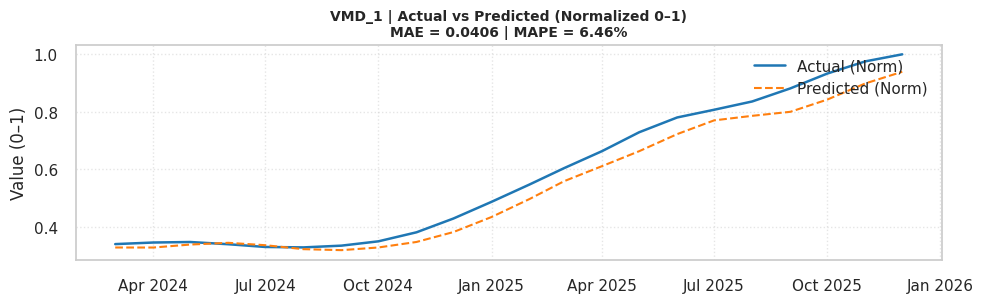

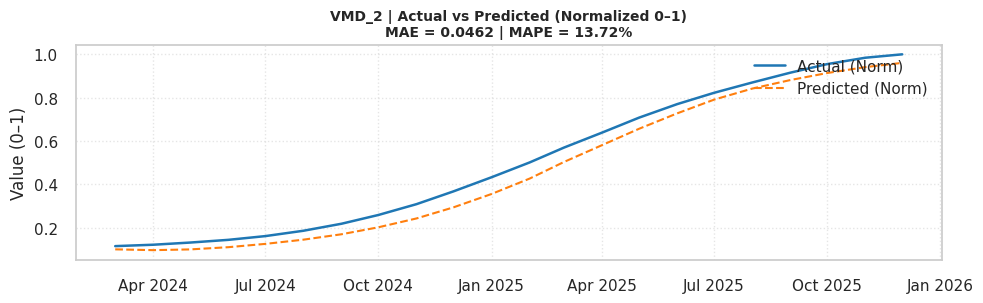

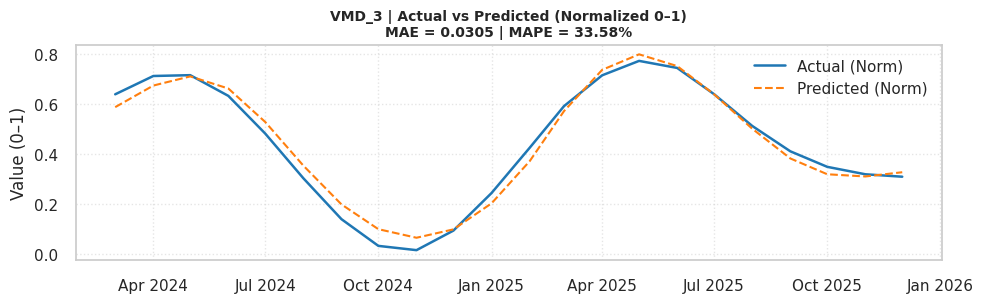

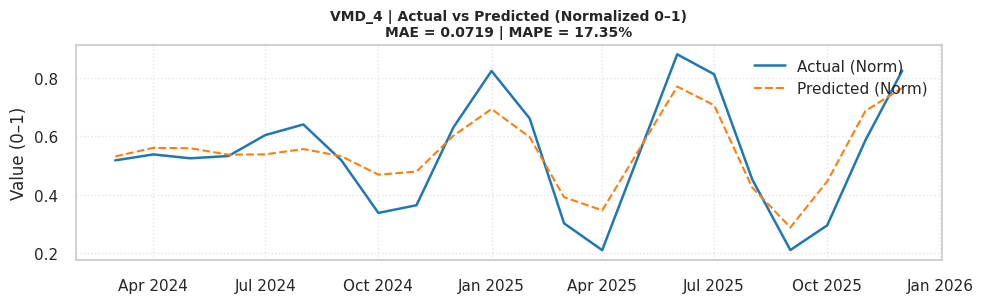

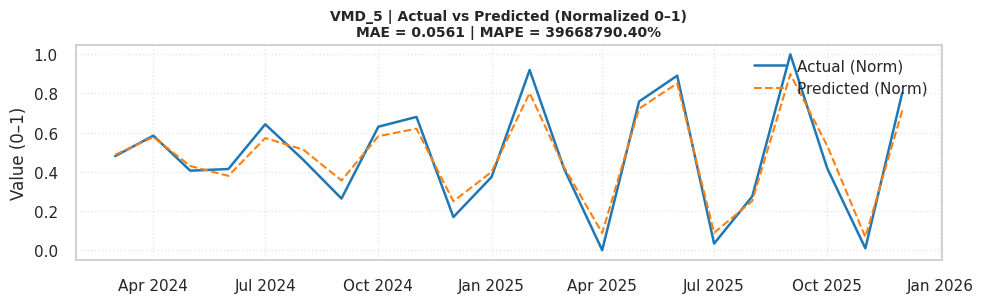

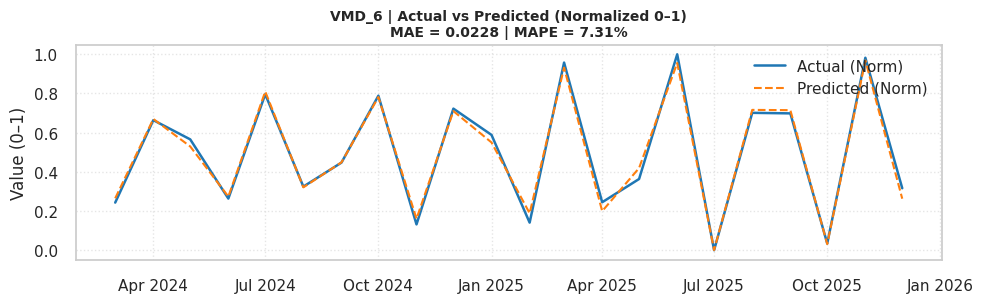

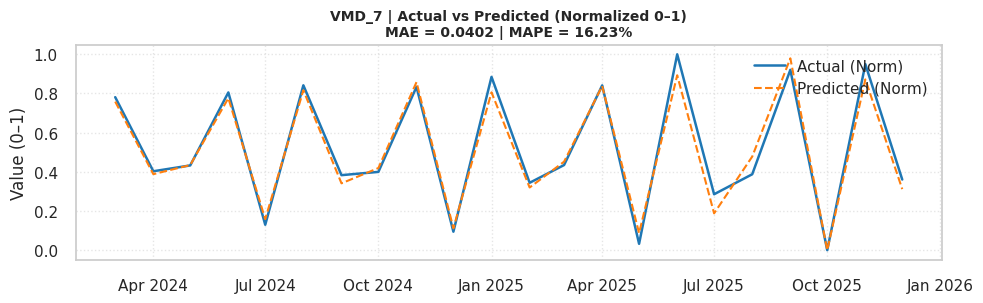

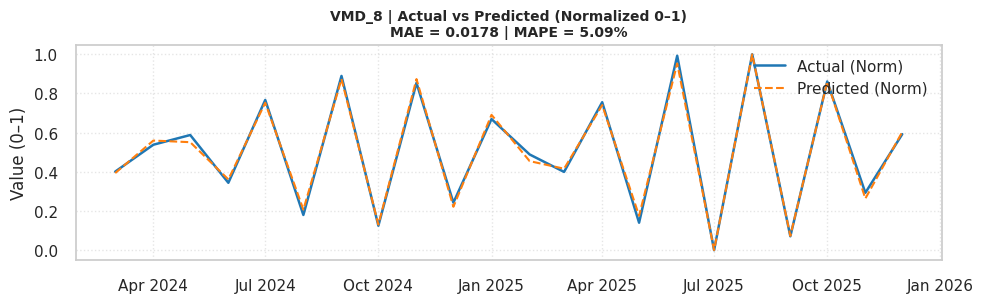

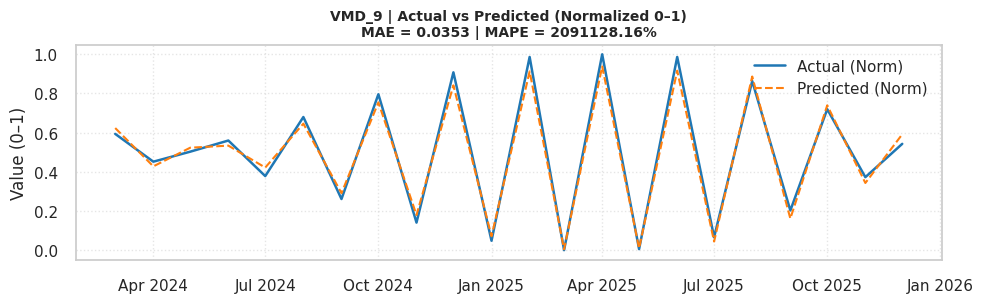

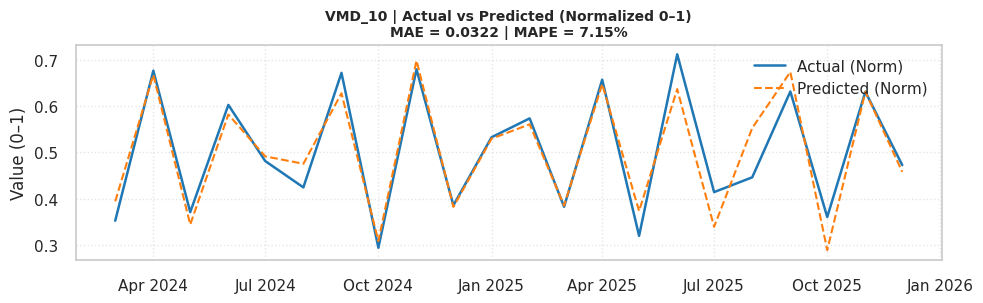

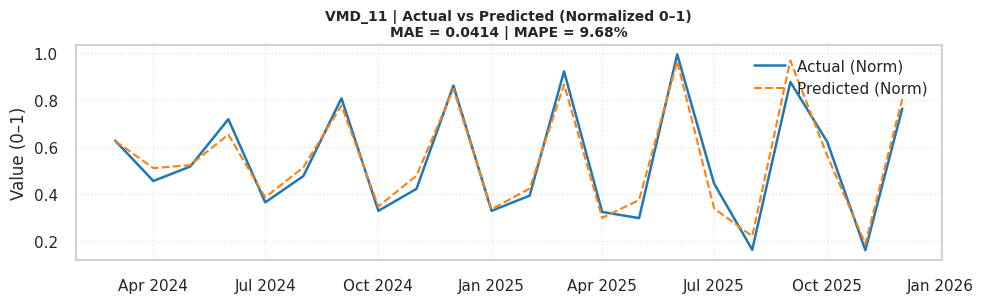

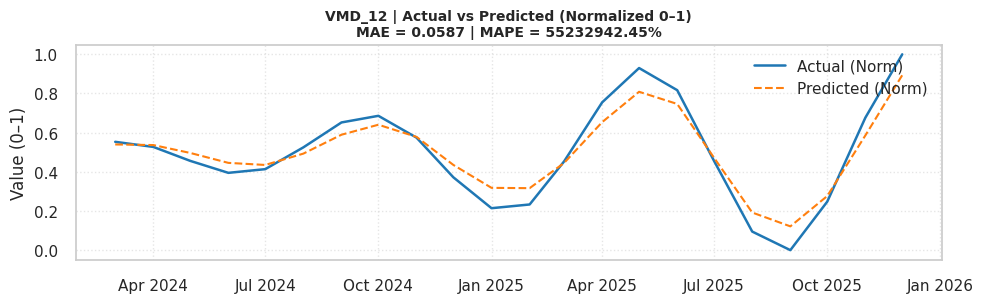


📋 Metrik Evaluasi Prediksi Per Sub-Mode / Komponen:


,Sub-Component,MAE (Norm),RMSE (Norm),MAPE (Norm) %
0,VMD_1,0.040610,0.047998,6.456148e+00
1,VMD_2,0.046158,0.049165,1.371617e+01
2,VMD_3,0.030475,0.036154,3.357888e+01
3,VMD_4,0.071853,0.085040,1.735389e+01
4,VMD_5,0.056124,0.065440,3.966879e+07
5,VMD_6,0.022762,0.028845,7.314427e+00
6,VMD_7,0.040156,0.050951,1.623228e+01
7,VMD_8,0.017848,0.021443,5.094614e+00
8,VMD_9,0.035284,0.040010,2.091128e+06
9,VMD_10,0.032159,0.043223,7.147803e+00



📋 TABEL AKTUAL vs PREDIKSI REKONSTRUKSI (NORMALIZED 0–1)


,Date,Actual_Signal_Norm,Predicted_Signal_Norm,Abs_Error
0,2024-03-01,0.137769,0.123884,0.013885
1,2024-04-01,0.184140,0.170087,0.014053
2,2024-05-01,0.118952,0.122794,0.003843
3,2024-06-01,0.094086,0.091506,0.002581
4,2024-07-01,0.104839,0.096645,0.008193
5,2024-08-01,0.094086,0.069245,0.024841
6,2024-09-01,0.109543,0.087159,0.022384
7,2024-10-01,0.105511,0.091008,0.014502
8,2024-11-01,0.094758,0.105483,0.010725
9,2024-12-01,0.060484,0.050094,0.010390



✅ EVALUASI AKHIR SINYAL REKONSTRUKSI (NORMALIZED 0–1):
   MAE  : 0.0335
   RMSE : 0.0443
   MAPE : 12.49%


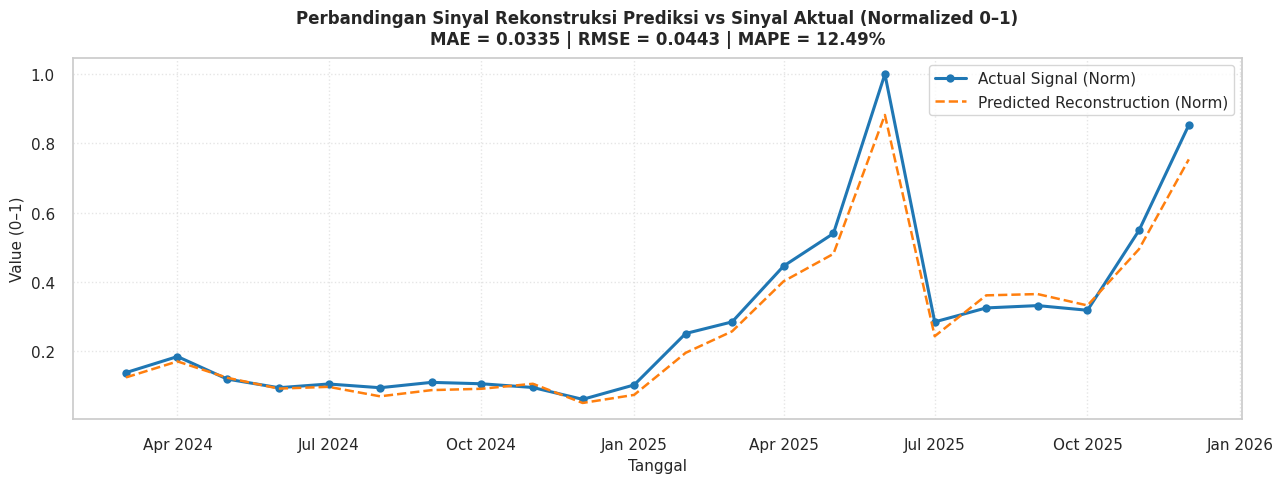

💾 Grafik disimpan: output_hasil/grafik/06_final_reconstruction_prediction_norm.png


In [17]:
import os
import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error


# ==================================================
# Helper 1: Safe MAPE (0–100%)
# ==================================================
def safe_mape(y_true, y_pred, eps=1e-8):
  y_true = np.asarray(y_true).reshape(-1)
  y_pred = np.asarray(y_pred).reshape(-1)
  denom = np.maximum(np.abs(y_true), eps)
  return float(np.mean(np.abs((y_true - y_pred) / denom)))


# ==================================================
# PATH & SETUP LOKASI FILE
# ==================================================
preds_dir = 'retrain-preds'
scaler_dir = 'scaler'

print('=' * 75)
print('📊 EVALUASI DENORMALISASI & REKONSTRUKSI PREDIKSI VMD')
print('=' * 75)

# ==================================================
# 1) PENYIAPAN DATA AKTUAL & SIGNAL ASLI
# ==================================================
# Memastikan data_clean atau file Excel dapat diakses
if 'data_clean' in globals():
  df_raw = data_clean.copy()
else:
  import glob

  files = glob.glob('*.xlsx')
  df_raw = pd.read_excel(files[0])
  df_raw['Tahun'] = df_raw['Tahun'].ffill().astype(int)
  bulan_map = {
      'Januari': 'January',
      'Februari': 'February',
      'Maret': 'March',
      'April': 'April',
      'Mei': 'May',
      'Juni': 'June',
      'Juli': 'July',
      'Agustus': 'August',
      'September': 'September',
      'Oktober': 'October',
      'November': 'November',
      'Desember': 'December',
  }
  date_str = (
      df_raw['Bulan'].astype(str).str.strip().replace(bulan_map, regex=True)
      + ' '
      + df_raw['Tahun'].astype(str)
  )
  df_raw['date'] = pd.to_datetime(date_str, format='%B %Y')
  df_raw['visitors'] = df_raw['Pengunjung']

# Ambil min dan max asli dari sinyal sebelum normalisasi
orig_min = float(df_raw['visitors'].min())
orig_max = float(df_raw['visitors'].max())

# Normalized signal aktual 0–1
df_norm = df_raw.copy()
df_norm['visitors_norm'] = (df_raw['visitors'] - orig_min) / (
    orig_max - orig_min + 1e-8
)

# ==================================================
# 2) PANJANG TEST SET & PENYELARASAN DATES
# ==================================================
# Ambil komponen dari best_params
components = list(best_params.keys())
sample_comp = components[0]
sample_preds = pd.read_csv(os.path.join(preds_dir, f'preds_{sample_comp}.csv'))
test_len = len(sample_preds)

# Ambil tanggal dan nilai aktual normalisasi khusus test set
test_dates = df_norm['date'].iloc[-test_len:].values
actual_test_signal_norm = (
    df_norm['visitors_norm'].iloc[-test_len:].values.astype(float)
)

# ==================================================
# 3) LOOP EVALUASI PER SUB-MODE / KOMPONEN (NORMALIZED)
# ==================================================
y_pred_den_dict = {}
imf_metrics_rows = []

print('\n🔍 Evaluasi Prediksi Per Sub-Mode / Komponen:')

for comp in components:
  pred_file = os.path.join(preds_dir, f'preds_{comp}.csv')
  if not os.path.exists(pred_file):
    print(f'⚠️ Warning: File {pred_file} tidak ditemukan. Skip...')
    continue

  dfp = pd.read_csv(pred_file)
  y_true_norm = dfp['y_true'].values.astype(float)
  y_pred_norm = dfp['y_pred'].values.astype(float)

  # Inverse transform / denormalisasi ke skala asli sub-mode
  scaler_file = os.path.join(scaler_dir, f'scaler_{comp}.pkl')
  if os.path.exists(scaler_file):
    scaler = joblib.load(scaler_file)
    y_pred_den_dict[comp] = scaler.inverse_transform(
        y_pred_norm.reshape(-1, 1)
    ).ravel()
  else:
    y_pred_den_dict[comp] = y_pred_norm

  # Metrik performa per sub-mode (Normalized 0–1)
  imf_mae = mean_absolute_error(y_true_norm, y_pred_norm)
  imf_rmse = float(np.sqrt(mean_squared_error(y_true_norm, y_pred_norm)))
  imf_mape = safe_mape(y_true_norm, y_pred_norm) * 100

  imf_metrics_rows.append({
      'Sub-Component': comp,
      'MAE (Norm)': imf_mae,
      'RMSE (Norm)': imf_rmse,
      'MAPE (Norm) %': imf_mape,
  })

  # Visualisasi Per Sub-Mode
  plt.figure(figsize=(10, 3.2))
  plt.plot(
      test_dates,
      y_true_norm,
      label='Actual (Norm)',
      color='#1f77b4',
      linewidth=1.8,
  )
  plt.plot(
      test_dates,
      y_pred_norm,
      label='Predicted (Norm)',
      color='#ff7f0e',
      linestyle='--',
      linewidth=1.5,
  )
  plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
  plt.title(
      f'{comp} | Actual vs Predicted (Normalized 0–1)\nMAE = {imf_mae:.4f} |'
      f' MAPE = {imf_mape:.2f}%',
      fontsize=10,
      fontweight='bold',
  )
  plt.ylabel('Value (0–1)')
  plt.legend(loc='upper right')
  plt.grid(True, linestyle=':', alpha=0.5)
  plt.tight_layout()
  plt.show()

# Tabel Ringkasan Metrik Per Sub-Mode
imf_metrics_df = pd.DataFrame(imf_metrics_rows)
print('\n📋 Metrik Evaluasi Prediksi Per Sub-Mode / Komponen:')
display(imf_metrics_df)

# ==================================================
# 4) REKONSTRUKSI SINYAL PREDIKSI (SKALA ASLI -> NORMALIZED)
# ==================================================
# Sum of all predicted sub-modes in original scale
x_pred_recon = np.sum(
    [y_pred_den_dict[c] for c in y_pred_den_dict.keys()], axis=0
)

# Normalisasi hasil rekonstruksi prediksi ke skala 0–1 menggunakan min-max asli
x_pred_norm_final = (x_pred_recon - orig_min) / (orig_max - orig_min + 1e-8)
x_pred_norm_final = np.clip(x_pred_norm_final, 0.0, 1.0)

x_true_norm_final = actual_test_signal_norm

# ==================================================
# 5) METRIK FINAL HASIL REKONSTRUKSI
# ==================================================
final_mae_norm = mean_absolute_error(x_true_norm_final, x_pred_norm_final)
final_rmse_norm = float(
    np.sqrt(mean_squared_error(x_true_norm_final, x_pred_norm_final))
)
final_mape_norm = safe_mape(x_true_norm_final, x_pred_norm_final) * 100

df_recon_norm = pd.DataFrame({
    'Date': [str(d)[:10] for d in test_dates],
    'Actual_Signal_Norm': x_true_norm_final,
    'Predicted_Signal_Norm': x_pred_norm_final,
})
df_recon_norm['Abs_Error'] = np.abs(
    df_recon_norm['Actual_Signal_Norm'] - df_recon_norm['Predicted_Signal_Norm']
)

print('\n' + '=' * 75)
print('📋 TABEL AKTUAL vs PREDIKSI REKONSTRUKSI (NORMALIZED 0–1)')
print('=' * 75)
display(df_recon_norm)

print('\n✅ EVALUASI AKHIR SINYAL REKONSTRUKSI (NORMALIZED 0–1):')
print(f'   MAE  : {final_mae_norm:.4f}')
print(f'   RMSE : {final_rmse_norm:.4f}')
print(f'   MAPE : {final_mape_norm:.2f}%')

# ==================================================
# 6) VISUALISASI REKONSTRUKSI AKHIR
# ==================================================
plt.figure(figsize=(13, 5))
plt.plot(
    test_dates,
    x_true_norm_final,
    label='Actual Signal (Norm)',
    color='#1f77b4',
    linewidth=2.2,
    marker='o',
)
plt.plot(
    test_dates,
    x_pred_norm_final,
    label='Predicted Reconstruction (Norm)',
    color='#ff7f0e',
    linestyle='--',
    linewidth=1.8,
    marker='x',
)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.title(
    'Perbandingan Sinyal Rekonstruksi Prediksi vs Sinyal Aktual (Normalized'
    ' 0–1)\n'
    f'MAE = {final_mae_norm:.4f} | RMSE = {final_rmse_norm:.4f} | MAPE ='
    f' {final_mape_norm:.2f}%',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
plt.xlabel('Tanggal', fontsize=11)
plt.ylabel('Value (0–1)', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()

# Simpan Grafik Evaluasi Final Rekonstruksi
os.makedirs('output_hasil/grafik', exist_ok=True)
plt.savefig(
    'output_hasil/grafik/06_final_reconstruction_prediction_norm.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

print(
    '💾 Grafik disimpan:'
    ' output_hasil/grafik/06_final_reconstruction_prediction_norm.png'
)

📊 EVALUASI PREDIKSI REKONSTRUKSI DALAM SKALA ASLI (DENORMALIZED)

🔍 Evaluasi Prediksi Per Sub-Mode (Skala Asli Sub-Komponen):


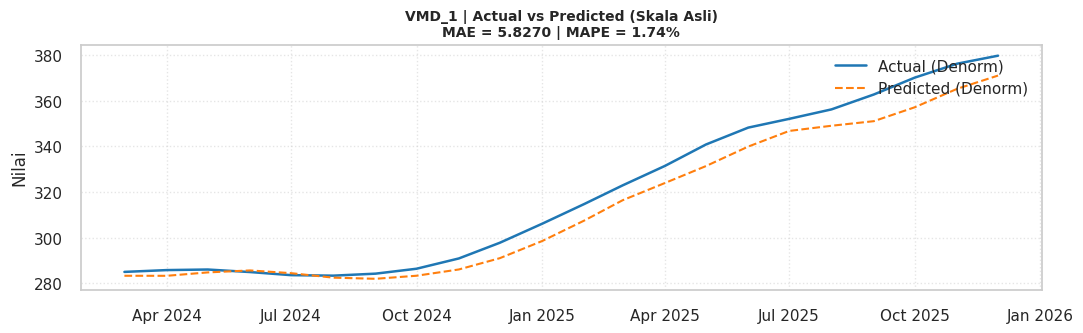

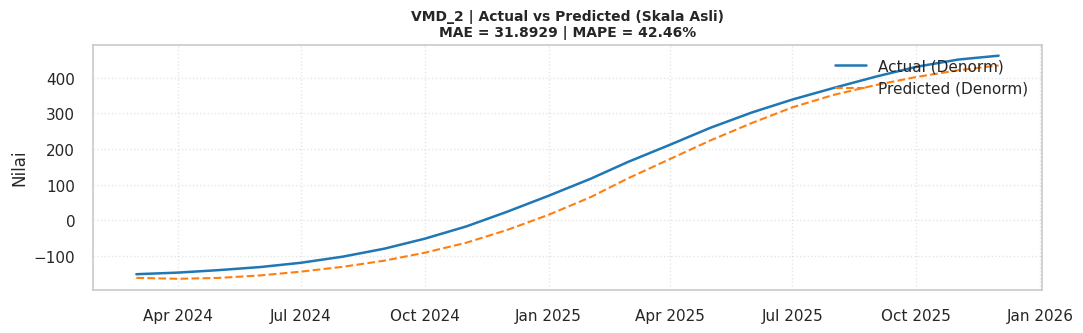

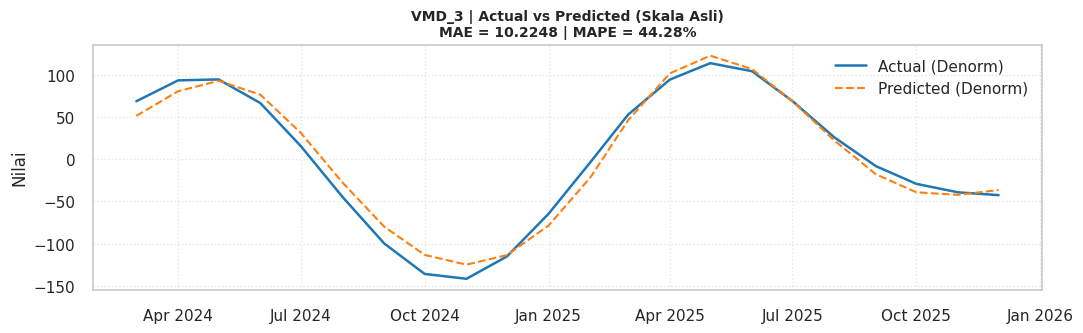

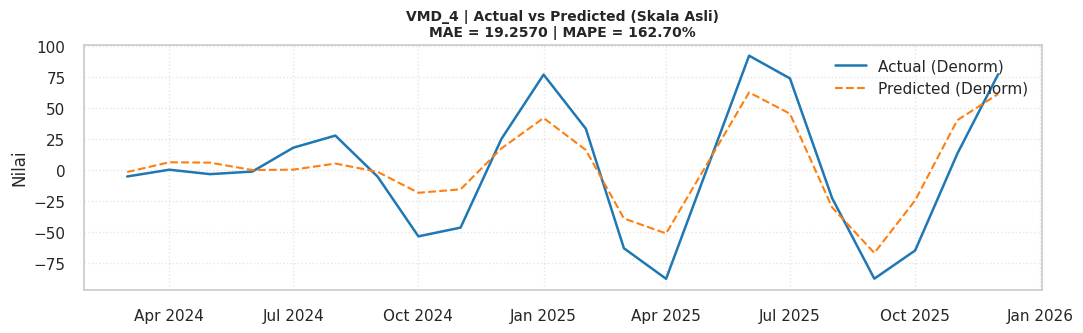

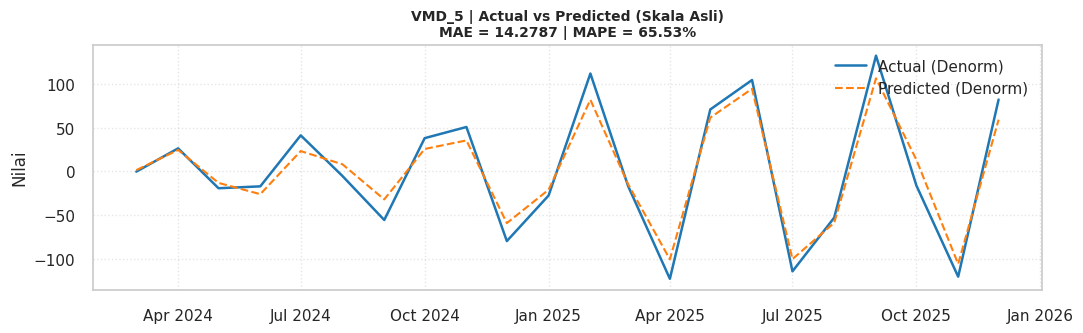

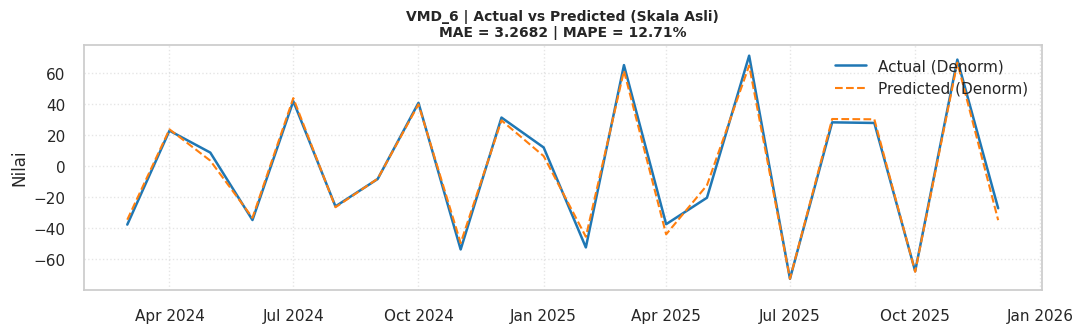

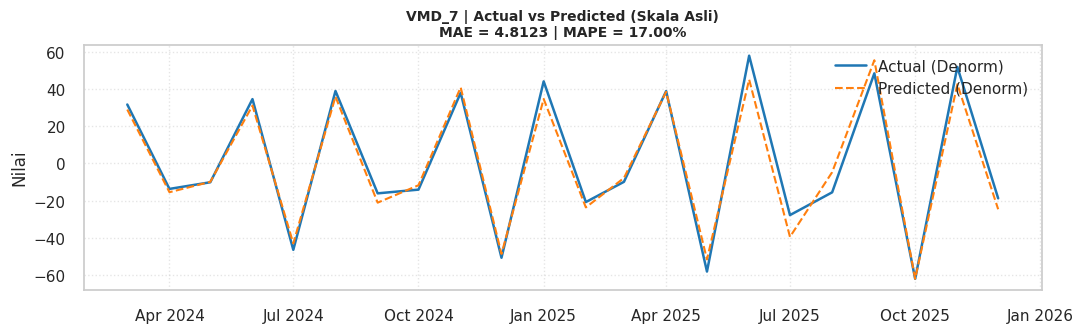

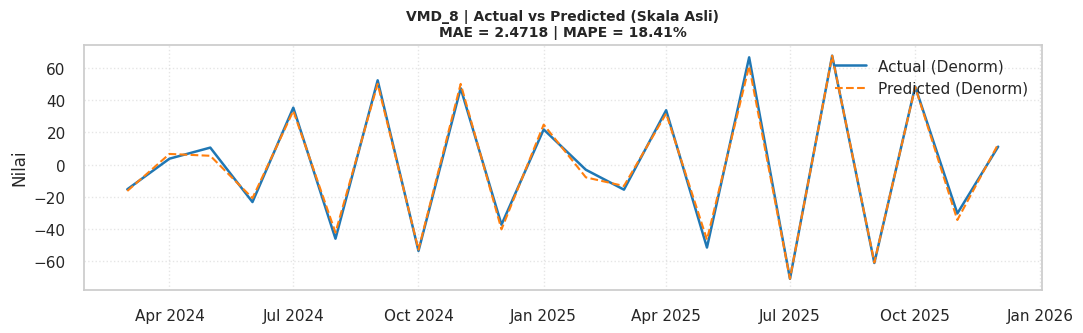

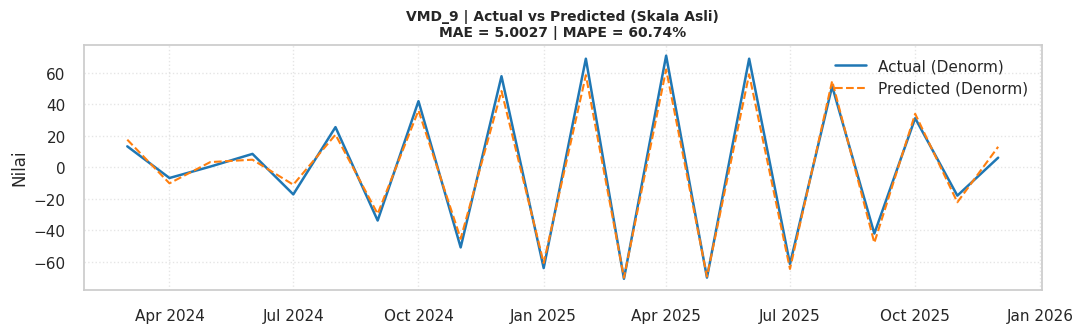

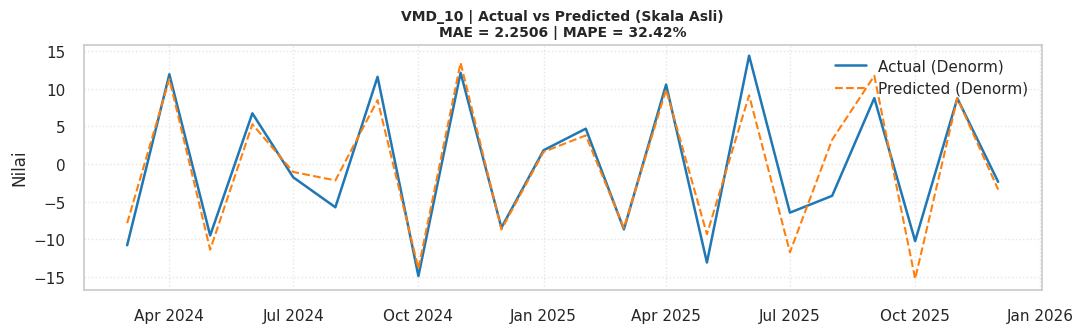

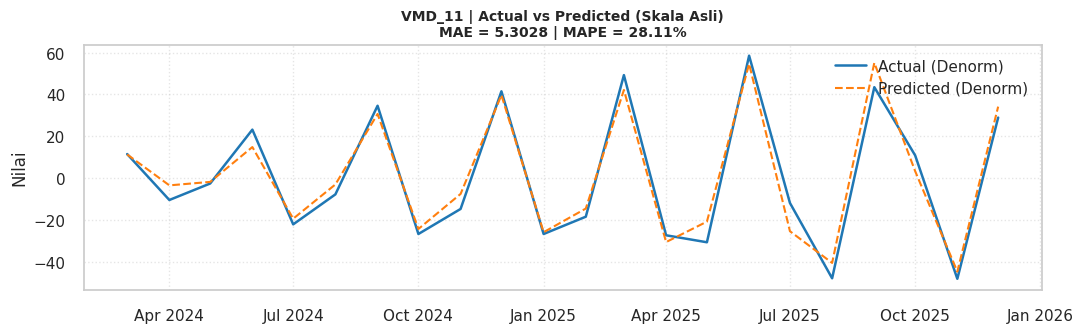

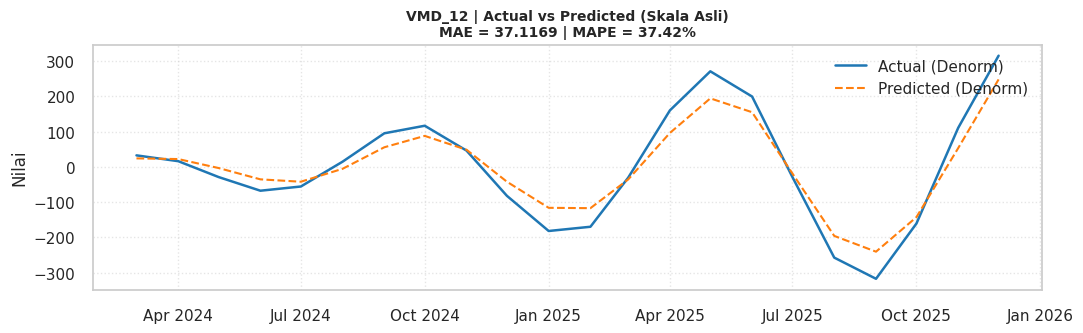


📋 RINGKASAN METRIK EVALUASI PER SUB-MODE:


,Sub-Component,MAE (Denorm),RMSE (Denorm),MAPE (Denorm) %
0,VMD_1,5.826959,6.887002,1.738056
1,VMD_2,31.892860,33.970057,42.462125
2,VMD_3,10.224804,12.130066,44.279087
3,VMD_4,19.257047,22.791209,162.697351
4,VMD_5,14.278740,16.648740,65.531694
5,VMD_6,3.268193,4.141597,12.706907
6,VMD_7,4.812250,6.106019,17.004773
7,VMD_8,2.471836,2.969731,18.412107
8,VMD_9,5.002722,5.672793,60.741829
9,VMD_10,2.250638,3.024927,32.416705



📋 TABEL AKTUAL vs PREDIKSI REKONSTRUKSI (SKALA ASLI PENGUNJUNG)


,Date,Actual,Predicted,Abs_Error
0,2024-03-01,217.0,196.338810,20.661190
1,2024-04-01,286.0,265.089849,20.910151
2,2024-05-01,189.0,194.717847,5.717847
3,2024-06-01,152.0,148.160210,3.839790
4,2024-07-01,168.0,155.808317,12.191683
5,2024-08-01,152.0,115.036457,36.963543
6,2024-09-01,175.0,141.692733,33.307267
7,2024-10-01,169.0,147.420408,21.579592
8,2024-11-01,153.0,168.958181,15.958181
9,2024-12-01,102.0,86.539519,15.460481



✅ HASIL EVALUASI AKHIR REKONSTRUKSI (SKALA ASLI):
   MAE  : 49.81
   RMSE : 65.89
   MAPE : 11.86%


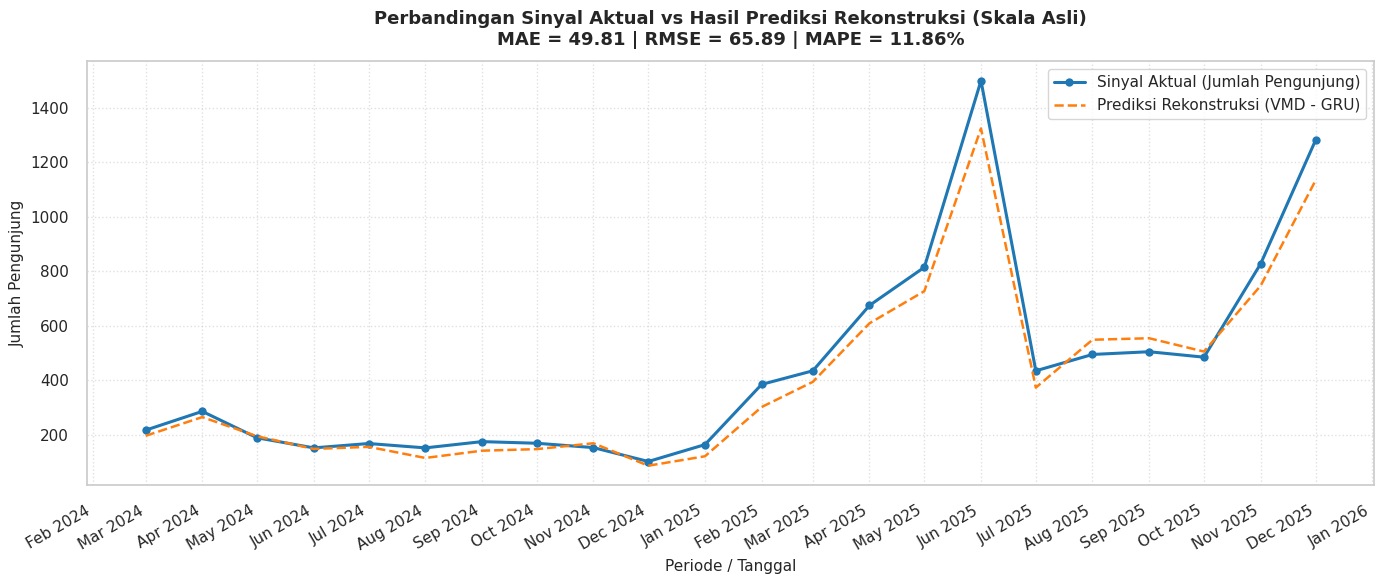


💾 Grafik hasil rekonstruksi skala asli disimpan di: output_hasil/grafik/07_final_reconstruction_prediction_original_scale.png


In [18]:
import os
import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error


# =========================================================
# HELPER FUNCTIONS
# =========================================================
def safe_mape(y_true, y_pred, eps=1e-8):
  """Menghitung Mean Absolute Percentage Error (MAPE) secara aman."""
  y_true = np.asarray(y_true).reshape(-1)
  y_pred = np.asarray(y_pred).reshape(-1)
  denom = np.maximum(np.abs(y_true), eps)
  return float(np.mean(np.abs((y_true - y_pred) / denom)))


def inverse_1d(scaler, arr_1d):
  """Melakukan inverse transform (denormalisasi) pada array 1D."""
  arr_1d = np.asarray(arr_1d).reshape(-1, 1)
  return scaler.inverse_transform(arr_1d).reshape(-1)


# =========================================================
# SETUP DATA TEST & LOKASI FILE
# =========================================================
preds_dir = 'retrain-preds'
scaler_dir = 'scaler'

print('=' * 75)
print('📊 EVALUASI PREDIKSI REKONSTRUKSI DALAM SKALA ASLI (DENORMALIZED)')
print('=' * 75)

# Mengambil seluruh sub-komponen dari hasil tuning/retrain
components = list(best_params.keys())

# Menentukan panjang data test set berdasarkan salah satu file hasil prediksi
sample_comp = components[0]
sample_preds = pd.read_csv(os.path.join(preds_dir, f'preds_{sample_comp}.csv'))
test_len = len(sample_preds)

# Mengambil tanggal dan jumlah pengunjung asli untuk test set
test_dates = data_clean['date'].iloc[-test_len:].values
actual_test_signal = (
    data_clean['visitors'].iloc[-test_len:].values.astype(float)
)

# =========================================================
# 1) EVALUASI & DENORMALISASI PER SUB-MODE
# =========================================================
y_pred_den_dict = {}
imf_metrics_rows = []

print('\n🔍 Evaluasi Prediksi Per Sub-Mode (Skala Asli Sub-Komponen):')

for comp in components:
  pred_path = os.path.join(preds_dir, f'preds_{comp}.csv')
  scaler_path = os.path.join(scaler_dir, f'scaler_{comp}.pkl')

  if not os.path.exists(pred_path):
    print(f'⚠️ File {pred_path} tidak ditemukan, skip...')
    continue

  dfp = pd.read_csv(pred_path)
  y_true_norm = dfp['y_true'].values.astype(float)
  y_pred_norm = dfp['y_pred'].values.astype(float)

  # Denormalisasi nilai prediksi & aktual milik sub-mode ini
  if os.path.exists(scaler_path):
    scaler = joblib.load(scaler_path)
    y_true_den = inverse_1d(scaler, y_true_norm)
    y_pred_den = inverse_1d(scaler, y_pred_norm)
  else:
    y_true_den, y_pred_den = y_true_norm, y_pred_norm

  # Simpan hasil denormalisasi prediksi ke dictionary
  y_pred_den_dict[comp] = y_pred_den

  # Hitung metrik evaluasi sub-mode dalam skala asli
  imf_mae = float(mean_absolute_error(y_true_den, y_pred_den))
  imf_rmse = float(np.sqrt(mean_squared_error(y_true_den, y_pred_den)))
  imf_mape = safe_mape(y_true_den, y_pred_den) * 100.0

  imf_metrics_rows.append({
      'Sub-Component': comp,
      'MAE (Denorm)': imf_mae,
      'RMSE (Denorm)': imf_rmse,
      'MAPE (Denorm) %': imf_mape,
  })

  # Tabel perbandingan individual sub-mode
  df_imf_comp = pd.DataFrame({
      'Date': pd.to_datetime(test_dates),
      'Actual_IMF': y_true_den,
      'Predicted_IMF': y_pred_den,
  })
  df_imf_comp['Abs_Error'] = np.abs(
      df_imf_comp['Actual_IMF'] - df_imf_comp['Predicted_IMF']
  )

  # Visualisasi Individual Sub-Mode
  plt.figure(figsize=(11, 3.5))
  plt.plot(
      test_dates,
      y_true_den,
      label='Actual (Denorm)',
      color='#1f77b4',
      linewidth=1.8,
  )
  plt.plot(
      test_dates,
      y_pred_den,
      label='Predicted (Denorm)',
      color='#ff7f0e',
      linestyle='--',
      linewidth=1.5,
  )
  plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
  plt.title(
      f'{comp} | Actual vs Predicted (Skala Asli)\nMAE = {imf_mae:.4f} | MAPE ='
      f' {imf_mape:.2f}%',
      fontsize=10,
      fontweight='bold',
  )
  plt.ylabel('Nilai')
  plt.legend(loc='upper right')
  plt.grid(True, linestyle=':', alpha=0.5)
  plt.tight_layout()
  plt.show()

# Ringkasan metrik seluruh sub-mode
imf_metrics_df = pd.DataFrame(imf_metrics_rows)
print('\n📋 RINGKASAN METRIK EVALUASI PER SUB-MODE:')
display(imf_metrics_df)

# =========================================================
# 2) REKONSTRUKSI PREDIKSI TOTAL (JUMLAH PENGUNJUNG ASLI)
# =========================================================
# Penjumlahan seluruh hasil denormalisasi mode VMD
x_pred_den_final = np.sum(
    [y_pred_den_dict[c] for c in y_pred_den_dict.keys()], axis=0
)

# Hitung metrik evaluasi akhir (Sinyal Asli Total Pengunjung)
final_mae = float(mean_absolute_error(actual_test_signal, x_pred_den_final))
final_rmse = float(
    np.sqrt(mean_squared_error(actual_test_signal, x_pred_den_final))
)
final_mape = safe_mape(actual_test_signal, x_pred_den_final) * 100.0

# Tabel Hasil Rekonstruksi
df_recon = pd.DataFrame({
    'Date': pd.to_datetime(test_dates),
    'Actual': actual_test_signal.astype(float),
    'Predicted': x_pred_den_final.astype(float),
})
df_recon['Abs_Error'] = np.abs(df_recon['Actual'] - df_recon['Predicted'])

print('\n' + '=' * 75)
print('📋 TABEL AKTUAL vs PREDIKSI REKONSTRUKSI (SKALA ASLI PENGUNJUNG)')
print('=' * 75)
display(df_recon)

print('\n✅ HASIL EVALUASI AKHIR REKONSTRUKSI (SKALA ASLI):')
print(f'   MAE  : {final_mae:.2f}')
print(f'   RMSE : {final_rmse:.2f}')
print(f'   MAPE : {final_mape:.2f}%')

# =========================================================
# 3) VISUALISASI REKONSTRUKSI AKHIR
# =========================================================
plt.figure(figsize=(14, 6))
plt.plot(
    test_dates,
    actual_test_signal,
    label='Sinyal Aktual (Jumlah Pengunjung)',
    color='#1f77b4',
    linewidth=2.2,
    marker='o',
)
plt.plot(
    test_dates,
    x_pred_den_final,
    label='Prediksi Rekonstruksi (VMD - GRU)',
    color='#ff7f0e',
    linestyle='--',
    linewidth=1.8,
    marker='x',
)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()

plt.title(
    'Perbandingan Sinyal Aktual vs Hasil Prediksi Rekonstruksi (Skala'
    ' Asli)\n'
    f'MAE = {final_mae:.2f} | RMSE = {final_rmse:.2f} | MAPE ='
    f' {final_mape:.2f}%',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
plt.xlabel('Periode / Tanggal', fontsize=11)
plt.ylabel('Jumlah Pengunjung', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Simpan Grafik Evaluasi Final Rekonstruksi Skala Asli
os.makedirs('output_hasil/grafik', exist_ok=True)
output_chart_path = (
    'output_hasil/grafik/07_final_reconstruction_prediction_original_scale.png'
)
plt.savefig(output_chart_path, dpi=150, bbox_inches='tight')
plt.show()

print(f'\n💾 Grafik hasil rekonstruksi skala asli disimpan di: {output_chart_path}')

🔮 PROSES PREDIKSI 12 BULAN KE DEPAN (VMD-GRU)
Periode Prediksi: January 2026 s/d December 2026

✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_1
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_2
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_3
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_4
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_5
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_6
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_7
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_8
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_9
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_10
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_11
✅ Prediksi 12 bulan selesai untuk sub-mode: VMD_12

📋 HASIL PREDIKSI JUMLAH PENGUNJUNG 12 BULAN KE DEPAN


,Date,Predicted_Visitors
0,2026-01-01,1131
1,2026-02-01,702
2,2026-03-01,406
3,2026-04-01,571
4,2026-05-01,579
5,2026-06-01,372
6,2026-07-01,867
7,2026-08-01,416
8,2026-09-01,320
9,2026-10-01,72



💾 Hasil prediksi tersimpan di: hasil-prediksi-future/future_predictions_12_months.csv


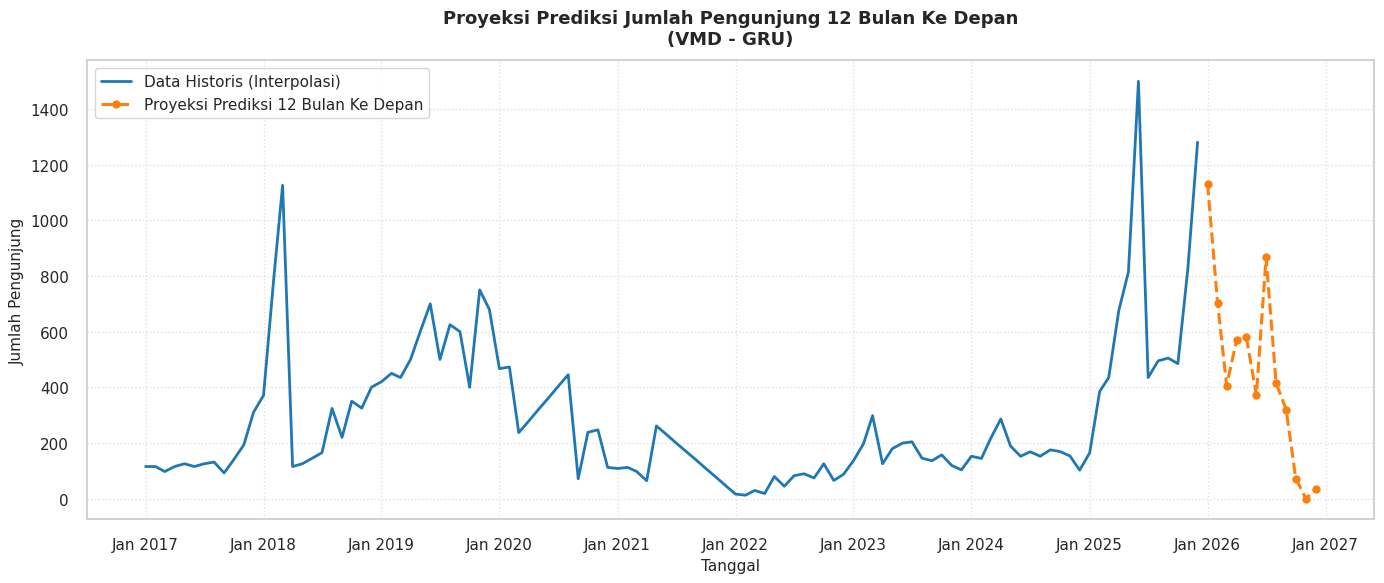

💾 Grafik proyeksi disimpan di: output_hasil/grafik/08_future_predictions_12_months.png


In [19]:
import os
import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tensorflow.keras.models import load_model

# =========================================================
# 1. SETUP & DEFINISI PARAMETER
# =========================================================
future_steps = 12  # Prediksi 12 bulan ke depan
seq_length = 12  # Panjang lag / lookback period (12 bulan)
model_dir = 'retrain-models'
scaler_dir = 'scaler'
components = list(best_params.keys())

# Mengambil tanggal terakhir dari dataset aktual
last_date = pd.to_datetime(data_clean['date'].iloc[-1])

# Membuat rentang tanggal untuk 12 bulan ke depan
future_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1), periods=future_steps, freq='MS'
)

print('=' * 75)
print(f'🔮 PROSES PREDIKSI {future_steps} BULAN KE DEPAN (VMD-GRU)')
print('=' * 75)
print(f'Periode Prediksi: {future_dates[0].strftime("%B %Y")} s/d {future_dates[-1].strftime("%B %Y")}\n')

# =========================================================
# 2. RECURSIVE FORECASTING PER SUB-MODE
# =========================================================
future_preds_den_dict = {}

for comp in components:
  # Path file model & scaler
  model_path = os.path.join(model_dir, f'{comp}_gru_best.keras')
  scaler_path = os.path.join(scaler_dir, f'scaler_{comp}.pkl')

  if not os.path.exists(model_path):
    print(f'⚠️ Model untuk {comp} tidak ditemukan di {model_path}, skip...')
    continue

  # Load model & scaler
  model = load_model(model_path)
  scaler = joblib.load(scaler_path)

  # Ambil 12 data ter-normalisasi terakhir dari sub-mode ini sebagai input awal (seed sequence)
  mode_series_norm = normalized_imfs[comp].values
  curr_seq = mode_series_norm[-seq_length:].copy()

  future_preds_norm = []

  # Iterasi recursive multi-step forecasting
  for _ in range(future_steps):
    # Reshape input ke 3D Keras: (1, 12, 1)
    X_input = curr_seq.reshape(1, seq_length, 1)

    # Prediksi 1 step ke depan
    pred_val = model.predict(X_input, verbose=0)[0, 0]
    pred_val = np.clip(pred_val, 0.0, 1.0)  # Batasi rentang normalisasi [0, 1]

    # Simpan hasil prediksi
    future_preds_norm.append(pred_val)

    # Update sequence (geser sliding window dan append nilai prediksi baru)
    curr_seq = np.append(curr_seq[1:], pred_val)

  # Denormalisasi hasil prediksi sub-mode ke skala aslinya
  future_preds_den = scaler.inverse_transform(
      np.array(future_preds_norm).reshape(-1, 1)
  ).ravel()
  future_preds_den_dict[comp] = future_preds_den

  print(f'✅ Prediksi 12 bulan selesai untuk sub-mode: {comp}')

# =========================================================
# 3. REKONSTRUKSI PREDIKSI FUTURE (SKALA ASLI PENGUNJUNG)
# =========================================================
# Penjumlahan hasil denormalisasi seluruh sub-mode VMD + Residu
future_total_visitors = np.sum(
    [future_preds_den_dict[c] for c in future_preds_den_dict.keys()], axis=0
)

# Memastikan tidak ada nilai prediksi negatif pada skala asli
future_total_visitors = np.maximum(future_total_visitors, 0)

# DataFrame Hasil Prediksi 12 Bulan Ke Depan
df_future = pd.DataFrame({
    'Date': future_dates,
    'Predicted_Visitors': np.round(future_total_visitors).astype(int),
})

print('\n' + '=' * 75)
print('📋 HASIL PREDIKSI JUMLAH PENGUNJUNG 12 BULAN KE DEPAN')
print('=' * 75)
display(df_future)

# Simpan Hasil Prediksi Ke CSV
output_future_dir = 'hasil-prediksi-future'
os.makedirs(output_future_dir, exist_ok=True)
csv_future_path = os.path.join(
    output_future_dir, 'future_predictions_12_months.csv'
)
df_future.to_csv(csv_future_path, index=False)
print(f'\n💾 Hasil prediksi tersimpan di: {csv_future_path}')

# =========================================================
# 4. VISUALISASI PROYEKSI PREDIKSI 12 BULAN KE DEPAN
# =========================================================
plt.figure(figsize=(14, 6))

# Plot Data Historis Pengunjung
plt.plot(
    data_clean['date'],
    data_clean['visitors'],
    label='Data Historis (Interpolasi)',
    color='#1f77b4',
    linewidth=2,
)

# Plot Prediksi 12 Bulan Ke Depan
plt.plot(
    df_future['Date'],
    df_future['Predicted_Visitors'],
    label='Proyeksi Prediksi 12 Bulan Ke Depan',
    color='#ff7f0e',
    linestyle='--',
    linewidth=2.2,
    marker='o',
)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.title(
    'Proyeksi Prediksi Jumlah Pengunjung 12 Bulan Ke Depan\n(VMD - GRU)'
    '',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
plt.xlabel('Tanggal', fontsize=11)
plt.ylabel('Jumlah Pengunjung', fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Simpan Grafik Prediksi Future
os.makedirs('output_hasil/grafik', exist_ok=True)
output_chart_future = (
    'output_hasil/grafik/08_future_predictions_12_months.png'
)
plt.savefig(output_chart_future, dpi=150, bbox_inches='tight')
plt.show()

print(f'💾 Grafik proyeksi disimpan di: {output_chart_future}')

In [20]:
# simpan seluruh output kaggle
!zip -r output_kaggle.zip .

  adding: retrain-results/ (stored 0%)
  adding: retrain-results/retrain_test_results_per_imf.csv (deflated 60%)
  adding: retrain-results/retrain_gru_hasil_lengkap.xlsx (deflated 8%)
  adding: normalisasi-hasil-interpolasi/ (stored 0%)
  adding: normalisasi-hasil-interpolasi/data_cleaned_after_imputation_minmax_0_1.xlsx (deflated 9%)
  adding: hasil-prediksi-future/ (stored 0%)
  adding: hasil-prediksi-future/future_predictions_12_months.csv (deflated 48%)
  adding: retrain-models/ (stored 0%)
  adding: retrain-models/VMD_1_gru_best.keras (deflated 81%)
  adding: retrain-models/VMD_8_gru_best.keras (deflated 50%)
  adding: retrain-models/VMD_5_gru_best.keras (deflated 18%)
  adding: retrain-models/VMD_11_gru_best.keras (deflated 18%)
  adding: retrain-models/VMD_12_gru_best.keras (deflated 65%)
  adding: retrain-models/VMD_10_gru_best.keras (deflated 65%)
  adding: retrain-models/VMD_7_gru_best.keras (deflated 18%)
  adding: retrain-models/VMD_9_gru_best.keras (deflated 18%)
  adding: